In [ ]:
# Cell 0 — Setup and run configuration
import os, sys, warnings
warnings.filterwarnings("ignore")

IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
IN_COLAB  = "google.colab" in sys.modules
OUT = ("/kaggle/working/dpgbc_out" if IN_KAGGLE
       else "/content/dpgbc_out" if IN_COLAB else "./dpgbc_out")
CACHE = os.path.join(OUT, "openml_cache")
os.makedirs(CACHE, exist_ok=True)

# ---- run configuration ----
QUICK       = False   # True = 2 seeds / 4 parity seeds, for a smoke test (minutes)
RUN_SYNTH   = True    # MST/AIM on parity tasks (Cell 17), slow (~15 min)
RUN_50K     = True    # 50,000-record parity (Cell 15), ~20-40 min
print(f"env: {'Kaggle' if IN_KAGGLE else 'Colab' if IN_COLAB else 'local'} | OUT={OUT} | QUICK={QUICK}")

env: Colab | OUT=/content/dpgbc_out | QUICK=False


In [ ]:
# Cell 1 — Imports, seeds, constants
import time, zlib, itertools
import numpy as np, pandas as pd
from scipy.stats import wilcoxon, spearmanr, ks_2samp, norm
from scipy.optimize import brentq
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score
from statsmodels.stats.multitest import multipletests

TOTAL_EPS  = 3.0
SEEDS      = [42, 123, 456, 789, 101]
TUNE_SEEDS = [1, 2, 3]
PAR_SEEDS  = [42, 123, 456, 789, 101, 202, 303, 404, 505, 606]
if QUICK:
    SEEDS, TUNE_SEEDS, PAR_SEEDS = SEEDS[:2], TUNE_SEEDS[:1], PAR_SEEDS[:4]

# ---- reduced dataset lists ----
PRIMARY = ["Banknote","BreastCancer","Ionosphere","MAGIC04","PimaDiabetes",
           "Sonar","Wine"]
SUPP = ["Covertype","CreditG","HeartCleveland"]

def mk_rng(seed, tag):
    """Reproducible, process-independent RNG per (seed, tag)."""
    return np.random.default_rng([int(seed), zlib.crc32(tag.encode())])

def save(df, name):
    p = os.path.join(OUT, name); df.to_csv(p, index=False); print("saved", p, df.shape)

In [ ]:
import pandas as pd
import numpy as np
import time
from sklearn.datasets import fetch_openml

def fetch_openml_safe_v2(data_id, retries=4, base_delay=10, cache_home='.'):
    """
    改进版的获取函数：
    1. 首先尝试从静态 CDN 直接下载 .arff 文件（最稳定）。
    2. 如果静态链接失败，再回退到标准的 fetch_openml API。
    """
    # 构建静态 ARFF 文件的 URL
    # OpenML 的 ID 需要格式化为 4 位数字，例如 37 -> 0000/0037
    id_str = str(data_id).zfill(4)
    static_url = f"https://data.openml.org/datasets/{id_str[:4]}/{id_str}/dataset_{data_id}.arff"

    last_err = None
    for attempt in range(retries):
        try:
            print(f"  尝试通过静态链接下载 (尝试 {attempt+1}/{retries}): {static_url}")
            # 直接读取 ARFF 文件
            df = pd.read_csv(static_url, comment='@', header=None)
            # 注意：ARFF 格式需要特殊解析，这里仅为示意。
            # 更稳妥的方式是下载到本地，然后用 scipy.io.arff.loadarff 解析。
            # 为了简化，这里假设你能处理 ARFF 格式。
            # 实际上，更推荐下面的回退方案。
            raise NotImplementedError("ARFF 解析需要额外步骤，此处直接回退到标准API")
        except Exception as e:
            last_err = e
            print(f"  静态链接失败: {e}")
            # 回退到标准的 fetch_openml
            try:
                print(f"  回退到 fetch_openml API (尝试 {attempt+1}/{retries})...")
                return fetch_openml(data_id=data_id, as_frame=True, parser="auto", data_home=cache_home)
            except Exception as api_err:
                last_err = api_err
                wait = base_delay * (2 ** attempt)
                print(f"  本次尝试失败 ({type(api_err).__name__}: {api_err})，{wait}秒后重试...")
                time.sleep(wait)

    raise last_err

In [ ]:
# Cell 2 — Dataset loading (10 datasets, cached)
import socket
from sklearn.datasets import load_breast_cancer, fetch_openml
socket.setdefaulttimeout(180)

def fetch_safe(data_id, retries=4, delay=10):
    err = None
    for a in range(retries):
        try:
            try:
                return fetch_openml(data_id=data_id, as_frame=True,
                                    parser="auto", data_home=CACHE)
            except TypeError:
                # Some ARFF files fail under "auto" (e.g. data_id 1464); "pandas" is more robust
                return fetch_openml(data_id=data_id, as_frame=True,
                                    parser="pandas", data_home=CACHE)
        except Exception as e:
            err = e; w = delay * 2**a
            print(f"  attempt {a+1}/{retries} failed ({type(e).__name__}); retry in {w}s"); time.sleep(w)
    raise err

NA = ["?","NA","N/A","na","n/a","null","None","","nan"]
def prepare(X, y, max_rows=None, seed=42):
    X = X.copy(); y = pd.Series(y).astype(str).str.strip().replace(NA, np.nan)
    m = y.notna(); X, y = X[m].reset_index(drop=True), y[m].reset_index(drop=True)
    for c in X.columns:
        num = pd.to_numeric(X[c], errors="coerce")
        if num.notna().mean() > 0.90: X[c] = num
        else:
            cat = X[c].astype(str).str.strip().replace(NA, np.nan)
            X[c] = pd.Categorical(cat).codes.astype(float); X.loc[cat.isna(), c] = np.nan
    X = X.dropna(); y = y.loc[X.index].reset_index(drop=True); X = X.reset_index(drop=True)
    X = X.loc[:, X.nunique() > 1]
    ye = pd.Series(pd.factorize(y)[0], name="target")
    assert len(X) >= 100 and ye.nunique() >= 2
    if max_rows and len(X) > max_rows:
        X, _, ye, _ = train_test_split(X, ye, train_size=max_rows/len(X), random_state=seed, stratify=ye)
        X, ye = X.reset_index(drop=True), ye.reset_index(drop=True)
    return X, ye

# public class counts (reduced to the 10 kept datasets)
NCLS = {"BreastCancer":2,"PimaDiabetes":2,"HeartCleveland":2,"CreditG":2,
        "MAGIC04":2,"Banknote":2,"Covertype":7,
        "Ionosphere":2,"Sonar":2,"Wine":3}

# 9 OpenML datasets (BreastCancer comes from sklearn, not OpenML)
OPENML = [(37,  "PimaDiabetes",   None),
          (59,  "Ionosphere",     None),
          (40,  "Sonar",          None),
          (187, "Wine",           None),
          (1462,"Banknote",       None),
          (1120,"MAGIC04",        6000),
          (49,  "HeartCleveland", None),
          (31,  "CreditG",        None),
          (150, "Covertype",      6000)]

DATA, CARD = {}, {}
bc = load_breast_cancer()
DATA["BreastCancer"] = prepare(pd.DataFrame(bc.data, columns=bc.feature_names), bc.target)
for did, name, mr in OPENML:
    try:
        d = fetch_safe(did)
        CARD[name] = {c: len(d.data[c].cat.categories) for c in d.data.columns if hasattr(d.data[c], "cat")}
        DATA[name] = prepare(d.data, d.target, max_rows=mr)
        X, y = DATA[name]
        print(f"OK {name:<18} n={len(X):<6} d={X.shape[1]:<3} K={y.nunique()} "
              f"min/max class prop={y.value_counts(normalize=True).min():.3f}/{y.value_counts(normalize=True).max():.3f}")
        assert y.max() < NCLS[name], f"{name}: label index exceeds public K"
    except Exception as e:
        print(f"SKIP {name}: {e}")
    time.sleep(2)

missing = [d for d in PRIMARY + SUPP if d not in DATA]
assert not missing, f"missing datasets: {missing}"
print(len(DATA), "datasets loaded")

OK PimaDiabetes       n=768    d=8   K=2 min/max class prop=0.349/0.651
OK Ionosphere         n=351    d=33  K=2 min/max class prop=0.359/0.641
OK Sonar              n=208    d=60  K=2 min/max class prop=0.466/0.534
OK Wine               n=178    d=13  K=3 min/max class prop=0.270/0.399
OK Banknote           n=1372   d=4   K=2 min/max class prop=0.445/0.555
OK MAGIC04            n=6000   d=10  K=2 min/max class prop=0.352/0.648
OK HeartCleveland     n=296    d=13  K=2 min/max class prop=0.459/0.541
OK CreditG            n=1000   d=20  K=2 min/max class prop=0.300/0.700
OK Covertype          n=6000   d=54  K=7 min/max class prop=0.005/0.488
10 datasets loaded


In [ ]:
# Cell 3 — Public feature bounds (10-dataset version)
PUBLIC_BOUNDS = {
 "BreastCancer": {"mean radius":(6.981,28.11),"mean texture":(9.71,39.28),"mean perimeter":(43.79,188.5),
  "mean area":(143.5,2501.0),"mean smoothness":(0.05263,0.1634),"mean compactness":(0.01938,0.3454),
  "mean concavity":(0.0,0.4268),"mean concave points":(0.0,0.2012),"mean symmetry":(0.106,0.304),
  "mean fractal dimension":(0.04996,0.09744),"radius error":(0.1115,2.873),"texture error":(0.3602,4.885),
  "perimeter error":(0.757,21.98),"area error":(6.802,542.2),"smoothness error":(0.001713,0.03113),
  "compactness error":(0.002252,0.1354),"concavity error":(0.0,0.396),"concave points error":(0.0,0.05279),
  "symmetry error":(0.007882,0.07895),"fractal dimension error":(0.0008948,0.02984),
  "worst radius":(7.93,36.04),"worst texture":(12.02,49.54),"worst perimeter":(50.41,251.2),
  "worst area":(185.2,4254.0),"worst smoothness":(0.07117,0.2226),"worst compactness":(0.02729,1.058),
  "worst concavity":(0.0,1.252),"worst concave points":(0.0,0.291),"worst symmetry":(0.1565,0.6638),
  "worst fractal dimension":(0.05504,0.2075)},
 "PimaDiabetes": {"preg":(0,17),"plas":(0,199),"pres":(0,122),"skin":(0,99),"insu":(0,846),
  "mass":(0.0,67.1),"pedi":(0.078,2.42),"age":(21,81)},
 "MAGIC04": {"fLength:":(10.89,317.98),"fWidth:":(5.29,262.96),"fSize:":(0.4,1028.0),"fConc:":(0.05,0.99),
  "fConc1:":(0.0,0.94),"fAsym:":(-24.68,24.68),"fM3Long:":(-331.0,331.0),"fM3Trans:":(-331.0,331.0),
  "fAlpha:":(0.0,90.0),"fDist:":(20.0,500.0)},
 "Banknote": {"V1":(-7.0421,6.8248),"V2":(-13.7731,12.9516),"V3":(-5.2861,17.9274),"V4":(-8.5482,2.4495)},
 "Ionosphere": {**{f"a{str(i).zfill(2)}":(-1.0,1.0) for i in range(1,35)}, **{f"V{i}":(-1.0,1.0) for i in range(1,35)}},
 "Sonar": {**{f"V{i}":(0.0,1.0) for i in range(1,61)}, **{f"attribute_{i}":(0.0,1.0) for i in range(1,61)}},
 "Wine": {"Alcohol":(11.03,14.83),"Malic_acid":(0.74,5.80),"Ash":(1.36,3.23),"Alcalinity_of_ash":(10.6,30.0),
  "Magnesium":(70,162),"Total_phenols":(0.98,3.88),"Flavanoids":(0.34,5.08),"Nonflavanoid_phenols":(0.13,0.66),
  "Proanthocyanins":(0.41,3.58),"Color_intensity":(1.28,13.0),"Hue":(0.48,1.71),
  "OD280%2FOD315_of_diluted_wines":(1.27,4.00),"Proline":(278,1680)},
}

def public_bounds_for(name, X, widen=1.0):
    """PRIMARY: documented/declared bounds (error if a column is uncovered).
       SUPP: observed extremes -> used ONLY for tuning/runtime, never for headline results.
       widen>1 stretches the interval around its centre (bounds-sensitivity study)."""
    if name in SUPP:
        lo = X.min().astype(float).values; hi = X.max().astype(float).values
        hi = np.where(hi > lo, hi, lo + 1.0)
    else:
        doc, cards = PUBLIC_BOUNDS[name], CARD.get(name, {})
        lo, hi = np.zeros(X.shape[1]), np.ones(X.shape[1])
        for j, c in enumerate(X.columns):
            if c in doc: lo[j], hi[j] = doc[c]
            elif c in cards: lo[j], hi[j] = 0, cards[c] - 1
            else: raise KeyError(f"{name}: no public bound for column {c!r}")
    if widen != 1.0:
        mid = (lo + hi) / 2; lo, hi = mid - widen*(mid - lo), mid + widen*(hi - mid)
    return lo, hi

def scale_pb(X, lo, hi):
    A = X.values if hasattr(X, "values") else np.asarray(X)
    return np.clip((A - lo) / np.maximum(hi - lo, 1e-6), 0, 1)

for nm in PRIMARY: public_bounds_for(nm, DATA[nm][0])      # raises if any column is uncovered
print("bounds OK for all primary datasets")

_SPLIT = {}
def get_split(ds, seed, widen=1.0):
    key = (ds, seed, widen)
    if key not in _SPLIT:
        X, y = DATA[ds]; lo, hi = public_bounds_for(ds, X, widen)
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=seed, stratify=y)
        _SPLIT[key] = (scale_pb(Xtr, lo, hi), scale_pb(Xte, lo, hi), ytr.values, yte.values, Xtr.values, Xte.values)
    return _SPLIT[key]

bounds OK for all primary datasets


In [ ]:
# Cell 4 — DP-GBC mechanisms: partition, controls, release, heads
# NEIGHBOURING RELATION: add/remove one record. All count sensitivities are 1.

def mk_cfg(eps, L, ec, es=None, tau=0.9, T=8):
    es = ec if es is None else es
    er = eps - (L + 1)*ec - L*es
    assert er > 0.0099, (eps, L, ec, es, er)
    return dict(eps=eps, L=L, ec=ec, es=es, er=er, tau=tau, T=T)
def cfg_total(c): return (c["L"]+1)*c["ec"] + c["L"]*c["es"] + c["er"]
def scale_cfg(c, eps):
    s = eps / c["eps"]; return dict(c, eps=eps, ec=c["ec"]*s, es=c["es"]*s, er=c["er"]*s)

def em_select(rng, scores, eps, div=2.0):
    s = np.asarray(scores, float); lg = eps*s/div; lg -= lg.max()
    p = np.exp(lg); p /= p.sum(); return int(rng.choice(len(s), p=p))

def candidate_scores(Xn, Yn, lo, hi, T, score):
    """Candidate (feature, threshold) pairs from PUBLIC box geometry + their scores.
       majority: max class count left + right  (sensitivity 1, monotone under add/remove)
       balance : -|nL-nR|                      (sensitivity 1, NOT monotone -> factor 2 required)"""
    cands, scs = [], []; tot = Yn.sum(0)
    for f in range(Xn.shape[1]):
        if hi[f] - lo[f] < 1e-9: continue
        ts = np.linspace(lo[f], hi[f], T + 2)[1:-1]
        left = Xn[:, f][:, None] <= ts[None, :]
        if score == "majority":
            cl = left.T.astype(float) @ Yn
            sc = cl.max(1) + (tot[None, :] - cl).max(1)
        else:
            sc = -np.abs(2*left.sum(0) - len(Xn)).astype(float)
        cands += [(f, float(t)) for t in ts]; scs += list(sc)
    return cands, scs

def build_partition(X, y, K, L, ec, es, rng, tau=0.9, min_size=10, T=8, score="majority", em_div=2.0):
    """Class-aware private partition. Cost = (L+1)*ec + L*es (parallel within depth, sequential across)."""
    n, d = X.shape; Y = np.eye(K)[y]; leaves = []
    div = em_div if score == "majority" else 2.0      # factor-2 removal is valid only for monotone scores
    queue = [(np.arange(n), 0, np.zeros(d), np.ones(d))]
    while queue:
        idx, dep, lo, hi = queue.pop(0)
        nc = np.clip(Y[idx].sum(0) + rng.laplace(0, 1/ec, K), 0, None) + 1.0     # post-processing: clip, +1
        leaf = dict(lo=lo, hi=hi, n=len(idx), nc=nc, center=(lo+hi)/2, depth=dep)
        if nc.max()/nc.sum() >= tau or nc.sum() < min_size or dep >= L:
            leaves.append(leaf); continue
        Xn, Yn = X[idx], Y[idx]
        cands, scs = candidate_scores(Xn, Yn, lo, hi, T, score)
        if not cands: leaves.append(leaf); continue
        f, t = cands[em_select(rng, scs, es, div)]
        m = Xn[:, f] <= t
        l_hi = hi.copy(); l_hi[f] = t; r_lo = lo.copy(); r_lo[f] = t
        queue.append((idx[m],  dep+1, lo.copy(), l_hi))
        queue.append((idx[~m], dep+1, r_lo, hi.copy()))
    return leaves

def build_grid(X, y, K, depth, eps_count, rng, mode="first"):
    """Public-split partitions (no split budget). mode: first | rand (random tie-break) | split (random feature+threshold)."""
    n, d = X.shape; Y = np.eye(K)[y]; leaves = []
    queue = [(np.arange(n), 0, np.zeros(d), np.ones(d))]
    while queue:
        idx, dep, lo, hi = queue.pop(0)
        if dep >= depth:
            nc = np.clip(Y[idx].sum(0) + rng.laplace(0, 1/eps_count, K), 0, None) + 1.0
            leaves.append(dict(lo=lo, hi=hi, n=len(idx), nc=nc, center=(lo+hi)/2, depth=dep)); continue
        w = hi - lo
        if mode == "first":  f = int(np.argmax(w)); t = 0.5*(lo[f] + hi[f])
        elif mode == "rand": f = int(rng.choice(np.flatnonzero(np.isclose(w, w.max())))); t = 0.5*(lo[f] + hi[f])
        else:                f = int(rng.integers(len(w))); t = float(rng.uniform(lo[f], hi[f]))
        m = X[idx, f] <= t
        l_hi = hi.copy(); l_hi[f] = t; r_lo = lo.copy(); r_lo[f] = t
        queue.append((idx[m],  dep+1, lo.copy(), l_hi)); queue.append((idx[~m], dep+1, r_lo, hi.copy()))
    return leaves

def release_leaves(leaves, er, rng, K, d):
    """Noisy leaf sizes (one Laplace vector, l1-sens 1, cost er) + uniform sampling in boxes (post-processing)."""
    Xs, ys = [], []
    for lf in leaves:
        m = max(0, int(round(lf["n"] + rng.laplace(0, 1/er))))
        if m == 0: continue
        Xs.append(rng.uniform(lf["lo"], lf["hi"], size=(m, d)))
        ys.append(rng.choice(K, size=m, p=lf["nc"]/lf["nc"].sum()))
    return (np.vstack(Xs), np.concatenate(ys)) if Xs else (np.empty((0, d)), np.empty(0, int))

def _match(lf, X):                      # half-open box: (lo, hi], root edge lo=0 inclusive -- same rule as the builder
    return np.all(((X > lf["lo"]) | (lf["lo"] <= 0)) & (X <= lf["hi"]), axis=1)

def route_exact(leaves, X):
    pred = np.full(len(X), -1)
    for lf in leaves:
        m = _match(lf, X) & (pred < 0); pred[m] = int(np.argmax(lf["nc"]))
    assert (pred >= 0).all(), "unrouted test points"
    return pred

def direct_pred(leaves, X):
    C = np.array([lf["center"] for lf in leaves]); lab = np.array([int(np.argmax(lf["nc"])) for lf in leaves])
    d2 = ((X[:, None, :] - C[None, :, :])**2).sum(2); return lab[d2.argmin(1)]

In [ ]:
# Cell 5 — Baselines, heads and evaluation helpers
ba = balanced_accuracy_score
FINAL = mk_cfg(3.0, 3, 0.4)           # default; Cell 7 overwrites it with the SUPP-selected configuration
BASE  = mk_cfg(3.0, 3, 0.1)

def lr_head(Xs, ys, Xte, yte, K):
    if len(ys) == 0 or len(np.unique(ys)) < 2: return 1.0/K          # constant predictor = chance
    return ba(yte, LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xs, ys).predict(Xte))
def rf_head(Xs, ys, Xte, yte, K, seed):
    if len(ys) == 0 or len(np.unique(ys)) < 2: return 1.0/K
    return ba(yte, RandomForestClassifier(100, class_weight="balanced", random_state=seed, n_jobs=-1).fit(Xs, ys).predict(Xte))

def fidelity(Xr, Xs):
    if len(Xs) < 2: return np.nan, np.nan
    ks = np.mean([ks_2samp(Xr[:, j], Xs[:, j])[0] for j in range(Xr.shape[1])])
    with np.errstate(all="ignore"):
        cr, cs = np.corrcoef(Xr, rowvar=False), np.corrcoef(Xs, rowvar=False)
    iu = np.triu_indices_from(cr, 1); return ks, np.nanmean(np.abs(cr[iu] - cs[iu]))

# ---- class-conditional histogram (pure eps-DP): counts (eps*0.1) + per-class per-feature hist (l1-sens d) ----
def hist_release(X, y, K, eps, rng, nb=10, frac=0.1):
    d = X.shape[1]; ec, eh = eps*frac, eps*(1-frac)
    nc = np.clip(np.bincount(y, minlength=K) + rng.laplace(0, 1/ec, K), 0, None)
    edges = np.linspace(0, 1, nb+1); h = np.zeros((K, d, nb))
    for c in range(K):
        for j in range(d): h[c, j] = np.histogram(X[y == c, j], bins=edges)[0]
    return nc, np.clip(h + rng.laplace(0, d/eh, h.shape), 0, None)

def hist_sample(nc, nh, rng, nb=10):
    K, d, _ = nh.shape; tot = nc.sum()
    if tot <= 0: return np.empty((0, d)), np.empty(0, int)
    ys = rng.choice(K, size=int(round(tot)), p=nc/tot); Xs = np.zeros((len(ys), d)); edges = np.linspace(0, 1, nb+1)
    for c in range(K):
        ii = np.where(ys == c)[0]
        for j in range(d):
            h = nh[c, j]; p = h/h.sum() if h.sum() > 0 else np.ones(nb)/nb
            b = rng.choice(nb, size=len(ii), p=p); Xs[ii, j] = rng.uniform(edges[b], edges[b+1])
    return Xs, ys

def nb_predict(nc, nh, X, nb=10):
    """Naive Bayes read DIRECTLY from the same noisy histogram release (post-processing, no extra budget)."""
    K, d, _ = nh.shape
    logp = np.log((nh + 0.5) / (nh + 0.5).sum(2, keepdims=True))
    b = np.minimum((X*nb).astype(int), nb-1)
    ll = np.log((nc + 1)/(nc + 1).sum())[:, None] + sum(logp[:, j, b[:, j]] for j in range(d))
    return ll.argmax(0)

def analytic_sigma(eps, delta, sens=1.0):
    f = lambda s: norm.cdf(sens/(2*s) - eps*s/sens) - np.exp(eps)*norm.cdf(-sens/(2*s) - eps*s/sens) - delta
    return brentq(f, 1e-3, 100.0)

# ---- evaluation runners (long-format DataFrames: Dataset, Seed, tag + metric columns) ----
def _score_leaves(leaves, er, rng, K, Xte, yte, Xtr=None):
    d = Xte.shape[1]; t0 = time.perf_counter()
    Xs, ys = release_leaves(leaves, er, rng, K, d); t_rel = time.perf_counter() - t0
    r = dict(lr=lr_head(Xs, ys, Xte, yte, K), route=ba(yte, route_exact(leaves, Xte)),
             direct=ba(yte, direct_pred(leaves, Xte)), mn=len(Xs)/max(1, sum(l["n"] for l in leaves)), t_rel=t_rel)
    if Xtr is not None: r["ks"], r["corr"] = fidelity(Xtr, Xs)
    return r

def evaluate_gbc(tag, cfg, datasets_list=PRIMARY, seeds=SEEDS, score="majority", em_div=2.0, widen=1.0, fid=False):
    if not cfg.get("nonpriv"): assert abs(cfg_total(cfg) - cfg["eps"]) < 1e-9, (tag, cfg_total(cfg), cfg["eps"])
    rows = []
    for ds in datasets_list:
        K = NCLS[ds]
        for seed in seeds:
            Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed, widen); rng = mk_rng(seed, f"{tag}|{ds}")
            t0 = time.perf_counter()
            leaves = build_partition(Xtr, ytr, K, cfg["L"], cfg["ec"], cfg["es"], rng, cfg["tau"],
                                     T=cfg.get("T", 8), score=score, em_div=em_div)
            tb = time.perf_counter() - t0
            r = _score_leaves(leaves, cfg["er"], rng, K, Xte, yte, Xtr if fid else None)
            r.update(Dataset=ds, Seed=seed, tag=tag, time=tb + r.pop("t_rel")); rows.append(r)
    return pd.DataFrame(rows)

def evaluate_grid(tag, depth, eps_count, eps, mode, datasets_list=PRIMARY, seeds=SEEDS, widen=1.0):
    rows = []
    for ds in datasets_list:
        K = NCLS[ds]
        for seed in seeds:
            Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed, widen); rng = mk_rng(seed, f"{tag}|{ds}")
            leaves = build_grid(Xtr, ytr, K, depth, eps_count, rng, mode)
            r = _score_leaves(leaves, eps - eps_count, rng, K, Xte, yte); r.pop("t_rel")
            r.update(Dataset=ds, Seed=seed, tag=tag); rows.append(r)
    return pd.DataFrame(rows)

def evaluate_hist(tag, eps=TOTAL_EPS, datasets_list=PRIMARY, seeds=SEEDS, widen=1.0, fid=False):
    rows = []
    for ds in datasets_list:
        K = NCLS[ds]
        for seed in seeds:
            Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed, widen); rng = mk_rng(seed, f"{tag}|{ds}")
            nc, nh = hist_release(Xtr, ytr, K, eps, rng); Xs, ys = hist_sample(nc, nh, rng)
            r = dict(Dataset=ds, Seed=seed, tag=tag, lr=lr_head(Xs, ys, Xte, yte, K), nb=ba(yte, nb_predict(nc, nh, Xte)))
            if fid: r["ks"], r["corr"] = fidelity(Xtr, Xs)
            rows.append(r)
    return pd.DataFrame(rows)

def evaluate_flat(tag="flat", eps=TOTAL_EPS, delta=1e-5, datasets_list=PRIMARY, seeds=SEEDS):
    s1 = analytic_sigma(eps, delta); rows = []          # feature perturbation only; labels in the clear (NOT record-level DP)
    for ds in datasets_list:
        K = NCLS[ds]
        for seed in seeds:
            Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed); rng = mk_rng(seed, f"{tag}|{ds}")
            Xs = Xtr + rng.normal(0, s1*np.sqrt(Xtr.shape[1]), Xtr.shape)
            rows.append(dict(Dataset=ds, Seed=seed, tag=tag, lr=lr_head(Xs, ytr, Xte, yte, K)))
    return pd.DataFrame(rows)

def evaluate_oracles(datasets_list=PRIMARY, seeds=SEEDS):
    rows = []
    for ds in datasets_list:
        K = NCLS[ds]
        for seed in seeds:
            Xtr, Xte, ytr, yte, Rtr, Rte = get_split(ds, seed); sc = MinMaxScaler().fit(Rtr)
            rows.append(dict(Dataset=ds, Seed=seed, tag="oracle_minmax", lr=lr_head(sc.transform(Rtr), ytr, sc.transform(Rte), yte, K)))
            rows.append(dict(Dataset=ds, Seed=seed, tag="oracle_pb",     lr=lr_head(Xtr, ytr, Xte, yte, K)))
    return pd.DataFrame(rows)

# ---- statistics helpers ----
def S(df, tag, col): return df[df.tag == tag].set_index(["Dataset", "Seed"])[col]
def DM(df, tag, col): return S(df, tag, col).groupby(level=0).mean()

def paired(a, b, boot=True, nboot=10000, seed=0):
    j = pd.concat([a, b], axis=1, keys=["a", "b"]).dropna(); d = (j.a - j.b).values
    p = wilcoxon(j.a, j.b)[1] if (d != 0).any() else 1.0
    out = dict(mean_a=j.a.mean(), mean_b=j.b.mean(), diff=d.mean(), wins=int((d > 0).sum()), n=len(d), p=p)
    if boot:
        r = np.random.default_rng(seed); bm = d[r.integers(0, len(d), (nboot, len(d)))].mean(1)
        out["ci_lo"], out["ci_hi"] = np.percentile(bm, [2.5, 97.5])
    return out
print("helpers ready")

helpers ready


In [ ]:
# Cell 6 — Self-tests (sensitivity, routing, budget)
rng = np.random.default_rng(0)
# 1) sensitivity of the scores under add/remove: majority in {0,1} (monotone), balance in [-1,1]
for trial in range(200):
    n, d, K = 60, 3, 3
    X = rng.random((n, d)); y = rng.integers(0, K, n); Y = np.eye(K)[y]
    x_new = rng.random((1, d)); Y_new = np.eye(K)[rng.integers(0, K, 1)]
    X2, Y2 = np.vstack([X, x_new]), np.vstack([Y, Y_new])
    for sc in ("majority", "balance"):
        c1, s1 = candidate_scores(X,  Y,  np.zeros(d), np.ones(d), 8, sc)
        c2, s2 = candidate_scores(X2, Y2, np.zeros(d), np.ones(d), 8, sc)
        diff = np.array(s2) - np.array(s1)
        assert c1 == c2
        assert (diff >= 0).all() and (diff <= 1).all() if sc == "majority" else (np.abs(diff) <= 1).all(), sc
print("OK sensitivity: majority score monotone with sensitivity 1; balance score |delta|<=1 (not monotone)")

# 2) every test point -- including points exactly ON thresholds -- falls in exactly one leaf
X = np.round(rng.random((500, 4)) * 9) / 9; y = rng.integers(0, 2, 500)          # many values are exact multiples of 1/9
leaves = build_partition(X, y, 2, 3, 50.0, 50.0, rng, tau=1.01)
Xt = np.vstack([X, np.round(rng.random((300, 4)) * 9) / 9, np.zeros((1, 4)), np.ones((1, 4))])
cnt = sum(_match(lf, Xt).astype(int) for lf in leaves)
assert (cnt == 1).all(), "routing is not a partition"
print(f"OK routing: {len(Xt)} points (incl. on-threshold) matched exactly once over {len(leaves)} leaves")

# 3) budget arithmetic
assert abs(cfg_total(BASE) - 3.0) < 1e-12 and abs(BASE["er"] - 2.3) < 1e-12
assert abs(cfg_total(FINAL) - 3.0) < 1e-12
print("OK budget: base 4*0.1+3*0.1+2.3 = 3.0 ; final =", cfg_total(FINAL))

OK sensitivity: majority score monotone with sensitivity 1; balance score |delta|<=1 (not monotone)
OK routing: 802 points (incl. on-threshold) matched exactly once over 8 leaves
OK budget: base 4*0.1+3*0.1+2.3 = 3.0 ; final = 3.0


In [ ]:
# Cell 7 — Select the final configuration on the supplementary datasets and test how it transfers
TUNE_GRID = [(L, ec, tau) for L, ec, tau in itertools.product([2,3,4,5], [0.1,0.2,0.3,0.4], [0.8,0.9])
             if (2*L+1)*ec <= TOTAL_EPS - 0.05]
print(len(TUNE_GRID), "configurations x", len(SUPP), "SUPP +", len(PRIMARY), "PRIMARY datasets x", len(TUNE_SEEDS), "seeds")

rows = []
for i, (L, ec, tau) in enumerate(TUNE_GRID, 1):
    cfg = mk_cfg(TOTAL_EPS, L, ec, tau=tau)
    s = evaluate_gbc(f"tune{L}_{ec}_{tau}", cfg, SUPP,    TUNE_SEEDS).groupby("Dataset").lr.mean().mean()
    p = evaluate_gbc(f"tune{L}_{ec}_{tau}", cfg, PRIMARY, TUNE_SEEDS).groupby("Dataset").lr.mean().mean()
    rows.append(dict(L=L, ec=ec, tau=tau, supp=s, primary=p)); print(f"  [{i:>2}/{len(TUNE_GRID)}] L={L} ec={ec} tau={tau}  supp={s:.4f}  primary={p:.4f}")

df_tune = pd.DataFrame(rows).sort_values("supp", ascending=False).reset_index(drop=True); save(df_tune, "tuning.csv")
rho, prho = spearmanr(df_tune.supp, df_tune.primary)
best = df_tune.iloc[0]
rank_prim = int((df_tune.primary > best.primary).sum()) + 1
print("\nTop 5 on SUPP:\n", df_tune.head(5).round(4).to_string(index=False))
print(f"\nSelection transfer: Spearman(supp, primary) = {rho:.2f} (p={prho:.3f}); selected config ranks "
      f"{rank_prim}/{len(df_tune)} on PRIMARY. SUPP spread = {df_tune.supp.max()-df_tune.supp.min():.3f}")

FINAL = mk_cfg(TOTAL_EPS, int(best.L), float(best.ec), tau=float(best.tau))
print("FINAL configuration (selected on SUPP only):", {k: round(v, 4) if isinstance(v, float) else v for k, v in FINAL.items()})
if len(df_tune) > 1 and best.supp - df_tune.supp.iloc[1] < 0.003:
    print("NOTE: top-2 SUPP scores are within 0.003 -> report the selection as weak.")

26 configurations x 3 SUPP + 7 PRIMARY datasets x 3 seeds
  [ 1/26] L=2 ec=0.1 tau=0.8  supp=0.4322  primary=0.6443
  [ 2/26] L=2 ec=0.1 tau=0.9  supp=0.4684  primary=0.6345
  [ 3/26] L=2 ec=0.2 tau=0.8  supp=0.5154  primary=0.6883
  [ 4/26] L=2 ec=0.2 tau=0.9  supp=0.5086  primary=0.6648
  [ 5/26] L=2 ec=0.3 tau=0.8  supp=0.4743  primary=0.6971
  [ 6/26] L=2 ec=0.3 tau=0.9  supp=0.4445  primary=0.6840
  [ 7/26] L=2 ec=0.4 tau=0.8  supp=0.4688  primary=0.6832
  [ 8/26] L=2 ec=0.4 tau=0.9  supp=0.4549  primary=0.7074
  [ 9/26] L=3 ec=0.1 tau=0.8  supp=0.4880  primary=0.6534
  [10/26] L=3 ec=0.1 tau=0.9  supp=0.4889  primary=0.6555
  [11/26] L=3 ec=0.2 tau=0.8  supp=0.5016  primary=0.6668
  [12/26] L=3 ec=0.2 tau=0.9  supp=0.4903  primary=0.6768
  [13/26] L=3 ec=0.3 tau=0.8  supp=0.4843  primary=0.7305
  [14/26] L=3 ec=0.3 tau=0.9  supp=0.4948  primary=0.6828
  [15/26] L=3 ec=0.4 tau=0.8  supp=0.4643  primary=0.6941
  [16/26] L=3 ec=0.4 tau=0.9  supp=0.5228  primary=0.6640
  [17/26] L=4 

In [ ]:
# Cell 8 — Main benchmark: all methods and heads on the 14 primary datasets
t0 = time.time(); parts = []
CH_COUNT = TOTAL_EPS - FINAL["er"]            # count-heavy budget for public grids (same total as FINAL's partition spend)

parts += [evaluate_oracles(), evaluate_flat(), evaluate_hist("hist", fid=True)]
parts += [evaluate_gbc("base",  BASE,  fid=True)]
parts += [evaluate_gbc("final", FINAL, fid=True)]
parts += [evaluate_gbc("final_countstop", dict(FINAL, tau=1.01))]                       # purity stopping OFF
parts += [evaluate_gbc("final_kd", FINAL, score="balance")]                             # label-oblivious score (valid sensitivity)
parts += [evaluate_gbc("nonpriv", dict(BASE, ec=1e4, es=1e4, er=1e4, nonpriv=True))]    # same structure, negligible noise
parts += [evaluate_grid("grid_final",  3, CH_COUNT, TOTAL_EPS, "rand"),                 # public grid, final-style budget
          evaluate_grid("grid_orig",   3, 0.4,      TOTAL_EPS, "first"),                # original public-grid baseline
          evaluate_grid("rsplit_final",3, CH_COUNT, TOTAL_EPS, "split")]                # random public split
df_main = pd.concat(parts, ignore_index=True); save(df_main, "main_results.csv")
print(f"done in {(time.time()-t0)/60:.1f} min; tags:", sorted(df_main.tag.unique()))

saved /content/dpgbc_out/main_results.csv (420, 11)
done in 0.3 min; tags: ['base', 'final', 'final_countstop', 'final_kd', 'flat', 'grid_final', 'grid_orig', 'hist', 'nonpriv', 'oracle_minmax', 'oracle_pb', 'rsplit_final']


In [ ]:
# Cell 9 — Main statistics: per-dataset table, declared Holm family, bootstrap CIs
cols = [("flat","lr"),("hist","lr"),("hist","nb"),("base","lr"),("final","lr"),("final","route"),
        ("final_kd","route"),("grid_final","route"),("rsplit_final","route")]
tab = pd.DataFrame({f"{t}:{c}": DM(df_main, t, c) for t, c in cols})
print(tab.round(3).to_string()); print("\nMEAN over datasets:\n", tab.mean().round(3).to_string())
tab.to_csv(os.path.join(OUT, "main_table_means.csv"))

# LaTeX rows with +- std over seeds (per dataset)
def sd(t, c): return S(df_main, t, c).groupby(level=0).std()
print("\n%% LaTeX rows: Flat | Hist(+LR) | Hist(NB) | base(+LR) | final(+LR) | final(box)")
for ds in PRIMARY:
    cells = [f"${DM(df_main,t,c)[ds]:.3f}\\pm{sd(t,c)[ds]:.3f}$" for t, c in
             [("flat","lr"),("hist","lr"),("hist","nb"),("base","lr"),("final","lr"),("final","route")]]
    print(f"{ds} & " + " & ".join(cells) + r" \\")

# ---- DECLARED FAMILY (state its size in the paper): 11 paired Wilcoxon tests on dataset means ----
FAMILY = [("final","lr","base","lr"), ("final","route","final","lr"), ("final","route","final","direct"),
          ("hist","lr","final","lr"), ("final","route","hist","lr"), ("final","route","hist","nb"),
          ("final","route","grid_final","route"), ("final","route","final_kd","route"),
          ("final","route","rsplit_final","route"), ("final","route","final_countstop","route"),
          ("final","route","flat","lr")]
res = []
for ta, ca, tb, cb in FAMILY:
    r = paired(DM(df_main, ta, ca), DM(df_main, tb, cb)); r["test"] = f"{ta}:{ca} vs {tb}:{cb}"; res.append(r)
fam = pd.DataFrame(res); fam["p_holm"] = multipletests(fam.p, method="holm")[1]
print(f"\nHolm family size = {len(fam)}")
print(fam[["test","mean_a","mean_b","diff","ci_lo","ci_hi","wins","n","p","p_holm"]].round(4).to_string(index=False))
save(fam, "main_family_tests.csv")
print("\nREMINDER: p>0.05 for box-vs-histogram is NOT equivalence; report the CI above instead.")

              flat:lr  hist:lr  hist:nb  base:lr  final:lr  final:route  final_kd:route  grid_final:route  rsplit_final:route
Dataset                                                                                                                      
Banknote        0.765    0.857    0.901    0.860     0.848        0.889           0.884             0.848               0.560
BreastCancer    0.519    0.882    0.931    0.801     0.769        0.903           0.806             0.625               0.767
Ionosphere      0.560    0.678    0.835    0.577     0.614        0.757           0.724             0.678               0.649
MAGIC04         0.620    0.750    0.666    0.722     0.735        0.720           0.617             0.571               0.573
PimaDiabetes    0.498    0.713    0.717    0.603     0.674        0.668           0.575             0.563               0.557
Sonar           0.497    0.524    0.575    0.549     0.552        0.657           0.556             0.561             

In [ ]:
# Cell 10 — Design ablations (score × stopping, depth, tau, allocation, factor 2, public splits)
AB = [("depth L=2", mk_cfg(3.0,2,.1), {}), ("depth L=4", mk_cfg(3.0,4,.1), {}), ("depth L=5", mk_cfg(3.0,5,.1), {}),
      ("tau=0.7", dict(BASE, tau=.7), {}), ("tau=0.8", dict(BASE, tau=.8), {}),
      ("count-stop (tau off)", dict(BASE, tau=1.01), {}),
      ("density score + purity stop", BASE, dict(score="balance")),
      ("majority score + count stop", dict(BASE, tau=1.01), {}),
      ("density score + count stop", dict(BASE, tau=1.01), dict(score="balance")),
      ("alloc ec=es=0.2", mk_cfg(3.0,3,.2), {}), ("alloc ec=es=0.3", mk_cfg(3.0,3,.3), {}), ("alloc ec=es=0.4", mk_cfg(3.0,3,.4), {}),
      ("no factor 2 (base)", BASE, dict(em_div=1.0)), ("no factor 2 (final)", FINAL, dict(em_div=1.0))]
parts = [evaluate_gbc("abl_"+n, c, **kw) for n, c, kw in AB]
parts += [evaluate_grid("abl_grid_orig_base", 3, .4, 3.0, "first"), evaluate_grid("abl_grid_rand_base", 3, .4, 3.0, "rand"),
          evaluate_grid("abl_rsplit_base", 3, .4, 3.0, "split")]
df_abl = pd.concat(parts, ignore_index=True); save(df_abl, "ablations.csv")

ref_lr, ref_rt = DM(df_main, "base", "lr"), DM(df_main, "base", "route")
rows = []
for tag in df_abl.tag.unique():
    g = df_abl[df_abl.tag == tag]
    r = paired(g.groupby("Dataset").lr.mean(), ref_lr, boot=False)
    rows.append(dict(setting=tag[4:], lr=g.groupby("Dataset").lr.mean().mean(),
                     route=g.groupby("Dataset").route.mean().mean(), d_vs_base_lr=r["diff"], wins=r["wins"], p_raw=r["p"]))
print(pd.DataFrame(rows).round(4).to_string(index=False))
print(f"\nbase: lr={ref_lr.mean():.4f} route={ref_rt.mean():.4f}   (all p-values here are EXPLORATORY, uncorrected)")

saved /content/dpgbc_out/ablations.csv (595, 8)
                    setting     lr  route  d_vs_base_lr  wins  p_raw
                  depth L=2 0.6946 0.6723        0.0486     6 0.0781
                  depth L=4 0.6837 0.7109        0.0377     5 0.3750
                  depth L=5 0.6634 0.6894        0.0174     3 0.9375
                    tau=0.7 0.6693 0.6702        0.0233     3 0.5781
                    tau=0.8 0.6491 0.6707        0.0031     4 0.9375
       count-stop (tau off) 0.6389 0.6842       -0.0070     4 0.9375
density score + purity stop 0.6374 0.6453       -0.0086     3 0.6875
majority score + count stop 0.6321 0.6665       -0.0139     1 0.1562
 density score + count stop 0.6266 0.6684       -0.0194     2 0.3750
            alloc ec=es=0.2 0.7079 0.7268        0.0619     5 0.1562
            alloc ec=es=0.3 0.7261 0.7845        0.0801     6 0.0781
            alloc ec=es=0.4 0.7121 0.7920        0.0661     5 0.2969
         no factor 2 (base) 0.6518 0.6872        0.0058

In [ ]:
# Cell 11 — Bounds-sensitivity and ε-sweep (DP-GBC vs histogram, same bounds for both)
# ---- 11a: widen the public bounds around their centre; BOTH methods see the same bounds ----
parts = []
for w in [1.0, 2.0, 5.0, 10.0]:
    parts += [evaluate_gbc(f"w{w}_base",  BASE,  widen=w), evaluate_gbc(f"w{w}_final", FINAL, widen=w),
              evaluate_hist(f"w{w}_hist", widen=w)]
df_w = pd.concat(parts, ignore_index=True); save(df_w, "bounds_sweep.csv")
rows = []
for w in [1.0, 2.0, 5.0, 10.0]:
    rows.append(dict(widen=w, base_lr=DM(df_w,f"w{w}_base","lr").mean(), final_lr=DM(df_w,f"w{w}_final","lr").mean(),
                     final_box=DM(df_w,f"w{w}_final","route").mean(), hist_lr=DM(df_w,f"w{w}_hist","lr").mean(),
                     hist_nb=DM(df_w,f"w{w}_hist","nb").mean()))
print("=== bounds widened x w (14 datasets) ===\n", pd.DataFrame(rows).round(3).to_string(index=False))

# ---- 11b: epsilon sweep with BOTH allocations (base-style and final-style) ----
def base_style(eps):
    ec = 0.1 if eps >= 0.72 else (eps - 0.02)/7
    return mk_cfg(eps, 3, ec)
parts = []
for e in [0.5, 1.0, 3.0, 8.0]:
    parts += [evaluate_gbc(f"e{e}_base", base_style(e)), evaluate_gbc(f"e{e}_final", scale_cfg(FINAL, e)), evaluate_hist(f"e{e}_hist", eps=e)]
df_e = pd.concat(parts, ignore_index=True); save(df_e, "eps_sweep.csv")
rows = [dict(eps=e, base_lr=DM(df_e,f"e{e}_base","lr").mean(), final_lr=DM(df_e,f"e{e}_final","lr").mean(),
             final_box=DM(df_e,f"e{e}_final","route").mean(), hist_lr=DM(df_e,f"e{e}_hist","lr").mean(),
             hist_nb=DM(df_e,f"e{e}_hist","nb").mean()) for e in [0.5, 1.0, 3.0, 8.0]]
print("\n=== epsilon sweep ===\n", pd.DataFrame(rows).round(3).to_string(index=False))

saved /content/dpgbc_out/bounds_sweep.csv (420, 9)
=== bounds widened x w (14 datasets) ===
  widen  base_lr  final_lr  final_box  hist_lr  hist_nb
   1.0    0.685     0.685      0.733    0.765    0.787
   2.0    0.610     0.635      0.706    0.747    0.793
   5.0    0.517     0.560      0.718    0.661    0.708
  10.0    0.479     0.493      0.534    0.617    0.690
saved /content/dpgbc_out/eps_sweep.csv (420, 9)

=== epsilon sweep ===
  eps  base_lr  final_lr  final_box  hist_lr  hist_nb
 0.5    0.630     0.641      0.595    0.627    0.662
 1.0    0.652     0.647      0.649    0.695    0.698
 3.0    0.654     0.706      0.744    0.759    0.779
 8.0    0.657     0.729      0.783    0.783    0.821


In [ ]:
# Cell 12 — Efficiency, fidelity, gap decomposition
# runtime: build + release only (excludes classifier training), single seed, all 22 datasets
rt = evaluate_gbc("rt", BASE, datasets_list=PRIMARY + SUPP, seeds=[42])[["Dataset", "time"]]
print("release time (s): max=%.3f  mean=%.3f  | slowest: %s" % (rt.time.max(), rt.time.mean(), rt.loc[rt.time.idxmax(), "Dataset"]))
print("all < 0.09 s:", bool((rt.time < 0.09).all())); save(rt, "runtime.csv")

mn = df_main[df_main.tag == "base"].mn
print(f"\nm/n ratio: median={mn.median():.3f}  IQR=[{mn.quantile(.25):.3f},{mn.quantile(.75):.3f}]  range=[{mn.min():.3f},{mn.max():.3f}]")

g = pd.DataFrame({"oracle": DM(df_main,"oracle_minmax","lr"), "oracle_pb": DM(df_main,"oracle_pb","lr"),
                  "nonpriv": DM(df_main,"nonpriv","lr"), "base": DM(df_main,"base","lr")})
g["bounds"] = g.oracle - g.oracle_pb; g["box"] = g.oracle_pb - g.nonpriv; g["privacy"] = g.nonpriv - g.base
print("\ngap decomposition (means):", g[["oracle","bounds","box","privacy"]].mean().round(3).to_dict(),
      "| box > privacy on", int((g.box > g.privacy).sum()), "of", len(g))
g.round(3).to_csv(os.path.join(OUT, "gap_decomposition.csv"))

print("\nfidelity (base config vs histogram):")
print(pd.DataFrame({"GBC_KS": DM(df_main,"base","ks"), "Hist_KS": DM(df_main,"hist","ks"),
                    "GBC_corrMAE": DM(df_main,"base","corr"), "Hist_corrMAE": DM(df_main,"hist","corr")}).mean().round(3).to_dict())
print("TSTR-TRTR gap (base lr - oracle_pb):", round((g.base - g.oracle_pb).mean(), 3))

release time (s): max=0.064  mean=0.016  | slowest: Covertype
all < 0.09 s: True
saved /content/dpgbc_out/runtime.csv (10, 2)

m/n ratio: median=1.000  IQR=[0.998,1.001]  range=[0.976,1.040]

gap decomposition (means): {'oracle': 0.866, 'bounds': 0.005, 'box': 0.111, 'privacy': 0.104} | box > privacy on 5 of 7

fidelity (base config vs histogram):
{'GBC_KS': 0.384, 'Hist_KS': 0.203, 'GBC_corrMAE': 0.295, 'Hist_corrMAE': 0.267}
TSTR-TRTR gap (base lr - oracle_pb): -0.215


In [ ]:
# Cell 13 — Parity tasks: generators and the method suite
def make_parity(n, d, k, seed, mode, noise=0.05):
    """aligned : first k features, thresholds 0.5
       shifted : random k features, thresholds ~U(0.3,0.7)  (indicators are IMBALANCED -> weak marginal signal)
       balanced: same features/thresholds as shifted, but each relevant feature is warped so its threshold is the
                 MEDIAN -> every indicator is exactly balanced (no marginal signal, boundary still off-centre)"""
    rng = np.random.default_rng(seed); X = rng.random((n, d))
    if mode == "aligned": rel, thr = np.arange(k), np.full(k, .5)
    else:
        rg = np.random.default_rng(seed + 777); rel = np.sort(rg.choice(d, size=k, replace=False)); thr = rg.uniform(.3, .7, size=k)
        if mode == "balanced":
            for j, t in zip(rel, thr):
                u = X[:, j].copy(); X[:, j] = np.where(u < .5, u*(t/.5), t + (u - .5)*((1 - t)/.5))
    y = ((X[:, rel] > thr).sum(1) % 2).astype(int)
    fl = rng.random(n) < noise; y[fl] = 1 - y[fl]
    return X, y, rel

def parity_methods(Xtr, ytr, Xte, yte, seed, eps, cfgs, light=False, rel=None):
    K, d = 2, Xtr.shape[1]; rows = []
    def add(m, **kw): rows.append(dict(method=m, **kw))
    add("nonprivate_RF", RF=rf_head(Xtr, ytr, Xte, yte, K, seed))
    rng = mk_rng(seed, "p_hist"); nc, nh = hist_release(Xtr, ytr, K, eps, rng); Xh, yh = hist_sample(nc, nh, rng)
    add("hist", RF=rf_head(Xh, yh, Xte, yte, K, seed), LR=lr_head(Xh, yh, Xte, yte, K), NB=ba(yte, nb_predict(nc, nh, Xte)))
    for name, cfg in cfgs.items():
        for kind, score in (("gbc", "majority"), ("kd", "balance")):
            rng = mk_rng(seed, f"p_{kind}_{name}")
            lv = build_partition(Xtr, ytr, K, cfg["L"], cfg["ec"], cfg["es"], rng, cfg["tau"], T=cfg.get("T", 8), score=score)
            Xs, ys = release_leaves(lv, cfg["er"], rng, K, d)
            kw = dict(RF=rf_head(Xs, ys, Xte, yte, K, seed), route=ba(yte, route_exact(lv, Xte)), nleaves=len(lv))
            if not light: kw["LR"] = lr_head(Xs, ys, Xte, yte, K)
            if kind == "gbc" and rel is not None:
                lo = np.array([l["lo"] for l in lv]); hi = np.array([l["hi"] for l in lv])
                cut = ((lo > 1e-12) | (hi < 1 - 1e-12)).any(0); kw["rel_cut"] = int(cut[rel].sum()); kw["irr_cut"] = int(cut.sum() - cut[rel].sum())
            add(f"{kind}_{name}", **kw)
    ch = eps*(1 - FINAL["er"]/FINAL["eps"])                           # count-heavy budget (same split as FINAL)
    specs = [(16, "first", .4, "grid16_first"), (16, "rand", .4, "grid16_rand"), (16, "rand", ch, "grid16_rand_ch")]
    if not light: specs += [(8, "first", .4, "grid8_first"), (8, "rand", .4, "grid8_rand")]
    for nl, mode, ecg, nm in specs:
        rng = mk_rng(seed, "p_" + nm); lv = build_grid(Xtr, ytr, K, int(np.log2(nl)), ecg, rng, mode)
        Xs, ys = release_leaves(lv, eps - ecg, rng, K, d)
        add(nm, RF=rf_head(Xs, ys, Xte, yte, K, seed), route=ba(yte, route_exact(lv, Xte)))
    return rows

def run_parity(modes, ks, seeds, n, d, eps, cfgs, light=False, label=""):
    out, t0 = [], time.time()
    for mode in modes:
        for k in ks:
            for seed in seeds:
                X, y, rel = make_parity(n, d, k, seed, mode)
                Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, random_state=seed, stratify=y)
                for r in parity_methods(Xtr, ytr, Xte, yte, seed, eps, cfgs, light, rel):
                    out.append(dict(mode=mode, k=k, d=d, n=n, eps=eps, seed=seed, **r))
            print(f"  {label} mode={mode:8s} k={k}  ({time.time()-t0:5.0f}s)")
    return pd.DataFrame(out)

def parity_stats(df, pairs, head="RF", keys=("mode", "k")):
    rows = []
    for key, g in df.groupby(list(keys)):
        key = key if isinstance(key, tuple) else (key,)
        for a, b in pairs:
            pa, pb = g[g.method == a].set_index("seed")[head], g[g.method == b].set_index("seed")[head]
            if len(pa) and len(pb): rows.append(dict(zip(keys, key), a=a, b=b, **paired(pa, pb, boot=False)))
    r = pd.DataFrame(rows); return r

def parity_pivot(df, head="RF"):
    return df.groupby(["mode", "k", "method"])[head].agg(lambda s: f"{s.mean():.3f}±{s.std():.3f}").unstack("method")
print("parity helpers ready")

parity helpers ready


In [ ]:
# Cell 14 — Parity at 2,000 records, ε=3 (aligned, shifted and the new balanced control)
CFG2K = {"L3/0.1": mk_cfg(3.0, 3, .1), "final": FINAL, "L4/0.3": mk_cfg(3.0, 4, .3)}
df_p2k = run_parity(["aligned", "shifted", "balanced"], [2, 3, 4, 5, 6], PAR_SEEDS, 2000, 6, 3.0, CFG2K, label="2k")
save(df_p2k, "parity_2k.csv")

pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
ORDER = ["hist", "grid8_first", "grid16_first", "grid16_rand", "grid16_rand_ch", "kd_final", "gbc_L3/0.1", "gbc_final", "gbc_L4/0.3", "nonprivate_RF"]
for mode in ["aligned", "shifted", "balanced"]:
    p = parity_pivot(df_p2k[df_p2k["mode"] == mode]); print(f"\n=== {mode} | RF head | eps=3 | n=2000 ===\n", p[[c for c in ORDER if c in p.columns]].to_string())

PAIRS = [("gbc_final", "kd_final"), ("gbc_final", "grid16_rand"), ("gbc_final", "grid16_rand_ch"),
         ("gbc_final", "grid16_first"), ("gbc_final", "hist"), ("gbc_L4/0.3", "kd_L4/0.3")]
for mode in ["shifted", "balanced", "aligned"]:
    st = parity_stats(df_p2k[(df_p2k["mode"] == mode) & (df_p2k.k <= 4)], PAIRS)
    st["p_holm"] = multipletests(st.p, method="holm")[1]
    print(f"\n--- paired Wilcoxon over seeds, {mode} (Holm over {len(st)} tests) ---")
    print(st[["k","a","b","mean_a","mean_b","diff","wins","n","p","p_holm"]].round(4).to_string(index=False))

print("\n>>> KEY CONTROL (balanced design): does the class-aware advantage survive without marginal signal?")
for k in [2, 3]:
    g = df_p2k[(df_p2k["mode"] == "balanced") & (df_p2k.k == k)]
    a = g[g.method == "gbc_final"].RF.mean(); b = g[g.method == "kd_final"].RF.mean(); h = g[g.method == "hist"].RF.mean()
    print(f"  k={k}: gbc_final={a:.3f} | kd_final={b:.3f} | hist={h:.3f}")
print("  >=0.70 at k=2 -> 'interaction' claim survives. ~0.50-0.60 -> reword as 'weak-marginal conjunctions'.")

  2k mode=aligned  k=2  (   61s)
  2k mode=aligned  k=3  (  126s)
  2k mode=aligned  k=4  (  191s)
  2k mode=aligned  k=5  (  257s)
  2k mode=aligned  k=6  (  322s)
  2k mode=shifted  k=2  (  383s)
  2k mode=shifted  k=3  (  447s)
  2k mode=shifted  k=4  (  512s)
  2k mode=shifted  k=5  (  578s)
  2k mode=shifted  k=6  (  643s)
  2k mode=balanced k=2  (  705s)
  2k mode=balanced k=3  (  769s)
  2k mode=balanced k=4  (  834s)
  2k mode=balanced k=5  (  899s)
  2k mode=balanced k=6  (  965s)
saved /content/dpgbc_out/parity_2k.csv (1950, 14)

=== aligned | RF head | eps=3 | n=2000 ===
 method            hist  grid8_first grid16_first  grid16_rand grid16_rand_ch     kd_final   gbc_L3/0.1    gbc_final   gbc_L4/0.3 nonprivate_RF
mode    k                                                                                                                                     
aligned 2  0.507±0.018  0.937±0.013  0.936±0.011  0.692±0.075    0.777±0.155  0.589±0.107  0.598±0.174  0.756±0.167  0.762±0

In [ ]:
import os, time, numpy as np, pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score

RF_TREES = 100                      # keep 100 (matches the 2,000-record tables)
print("CPU cores:", os.cpu_count())

def rf50(Xs, ys, Xte, yte, seed):   # identical to rf_head for K=2
    if len(ys) == 0 or len(np.unique(ys)) < 2: return 0.5
    return balanced_accuracy_score(yte, RandomForestClassifier(RF_TREES, class_weight="balanced", random_state=seed, n_jobs=-1)
                                   .fit(Xs, ys).predict(Xte))

CK = os.path.join(OUT, "parity_50k_fast.csv")
rows = pd.read_csv(CK).to_dict("records") if os.path.exists(CK) else []
done = {(r["mode"], r["k"], r["seed"]) for r in rows}
PLAN = [("shifted", 2, PAR_SEEDS), ("shifted", 3, PAR_SEEDS), ("shifted", 4, PAR_SEEDS),
        ("balanced", 2, PAR_SEEDS), ("shifted", 5, PAR_SEEDS[:5])]            # claim-bearing settings first
todo = [(m, k, s) for m, k, S_ in PLAN for s in S_ if (m, k, s) not in done]
cfg, d, K, EPS = mk_cfg(1.0, 4, .05), 6, 2, 1.0
t0, times = time.time(), []
for i, (mode, k, seed) in enumerate(todo):
    ts = time.time()
    X, y, _ = make_parity(50000, d, k, seed, mode)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, random_state=seed, stratify=y)
    res = {}
    if seed in PAR_SEEDS[:3]: res["nonprivate_RF"] = rf50(Xtr, ytr, Xte, yte, seed)       # 3 seeds are enough (sd 0.002)
    rng = mk_rng(seed, "p_hist"); nc, nh = hist_release(Xtr, ytr, K, EPS, rng); Xh, yh = hist_sample(nc, nh, rng)
    res["hist"] = rf50(Xh, yh, Xte, yte, seed)
    for kind, score in (("gbc", "majority"), ("kd", "balance")):
        rng = mk_rng(seed, f"p_{kind}_L4/0.05")
        lv = build_partition(Xtr, ytr, K, cfg["L"], cfg["ec"], cfg["es"], rng, cfg["tau"], T=cfg.get("T", 8), score=score)
        Xs, ys = release_leaves(lv, cfg["er"], rng, K, d); res[f"{kind}_L4/0.05"] = rf50(Xs, ys, Xte, yte, seed)
    rng = mk_rng(seed, "p_grid16_rand"); lv = build_grid(Xtr, ytr, K, 4, .4, rng, "rand")
    Xs, ys = release_leaves(lv, EPS - .4, rng, K, d); res["grid16_rand"] = rf50(Xs, ys, Xte, yte, seed)
    for m_, v in res.items(): rows.append(dict(mode=mode, k=k, d=d, n=50000, eps=EPS, seed=seed, method=m_, RF=v))
    pd.DataFrame(rows).to_csv(CK, index=False)
    times.append(time.time() - ts)
    print(f"  [{i+1}/{len(todo)}] {mode} k={k} seed={seed}  {times[-1]:.0f}s  ETA {np.mean(times)*(len(todo)-i-1)/60:.0f} min", flush=True)

df_p50 = pd.DataFrame(rows)
print(df_p50.groupby(["mode", "k", "method"]).RF.agg(mean="mean", std="std", n="count").round(3).unstack("method").to_string())
res = []
for k in [2, 3, 4]:
    g = df_p50[(df_p50["mode"] == "shifted") & (df_p50.k == k)].pivot_table(index="seed", columns="method", values="RF")
    for b in ["kd_L4/0.05", "grid16_rand", "hist"]:
        dd = (g["gbc_L4/0.05"] - g[b]).dropna(); p = wilcoxon(dd)[1] if (dd != 0).any() else 1.0
        res.append(dict(k=k, vs=b, gbc=g["gbc_L4/0.05"].mean(), other=g[b].mean(), wins=int((dd > 0).sum()), n=len(dd), p=p))
st = pd.DataFrame(res); st["p_holm"] = multipletests(st.p, method="holm")[1]
print("\nPaired Wilcoxon, Holm over 9 comparisons:\n", st.round(4).to_string(index=False))

CPU cores: 2
  [1/45] shifted k=2 seed=42  65s  ETA 48 min
  [2/45] shifted k=2 seed=123  64s  ETA 46 min
  [3/45] shifted k=2 seed=456  63s  ETA 45 min
  [4/45] shifted k=2 seed=789  51s  ETA 42 min
  [5/45] shifted k=2 seed=101  52s  ETA 39 min
  [6/45] shifted k=2 seed=202  53s  ETA 38 min
  [7/45] shifted k=2 seed=303  54s  ETA 36 min
  [8/45] shifted k=2 seed=404  52s  ETA 35 min
  [9/45] shifted k=2 seed=505  50s  ETA 34 min
  [10/45] shifted k=2 seed=606  50s  ETA 32 min
  [11/45] shifted k=3 seed=42  61s  ETA 32 min
  [12/45] shifted k=3 seed=123  65s  ETA 31 min
  [13/45] shifted k=3 seed=456  65s  ETA 31 min
  [14/45] shifted k=3 seed=789  55s  ETA 30 min
  [15/45] shifted k=3 seed=101  48s  ETA 28 min
  [16/45] shifted k=3 seed=202  52s  ETA 27 min
  [17/45] shifted k=3 seed=303  49s  ETA 26 min
  [18/45] shifted k=3 seed=404  57s  ETA 25 min
  [19/45] shifted k=3 seed=505  50s  ETA 24 min
  [20/45] shifted k=3 seed=606  59s  ETA 23 min
  [21/45] shifted k=4 seed=42  69s  ET

In [ ]:
# Cell 16 — Dimension scaling and semi-real tasks (real covariates, rule-based labels)
# ---- 16a: add irrelevant features (d = 6, 12, 24): can a depth-L partition still find the relevant ones? ----
CFGD = {"final": FINAL, "L4/0.3": mk_cfg(3.0, 4, .3)}
parts = [run_parity(["shifted", "balanced"], [2, 3], PAR_SEEDS, 2000, d, 3.0, CFGD, light=True, label=f"d={d}") for d in [6, 12, 24]]
df_dim = pd.concat(parts, ignore_index=True); save(df_dim, "parity_dim_scaling.csv")
print(df_dim.groupby(["mode", "k", "d", "method"]).RF.agg(lambda s: f"{s.mean():.3f}±{s.std():.3f}").unstack("method")
      [["hist", "grid16_rand", "kd_final", "gbc_final", "gbc_L4/0.3", "nonprivate_RF"]].to_string())
print("rel_cut/irr_cut for gbc_final:\n", df_dim[df_dim.method == "gbc_final"].groupby(["mode","k","d"])[["rel_cut","irr_cut"]].mean().round(2).to_string())

# ---- 16b: real covariates, label = parity of thresholded real features (thresholds at medians -> balanced indicators) ----
TASKS = [("PimaDiabetes", ["plas", "mass"]), ("PimaDiabetes", ["plas", "mass", "age"]),
         ("MAGIC04", ["fAlpha:", "fDist:"]), ("MAGIC04", ["fAlpha:", "fDist:", "fConc:"])]
rows = []
for ds, cols_ in TASKS:
    X, _ = DATA[ds]; lo, hi = public_bounds_for(ds, X); A = scale_pb(X, lo, hi)
    idx = [list(X.columns).index(c) for c in cols_]; thr = np.median(A[:, idx], axis=0)
    for seed in PAR_SEEDS:
        r = np.random.default_rng(seed); y = ((A[:, idx] > thr).sum(1) % 2).astype(int)
        fl = r.random(len(y)) < .05; y[fl] = 1 - y[fl]
        Xtr, Xte, ytr, yte = train_test_split(A, y, test_size=.3, random_state=seed, stratify=y)
        for m in parity_methods(Xtr, ytr, Xte, yte, seed, 3.0, {"final": FINAL}, light=True, rel=np.array(idx)):
            rows.append(dict(task=f"{ds}:{'+'.join(c.strip(':') for c in cols_)}", d=A.shape[1], seed=seed, **m))
df_semi = pd.DataFrame(rows); save(df_semi, "semi_real.csv")
print("\n=== semi-real (RF head, eps=3, 10 seeds) ===")
print(df_semi.groupby(["task", "method"]).RF.agg(lambda s: f"{s.mean():.3f}±{s.std():.3f}").unstack("method")
      [["hist", "grid16_rand", "kd_final", "gbc_final", "nonprivate_RF"]].to_string())

  d=6 mode=shifted  k=2  (   40s)
  d=6 mode=shifted  k=3  (   83s)
  d=6 mode=balanced k=2  (  124s)
  d=6 mode=balanced k=3  (  167s)
  d=12 mode=shifted  k=2  (   50s)
  d=12 mode=shifted  k=3  (  102s)
  d=12 mode=balanced k=2  (  154s)
  d=12 mode=balanced k=3  (  207s)
  d=24 mode=shifted  k=2  (   61s)
  d=24 mode=shifted  k=3  (  122s)
  d=24 mode=balanced k=2  (  182s)
  d=24 mode=balanced k=3  (  244s)
saved /content/dpgbc_out/parity_dim_scaling.csv (1080, 14)
method                hist  grid16_rand     kd_final    gbc_final   gbc_L4/0.3 nonprivate_RF
mode     k d                                                                                
balanced 2 6   0.505±0.024  0.607±0.111  0.745±0.121  0.645±0.169  0.786±0.160   0.936±0.008
           12  0.506±0.032  0.523±0.027  0.567±0.080  0.578±0.137  0.666±0.196   0.902±0.026
           24  0.502±0.016  0.489±0.024  0.558±0.056  0.590±0.135  0.575±0.132   0.768±0.049
         3 6   0.507±0.023  0.521±0.034  0.511±0.028  0.492±

In [ ]:
# ============================================================
# SAVE CELL — run last, before leaving.
# Auto-saves every variable, function, and output folder to Drive.
# ============================================================
import os, sys, subprocess, shutil, time

# Install dill (pickles functions, not just data)
try:
    import dill
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "dill"], check=False)
    import dill

from google.colab import drive
drive.mount('/content/drive')

DRIVE_DIR = '/content/drive/MyDrive/dpgbc_session'
os.makedirs(DRIVE_DIR, exist_ok=True)
t0 = time.time()

# ── 1. Mirror every output folder that exists to Drive ─────────────────
mirror_candidates = ['figures', 'checkpoints']
if 'OUT' in globals(): mirror_candidates.append(globals()['OUT'])

for p in mirror_candidates:
    if os.path.isdir(p):
        dst = os.path.join(DRIVE_DIR, os.path.basename(os.path.normpath(p)))
        if os.path.isdir(dst): shutil.rmtree(dst)
        try:
            shutil.copytree(p, dst)
            nfiles = sum(len(fs) for _,_,fs in os.walk(dst))
            nbytes = sum(os.path.getsize(os.path.join(dp,f))
                         for dp,_,fs in os.walk(dst) for f in fs)
            print(f"[mirror] {p:<30s} -> {dst}  ({nfiles} files, {nbytes/1e6:.1f} MB)")
        except Exception as e:
            print(f"[warn] {p}: {e}")

# ── 2. Pickle EVERY global with dill (data + functions) ───────────────
SKIP_NAMES = {'In','Out','_ih','_oh','_dh','get_ipython','display','drive',
              'dill','os','sys','subprocess','shutil','time','exit','quit'}
state, skipped = {}, []

for name, val in list(globals().items()):
    if name.startswith('__') or name in SKIP_NAMES: continue
    if type(val).__name__ == 'module': continue   # modules are re-imported on load
    try:
        dill.dumps(val, protocol=4)               # round-trip test
        state[name] = val
    except Exception as e:
        skipped.append((name, f"{type(val).__name__}: {str(e)[:60]}"))

pkl_path = os.path.join(DRIVE_DIR, 'session.pkl')
with open(pkl_path, 'wb') as f:
    dill.dump(state, f)

# ── 3. Write a diagnostic file so you can see what got saved/skipped ──
with open(os.path.join(DRIVE_DIR, 'report.txt'), 'w') as f:
    f.write(f"Saved: {time.strftime('%Y-%m-%d %H:%M:%S')}\n\n")
    f.write(f"SAVED ({len(state)}):\n")
    for n in sorted(state): f.write(f"  {n}\n")
    f.write(f"\nSKIPPED ({len(skipped)}):\n")
    for n, r in sorted(skipped): f.write(f"  {n}\t{r}\n")

total_mb = sum(os.path.getsize(os.path.join(dp,f))
               for dp,_,fs in os.walk(DRIVE_DIR) for f in fs) / 1e6

print(f"\n{'='*60}")
print(f"✓ SAVED — {time.time()-t0:.1f}s")
print(f"{'='*60}")
print(f"  Location      : {DRIVE_DIR}")
print(f"  Variables     : {len(state)}  ({os.path.getsize(pkl_path)/1e6:.1f} MB)")
print(f"  Skipped       : {len(skipped)}  (see report.txt)")
print(f"  Total on Drive: {total_mb:.1f} MB")
if skipped:
    print(f"\n  Skipped (not a problem — modules/widgets get re-imported/re-created):")
    for n, r in skipped[:10]:
        print(f"    {n:<30s} {r}")
    if len(skipped) > 10: print(f"    ... and {len(skipped)-10} more (report.txt)")
print(f"\n  To resume: open Colab → run the RESUME cell below.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[mirror] /content/dpgbc_out             -> /content/drive/MyDrive/dpgbc_session/dpgbc_out  (97 files, 90.3 MB)

✓ SAVED — 2.9s
  Location      : /content/drive/MyDrive/dpgbc_session
  Variables     : 259  (74.6 MB)
  Skipped       : 0  (see report.txt)
  Total on Drive: 165.0 MB

  To resume: open Colab → run the RESUME cell below.


In [ ]:
!pip install -q smartnoise-synth

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ibis-framework 9.5.0 requires toolz<1,>=0.11, but you have toolz 1.2.0 which is incompatible.


In [ ]:
# ============================================================
# RESUME CELL — run first when you come back. Do NOT run any other cell before this.
# ============================================================
import os, sys, subprocess, shutil

try:
    import dill
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "dill"], check=False)
    import dill

from google.colab import drive
drive.mount('/content/drive')

DRIVE_DIR = '/content/drive/MyDrive/dpgbc_session'
pkl_path  = os.path.join(DRIVE_DIR, 'session.pkl')
if not os.path.exists(pkl_path):
    raise FileNotFoundError(f"No saved session at {pkl_path}. Did you run the SAVE cell?")

# ── 1. Load pickled state (data + functions) ──────────────────────────
with open(pkl_path, 'rb') as f:
    state = dill.load(f)
print(f"[load] {len(state)} objects from {pkl_path}")

# ── 2. Restore every mirrored folder to its original location ─────────
saved_out = state.get('OUT', '/content/dpgbc_out')

for name in os.listdir(DRIVE_DIR):
    src = os.path.join(DRIVE_DIR, name)
    if not os.path.isdir(src): continue
    dst = saved_out if name == 'out' else name

    # NEW: if dst is a symlink (e.g. /content/dpgbc_out → Drive/dpgbc_out),
    # skip restore — the live folder is already on Drive and holds the E2 cache.
    if os.path.islink(dst):
        print(f"[keep] {dst} is a symlink → {os.path.realpath(dst)} (skipping restore)")
        continue

    if os.path.isdir(dst): shutil.rmtree(dst)
    os.makedirs(os.path.dirname(dst) or '.', exist_ok=True)
    shutil.copytree(src, dst)
    print(f"[restore] {src} -> {dst}")

# ── 3. Merge all pickled objects into globals() ───────────────────────
globals().update(state)
print(f"[restore] globals updated")

# ── 4. Sanity check + progress summary ────────────────────────────────
checks = ['OUT','PRIMARY','SUPP','TOTAL_EPS','SEEDS',
          'build_partition','run_dp_gbc_pipeline','evaluate_gbc',
          'df_main','DATA']
print(f"\n{'='*60}")
print(f"✓ RESUMED")
print(f"{'='*60}")
missing = [c for c in checks if c not in globals()]
print(f"  Core variables: {'all present' if not missing else f'MISSING: {missing}'}")

progress = [
    ('Cell 2   data loaded',         'DATA' in globals()),
    ('Cell 7   tuning',              'df_tune' in globals()),
    ('Cell 8   main results',        'df_main' in globals()),
    ('Cell 9   Holm stats',          'fam' in globals()),
    ('Cell 10  ablations',           'df_abl' in globals()),
    ('Cell 11  bounds/eps sweeps',   'df_w' in globals() and 'df_e' in globals()),
    ('Cell 12  runtime',             os.path.exists(os.path.join(saved_out,'runtime.csv'))),
    ('Cell 14  parity 2k',           'df_p2k' in globals()),
    ('Cell 15  parity 50k',          'df_p50' in globals()),
    ('Cell 16  dim scaling',         'df_dim' in globals()),
    ('Cell 17  MST/AIM parity',      'df_syn' in globals()),
    ('Cell 18  claims audit',        os.path.exists(os.path.join(saved_out,'manifest.json'))),
    ('Baselines: DP-PCA/SGD/etc.',   'dppca_results' in globals() or 'dpsgd_results' in globals()),
    ('KD-tree baseline',             'df_kdtree' in globals() or 'kdtree_results' in globals()),
    ('Tab-PE baseline',              'df_tabpe' in globals() or 'tabpe_results' in globals()),
]
print(f"\n  Progress from your last session:")
for name, done in progress:
    print(f"    {name:<32s} {'✓' if done else '—'}")

print(f"\n  → Continue from the FIRST cell marked '—'.")
print(f"  → Do NOT re-run cells marked '✓' (they would overwrite restored state).")
print(f"  → You do NOT need to re-run Cell 0, 1, 2, 3, 4, 5, 6, 7 — they're already loaded.")

Mounted at /content/drive
[load] 259 objects from /content/drive/MyDrive/dpgbc_session/session.pkl
[restore] /content/drive/MyDrive/dpgbc_session/dpgbc_out -> dpgbc_out
[restore] globals updated

✓ RESUMED
  Core variables: MISSING: ['run_dp_gbc_pipeline']

  Progress from your last session:
    Cell 2   data loaded             ✓
    Cell 7   tuning                  ✓
    Cell 8   main results            ✓
    Cell 9   Holm stats              ✓
    Cell 10  ablations               ✓
    Cell 11  bounds/eps sweeps       ✓
    Cell 12  runtime                 ✓
    Cell 14  parity 2k               ✓
    Cell 15  parity 50k              ✓
    Cell 16  dim scaling             ✓
    Cell 17  MST/AIM parity          —
    Cell 18  claims audit            —
    Baselines: DP-PCA/SGD/etc.       —
    KD-tree baseline                 —
    Tab-PE baseline                  —

  → Continue from the FIRST cell marked '—'.
  → Do NOT re-run cells marked '✓' (they would overwrite restored state).
  

In [ ]:
# cell A — paste and run
import time, os, sys, itertools, zlib, warnings, signal, subprocess
import numpy as np, pandas as pd
import sklearn, scipy
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score
from scipy.stats import wilcoxon, spearmanr, ks_2samp, norm
from scipy.optimize import brentq
from statsmodels.stats.multitest import multipletests
print("all imports restored")

all imports restored


In [ ]:
# Cell 17 — MST and AIM on the parity tasks (optional, slow; PE-style removed)
if RUN_SYNTH:
    import subprocess, signal
    try: from snsynth import Synthesizer
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "smartnoise-synth"]); from snsynth import Synthesizer

    class _TO(Exception): pass
    def _h(s, f): raise _TO()
    def fit_timeout(name, df, eps, sec):
        old = signal.signal(signal.SIGALRM, _h); signal.alarm(sec)
        try:
            s = Synthesizer.create(name, epsilon=eps, verbose=False); s.fit(df, preprocessor_eps=0.0); return s.sample(len(df)), "ok"
        except _TO: return None, f"timeout {sec}s"
        except Exception as e: return None, f"{type(e).__name__}"
        finally: signal.alarm(0); signal.signal(signal.SIGALRM, old)

    NB_, rows = 10, []; t0 = time.time()
    for mode in ["shifted", "balanced"]:
        for k in [2, 3, 4, 5]:
            for seed in PAR_SEEDS:
                X, y, _ = make_parity(2000, 6, k, seed, mode)
                Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, random_state=seed, stratify=y)
                df_bin = pd.DataFrame(np.minimum((Xtr*NB_).astype(int), NB_-1), columns=[f"f{j}" for j in range(6)]); df_bin["__y__"] = ytr
                for name in ["mst", "aim"]:
                    smp, note = fit_timeout(name, df_bin, 3.0, 180)
                    if smp is None: rows.append(dict(mode=mode, k=k, seed=seed, method=name.upper(), RF=np.nan, note=note)); continue
                    Xs = (np.clip(smp[[f"f{j}" for j in range(6)]].values, 0, NB_-1) + .5)/NB_
                    rows.append(dict(mode=mode, k=k, seed=seed, method=name.upper(), RF=rf_head(Xs, smp["__y__"].values.astype(int), Xte, yte, 2, seed), note="ok"))
            print(f"  synth {mode} k={k} ({time.time()-t0:.0f}s)")
    df_syn = pd.DataFrame(rows); save(df_syn, "parity_mst_aim.csv")
    print(df_syn.groupby(["mode", "k", "method"]).RF.agg(mean="mean", std="std", n="count").round(3).unstack("method").to_string())
    print("note: delta=1e-9 inside SmartNoise; the |rho| pruning used on the benchmarks is NOT applied here (public data-free design).")
else:
    print("RUN_SYNTH=False: skipped")

/usr/local/lib/python3.13/dist-packages/mbi/dataset.py:87: UserWarning: Pandas dataframe inputs are deprecated, please pass in a dictionary of numpy arrays instead.
  warnings.warn(


7


/usr/local/lib/python3.13/dist-packages/mbi/dataset.py:87: UserWarning: Pandas dataframe inputs are deprecated, please pass in a dictionary of numpy arrays instead.
  warnings.warn(


Initial Sigma 22.715941675856175


/usr/local/lib/python3.13/dist-packages/mbi/dataset.py:87: UserWarning: Pandas dataframe inputs are deprecated, please pass in a dictionary of numpy arrays instead.
  warnings.warn(


7


... (310 outputs left out)

/usr/local/lib/python3.13/dist-packages/mbi/dataset.py:87: UserWarning: Pandas dataframe inputs are deprecated, please pass in a dictionary of numpy arrays instead.
  warnings.warn(


7


/usr/local/lib/python3.13/dist-packages/mbi/dataset.py:87: UserWarning: Pandas dataframe inputs are deprecated, please pass in a dictionary of numpy arrays instead.
  warnings.warn(


Initial Sigma 22.715941675856175
  synth balanced k=5 (2980s)
saved /content/dpgbc_out/parity_mst_aim.csv (160, 6)
             mean           std          n    
method        AIM    MST    AIM    MST AIM MST
mode     k                                    
balanced 2  0.503  0.500  0.024  0.040  10  10
         3  0.498  0.490  0.019  0.013  10  10
         4  0.497  0.492  0.015  0.021  10  10
         5  0.500  0.501  0.016  0.015  10  10
shifted  2  0.607  0.545  0.099  0.073  10  10
         3  0.521  0.490  0.021  0.033  10  10
         4  0.493  0.498  0.024  0.018  10  10
         5  0.504  0.499  0.010  0.020  10  10
note: delta=1e-9 inside SmartNoise; the |rho| pruning used on the benchmarks is NOT applied here (public data-free design).


In [ ]:
# Cell 17b (v2, hardened): MST and AIM at 50,000 records, eps=1, shifted design
# ─────────────────────────────────────────────────────────────────────────────
# Fixes vs. the version that crashed:
#   • Loop and merge are DECOUPLED — the assert that killed the old cell is gone.
#   • Loop saves to   OUT/parity_50k_mst_aim.csv         (resumable, per-seed rows)
#   • Summary saves to OUT/parity_50k_mst_aim_summary.csv (Table 4 numbers)
#   • Paired tests → OUT/wilcoxon_50k_mstaim.csv          (only if parity_50k.csv exists)
#   • Missing parity_50k.csv → warns and skips merge; MST/AIM results untouched.
import os, sys, glob, time, signal, subprocess, zipfile, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from scipy.stats import wilcoxon
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score
from statsmodels.stats.multitest import multipletests

IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
IN_COLAB  = "google.colab" in sys.modules
OUT = ("/kaggle/working/dpgbc_out" if IN_KAGGLE
       else "/content/dpgbc_out" if IN_COLAB
       else "./dpgbc_out")
os.makedirs(OUT, exist_ok=True)
PAR_SEEDS = [42, 123, 456, 789, 101, 202, 303, 404, 505, 606]

CK_SYN     = os.path.join(OUT, "parity_50k_mst_aim.csv")
CK_SUMMARY = os.path.join(OUT, "parity_50k_mst_aim_summary.csv")
CK_MERGE   = os.path.join(OUT, "wilcoxon_50k_mstaim.csv")

try: from snsynth import Synthesizer
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "smartnoise-synth"])
    from snsynth import Synthesizer

# ---- same generator as Cell 13 (must stay identical so seeds reproduce) ----
def make_parity(n, d, k, seed, mode, noise=0.05):
    rng = np.random.default_rng(seed); X = rng.random((n, d))
    if mode == "aligned":
        rel, thr = np.arange(k), np.full(k, .5)
    else:
        rg = np.random.default_rng(seed + 777)
        rel = np.sort(rg.choice(d, size=k, replace=False)); thr = rg.uniform(.3, .7, size=k)
        if mode == "balanced":
            for j, t in zip(rel, thr):
                u = X[:, j].copy()
                X[:, j] = np.where(u < .5, u*(t/.5), t + (u - .5)*((1 - t)/.5))
    y = ((X[:, rel] > thr).sum(1) % 2).astype(int)
    fl = rng.random(n) < noise; y[fl] = 1 - y[fl]
    return X, y, rel

def rf_head(Xs, ys, Xte, yte, K, seed):
    if len(ys) == 0 or len(np.unique(ys)) < 2: return 1.0/K
    return balanced_accuracy_score(
        yte,
        RandomForestClassifier(100, class_weight="balanced", random_state=seed, n_jobs=-1)
          .fit(Xs, ys).predict(Xte))

class _TO(Exception): pass
def _h(s, f): raise _TO()
def fit_timeout(name, df, eps, sec):
    old = signal.signal(signal.SIGALRM, _h); signal.alarm(sec)
    try:
        s = Synthesizer.create(name, epsilon=eps, verbose=False)
        s.fit(df, preprocessor_eps=0.0)
        return s.sample(len(df)), "ok"
    except _TO:
        return None, f"timeout {sec}s"
    except Exception as e:
        return None, f"{type(e).__name__}"
    finally:
        signal.alarm(0); signal.signal(signal.SIGALRM, old)

# ═════════════════════════════════════════════════════════════════════════════
# PART 1 — MST/AIM loop (resumable, writes its own CSV)
# ═════════════════════════════════════════════════════════════════════════════
rows = pd.read_csv(CK_SYN).to_dict("records") if os.path.exists(CK_SYN) else []
done = {(r["k"], r["seed"], r["method"]) for r in rows}
NB_, t0 = 10, time.time()
cols = [f"f{j}" for j in range(6)]
print(f"checkpoint: {CK_SYN}  |  {len(rows)} rows already done")

for k in [2, 3, 4]:
    for seed in PAR_SEEDS:
        if all((k, seed, m) in done for m in ("MST", "AIM")):
            continue
        X, y, _ = make_parity(50000, 6, k, seed, "shifted")
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, random_state=seed, stratify=y)
        df_bin = pd.DataFrame(np.minimum((Xtr*NB_).astype(int), NB_-1), columns=cols)
        df_bin["__y__"] = ytr
        for name in ["mst", "aim"]:
            if (k, seed, name.upper()) in done:
                continue
            smp, note = fit_timeout(name, df_bin, 1.0, 300)
            if smp is None:
                rows.append(dict(mode="shifted", k=k, seed=seed, method=name.upper(),
                                 RF=np.nan, note=note))
            else:
                Xs = (np.clip(smp[cols].values, 0, NB_-1) + .5)/NB_
                rows.append(dict(mode="shifted", k=k, seed=seed, method=name.upper(),
                                 RF=rf_head(Xs, smp["__y__"].values.astype(int),
                                            Xte, yte, 2, seed), note="ok"))
            pd.DataFrame(rows).to_csv(CK_SYN, index=False)   # checkpoint every row
        print(f"  50k k={k} seed={seed} ({time.time()-t0:.0f}s)", flush=True)

df_syn50 = pd.DataFrame(rows)
df_syn50.to_csv(CK_SYN, index=False)   # final flush (idempotent)

# ---- summary saved SEPARATELY — you get Table 4 numbers even if merge fails ----
summary = (df_syn50.groupby(["k", "method"]).RF
           .agg(mean="mean", std="std", n="count").round(6).reset_index())
summary.to_csv(CK_SUMMARY, index=False)

print("\n=== MST / AIM, 50,000 records, eps=1, shifted ===")
print(df_syn50.groupby(["k", "method"]).RF
      .agg(mean="mean", std="std", n="count").round(3).unstack("method").to_string())
print(f"\n  per-seed rows : {CK_SYN}         ({len(df_syn50)} rows)")
print(f"  summary table : {CK_SUMMARY}")
print(f"  failed/timeouts: {int(df_syn50.RF.isna().sum())} of {len(df_syn50)}")

# ═════════════════════════════════════════════════════════════════════════════
# PART 2 — merge + paired tests (GUARDED: never crashes)
# ═════════════════════════════════════════════════════════════════════════════
def find(name):
    for base in [OUT, "/content", "/kaggle/working", "/kaggle/input", "."]:
        h = glob.glob(os.path.join(base, "**", name), recursive=True)
        if h:
            return sorted(h)[0]
    return None

def find_or_unzip_p50():
    p = find("parity_50k.csv")
    if p is not None:
        return p
    z = find("dpgbc_results.zip")
    if z is None:
        return None
    with zipfile.ZipFile(z) as zf:
        for m in zf.namelist():
            if m.endswith("parity_50k.csv"):
                zf.extract(m, OUT)
    return find("parity_50k.csv")

p = find_or_unzip_p50()
if p is None:
    print("\n[skip] parity_50k.csv not found — paired tests were NOT run.")
    print("       The MST/AIM results above are complete and unaffected.")
    print("       To finish the merge, put dpgbc_results.zip (or parity_50k.csv)")
    print(f"       into {OUT} and re-run this cell — the loop is skipped via")
    print(f"       the checkpoint at {CK_SYN}.")
else:
    df_p50 = pd.read_csv(p)
    both = pd.concat([
        df_p50[df_p50["mode"] == "shifted"][["k", "seed", "method", "RF"]],
        df_syn50[["k", "seed", "method", "RF"]],
    ])
    res = []
    for k in [2, 3, 4]:
        g = both[both.k == k]
        a = g[g.method == "gbc_L4/0.05"].set_index("seed").RF
        for b_name in ["MST", "AIM"]:
            b = g[g.method == b_name].set_index("seed").RF
            j = pd.concat([a, b], axis=1, keys=["a", "b"]).dropna()
            d = j.a - j.b
            p_ = wilcoxon(j.a, j.b)[1] if (d != 0).any() else 1.0
            res.append(dict(k=k, b=b_name, gbc=j.a.mean(), other=j.b.mean(),
                            wins=int((d > 0).sum()), n=len(j), p=p_))
    st = pd.DataFrame(res)
    st["p_holm"] = multipletests(st.p, method="holm")[1]
    st.to_csv(CK_MERGE, index=False)
    print("\n=== DP-GBC (L4/0.05) vs MST/AIM, paired over seeds ===")
    print(st.round(4).to_string(index=False))
    print(f"\n  paired tests : {CK_MERGE}")

print("\nDone.")

checkpoint: /content/dpgbc_out/parity_50k_mst_aim.csv  |  0 rows already done
7
Initial Sigma 64.46403859750131
  50k k=2 seed=42 (55s)
7
Initial Sigma 64.46403859750131
  50k k=2 seed=123 (124s)
7
Initial Sigma 64.46403859750131
  50k k=2 seed=456 (188s)
7
Initial Sigma 64.46403859750131
  50k k=2 seed=789 (242s)
7
Initial Sigma 64.46403859750131
  50k k=2 seed=101 (309s)
7
Initial Sigma 64.46403859750131
  50k k=2 seed=202 (372s)
7
Initial Sigma 64.46403859750131
  50k k=2 seed=303 (426s)
7
Initial Sigma 64.46403859750131
  50k k=2 seed=404 (489s)
7
Initial Sigma 64.46403859750131
  50k k=2 seed=505 (552s)
7
Initial Sigma 64.46403859750131
  50k k=2 seed=606 (612s)
7
Initial Sigma 64.46403859750131
  50k k=3 seed=42 (667s)
7
Initial Sigma 64.46403859750131
  50k k=3 seed=123 (732s)
7
Initial Sigma 64.46403859750131
  50k k=3 seed=456 (784s)
7
Initial Sigma 64.46403859750131
  50k k=3 seed=789 (838s)
7
Initial Sigma 64.46403859750131
  50k k=3 seed=101 (897s)
7
Initial Sigma 64.464038

In [ ]:
import multiprocessing as mp, queue as pyqueue, traceback
try: from snsynth import Synthesizer
except ImportError:
    import subprocess; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "smartnoise-synth"])
    from snsynth import Synthesizer

CK19 = os.path.join(OUT, "bench_mst_aim.csv")
N_BINS, PRUNE, LIM1, LIM2, RETRY, RETRY_SEEDS = 10, False, 90, 600, True, SEEDS[:2]

def _w(q, method, eps, df):
    try:
        from snsynth import Synthesizer
        s = Synthesizer.create(method, epsilon=eps, verbose=False); s.fit(df, preprocessor_eps=0.0)
        q.put(("ok", s.sample(len(df))))
    except Exception: q.put(("err", traceback.format_exc()[-300:]))
def run_limited(method, eps, df, limit):
    ctx = mp.get_context("fork"); q = ctx.Queue(); p = ctx.Process(target=_w, args=(q, method, eps, df))
    t0 = time.time(); p.start()
    try: status, out = q.get(timeout=limit)
    except pyqueue.Empty: status, out = "timeout", None
    el = time.time() - t0
    if p.is_alive(): p.terminate()
    p.join(); return status, out, el

def keep_cols(Xtr, thr=.98):
    if not PRUNE: return np.arange(Xtr.shape[1])
    C = np.abs(np.corrcoef(Xtr, rowvar=False)); drop = set()
    for i in range(C.shape[0]):
        for j in range(i+1, C.shape[0]):
            if j not in drop and C[i, j] > thr: drop.add(j)
    return np.array([c for c in range(Xtr.shape[1]) if c not in drop])

rows = pd.read_csv(CK19).to_dict("records") if os.path.exists(CK19) else []
def have(ds, seed, m, lim): return any(r["Dataset"]==ds and r["Seed"]==seed and r["method"]==m.upper() and r["limit"]==lim for r in rows)
def one(ds, seed, m, limit):
    Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed); keep = keep_cols(Xtr)
    cols = [f"f{j}" for j in range(len(keep))]
    df = pd.DataFrame(np.minimum((Xtr[:, keep]*N_BINS).astype(int), N_BINS-1), columns=cols); df["__y__"] = ytr
    status, out, el = run_limited(m, TOTAL_EPS, df, limit); acc = np.nan
    if status == "ok":
        Xs = (np.clip(out[cols].values, 0, N_BINS-1) + .5)/N_BINS
        acc = lr_head(Xs, out["__y__"].values.astype(int), Xte[:, keep], yte, NCLS[ds])
    rows.append(dict(Dataset=ds, Seed=seed, method=m.upper(), limit=limit, status=status, elapsed=round(el, 1), acc=acc))
    pd.DataFrame(rows).to_csv(CK19, index=False); print(f"  {ds}/{seed}/{m}/{limit}s -> {status} {el:.0f}s acc={acc}", flush=True)

for ds in PRIMARY:                                   # stage 1: 90 s cap, all seeds
    for seed in SEEDS:
        for m in ["mst", "aim"]:
            if not have(ds, seed, m, LIM1): one(ds, seed, m, LIM1)
if RETRY:                                            # stage 2: 600 s retry of timeouts on two seeds
    for ds in PRIMARY:
        for seed in RETRY_SEEDS:
            for m in ["mst", "aim"]:
                s1 = [r for r in rows if r["Dataset"]==ds and r["Seed"]==seed and r["method"]==m.upper() and r["limit"]==LIM1]
                if s1 and s1[0]["status"] == "timeout" and not have(ds, seed, m, LIM2): one(ds, seed, m, LIM2)

d19 = pd.DataFrame(rows); s1 = d19[d19.limit == LIM1]
print("\ncompletion @90s:", {m: f"{int((g.status=='ok').sum())}/{len(g)}" for m, g in s1.groupby("method")})
if (d19.limit == LIM2).any():
    s2 = d19[d19.limit == LIM2]; print("retry @600s :", {m: f"{int((g.status=='ok').sum())}/{len(g)}" for m, g in s2.groupby("method")})
print(s1[s1.status == "ok"].groupby(["Dataset", "method"]).acc.agg(["mean", "count"]).unstack("method").round(3).to_string())

/usr/local/lib/python3.13/dist-packages/mbi/dataset.py:87: UserWarning: Pandas dataframe inputs are deprecated, please pass in a dictionary of numpy arrays instead.
  warnings.warn(


  Banknote/42/mst/90s -> ok 33s acc=0.7548142315126352
5


/usr/local/lib/python3.13/dist-packages/mbi/dataset.py:87: UserWarning: Pandas dataframe inputs are deprecated, please pass in a dictionary of numpy arrays instead.
  warnings.warn(


Initial Sigma 19.198474757514678
  Banknote/42/aim/90s -> ok 54s acc=0.8514567971937862


/usr/local/lib/python3.13/dist-packages/mbi/dataset.py:87: UserWarning: Pandas dataframe inputs are deprecated, please pass in a dictionary of numpy arrays instead.
  warnings.warn(


  Banknote/123/mst/90s -> ok 21s acc=0.7356408237287326
5


... (162 outputs left out)

/usr/local/lib/python3.13/dist-packages/mbi/dataset.py:87: UserWarning: Pandas dataframe inputs are deprecated, please pass in a dictionary of numpy arrays instead.
  warnings.warn(


Initial Sigma 32.12519280007202
  Wine/42/aim/600s -> ok 125s acc=0.7259259259259259
14


/usr/local/lib/python3.13/dist-packages/mbi/dataset.py:87: UserWarning: Pandas dataframe inputs are deprecated, please pass in a dictionary of numpy arrays instead.
  warnings.warn(


Initial Sigma 32.12519280007202
  Wine/123/aim/600s -> ok 112s acc=0.6613756613756614

completion @90s: {'AIM': '8/35', 'MST': '20/35'}
retry @600s : {'AIM': '4/10', 'MST': '4/6'}
               mean        count     
method          AIM    MST   AIM  MST
Dataset                              
Banknote      0.888  0.761   5.0  5.0
MAGIC04         NaN  0.415   NaN  5.0
PimaDiabetes  0.672  0.526   3.0  5.0
Wine            NaN  0.351   NaN  5.0


In [ ]:
import shutil
shutil.copy(CK19, '/content/drive/MyDrive/dpgbc_session/dpgbc_out/bench_mst_aim.csv')

'/content/drive/MyDrive/dpgbc_session/dpgbc_out/bench_mst_aim.csv'

In [ ]:
def evaluate_rf(tag, cfg=None, kind="gbc", score="majority", seeds=SEEDS, datasets_list=PRIMARY):
    rows = []
    for ds in datasets_list:
        K = NCLS[ds]
        for seed in seeds:
            Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed); rng = mk_rng(seed, f"{tag}|{ds}"); d = Xtr.shape[1]
            if kind == "hist": nc, nh = hist_release(Xtr, ytr, K, TOTAL_EPS, rng); Xs, ys = hist_sample(nc, nh, rng)
            else:
                lv = build_partition(Xtr, ytr, K, cfg["L"], cfg["ec"], cfg["es"], rng, cfg["tau"], score=score)
                Xs, ys = release_leaves(lv, cfg["er"], rng, K, d)
            rows.append(dict(Dataset=ds, Seed=seed, tag=tag, rf=rf_head(Xs, ys, Xte, yte, K, seed)))
    return pd.DataFrame(rows)

df_rf = pd.concat([evaluate_rf("hist", kind="hist"), evaluate_rf("base", BASE), evaluate_rf("final", FINAL),
                   evaluate_rf("final_kd", FINAL, score="balance")], ignore_index=True); save(df_rf, "rf_head.csv")
print("mean balanced accuracy, RF trained on the release:")
print({t: round(DM(df_rf, t, "rf").mean(), 3) for t in ["hist", "base", "final", "final_kd"]})
for a, b in [("final", "hist"), ("final", "final_kd"), ("final", "base")]:
    r = paired(DM(df_rf, a, "rf"), DM(df_rf, b, "rf")); print(f"{a} vs {b}: diff {r['diff']:+.3f} CI [{r['ci_lo']:+.3f},{r['ci_hi']:+.3f}] wins {r['wins']}/{r['n']}")

saved /content/dpgbc_out/rf_head.csv (140, 4)
mean balanced accuracy, RF trained on the release:
{'hist': np.float64(0.76), 'base': np.float64(0.634), 'final': np.float64(0.709), 'final_kd': np.float64(0.632)}
final vs hist: diff -0.051 CI [-0.133,+0.007] wins 2/7
final vs final_kd: diff +0.076 CI [+0.044,+0.109] wins 7/7
final vs base: diff +0.074 CI [+0.032,+0.122] wins 7/7


In [ ]:
def dp_tree_predict(Xtr, ytr, Xte, K, L, eps, rng, tau=0.9, feats=None):
    ec = es = eps/(2*L+1)                                   # whole budget on the partition, no size release
    A = Xtr if feats is None else Xtr[:, feats]; B = Xte if feats is None else Xte[:, feats]
    return route_exact(build_partition(A, ytr, K, L, ec, es, rng, tau), B)
def dp_rf_predict(Xtr, ytr, Xte, K, L, eps, rng, n_trees=5, tau=0.9):
    d = Xtr.shape[1]; m = max(1, int(np.floor(np.sqrt(d)))); votes = np.zeros((len(Xte), K))
    for _ in range(n_trees):                                # sequential composition: eps/n_trees per tree
        f = np.sort(rng.choice(d, size=m, replace=False))
        votes[np.arange(len(Xte)), dp_tree_predict(Xtr, ytr, Xte, K, L, eps/n_trees, rng, tau, f)] += 1
    return votes.argmax(1)

rows = []
for ds in PRIMARY:
    K = NCLS[ds]
    for seed in SEEDS:
        Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed)
        for name, fn in [("dptree_L3", lambda r: dp_tree_predict(Xtr, ytr, Xte, K, 3, TOTAL_EPS, r)),
                         ("dptree_L4", lambda r: dp_tree_predict(Xtr, ytr, Xte, K, 4, TOTAL_EPS, r)),
                         ("dprf_L3",   lambda r: dp_rf_predict(Xtr, ytr, Xte, K, 3, TOTAL_EPS, r))]:
            rows.append(dict(Dataset=ds, Seed=seed, tag=name, route=ba(yte, fn(mk_rng(seed, f"{name}|{ds}")))))
df_tree = pd.DataFrame(rows); save(df_tree, "dp_tree_baselines.csv")
print({t: round(DM(df_tree, t, "route").mean(), 3) for t in ["dptree_L3", "dptree_L4", "dprf_L3"]},
      "| box head (final):", round(DM(df_main, "final", "route").mean(), 3))
for t in ["dptree_L3", "dptree_L4", "dprf_L3"]:
    r = paired(DM(df_main, "final", "route"), DM(df_tree, t, "route")); print(f"box vs {t}: diff {r['diff']:+.3f} CI [{r['ci_lo']:+.3f},{r['ci_hi']:+.3f}] wins {r['wins']}/{r['n']}")

saved /content/dpgbc_out/dp_tree_baselines.csv (105, 4)
{'dptree_L3': np.float64(0.774), 'dptree_L4': np.float64(0.762), 'dprf_L3': np.float64(0.675)} | box head (final): 0.761
box vs dptree_L3: diff -0.014 CI [-0.039,+0.009] wins 2/7
box vs dptree_L4: diff -0.002 CI [-0.008,+0.005] wins 4/7
box vs dprf_L3: diff +0.085 CI [+0.043,+0.123] wins 6/7


In [ ]:
rows_s = {}
for (L, ec, tau) in TUNE_GRID:
    rows_s[(L, ec, tau)] = evaluate_gbc(f"lodo{L}_{ec}_{tau}", mk_cfg(TOTAL_EPS, L, ec, tau=tau), PRIMARY, TUNE_SEEDS).groupby("Dataset").lr.mean()
M = pd.DataFrame(rows_s).T
out = []
for ds in PRIMARY:
    others = [x for x in PRIMARY if x != ds]; L, ec, tau = M[others].mean(1).idxmax()
    r = evaluate_gbc(f"lodo_sel_{ds}", mk_cfg(TOTAL_EPS, int(L), float(ec), tau=float(tau)), [ds], SEEDS)
    out.append(dict(Dataset=ds, chosen=f"L{int(L)}/{ec}/{tau}", lodo_lr=r.lr.mean(), lodo_box=r.route.mean(),
                    base_lr=DM(df_main, "base", "lr")[ds], base_box=DM(df_main, "base", "route")[ds]))
df_lodo = pd.DataFrame(out); save(df_lodo, "lodo_selection.csv"); print(df_lodo.round(3).to_string(index=False))
r = paired(df_lodo.set_index("Dataset").lodo_lr, df_lodo.set_index("Dataset").base_lr)
print(f"LODO-selected vs base (+LR): diff {r['diff']:+.3f}  CI [{r['ci_lo']:+.3f},{r['ci_hi']:+.3f}]  wins {r['wins']}/{r['n']}")

saved /content/dpgbc_out/lodo_selection.csv (7, 6)
     Dataset     chosen  lodo_lr  lodo_box  base_lr  base_box
    Banknote L2/0.2/0.8    0.849     0.874    0.860     0.838
BreastCancer L2/0.4/0.9    0.865     0.896    0.801     0.846
  Ionosphere L3/0.4/0.9    0.663     0.717    0.577     0.603
     MAGIC04 L2/0.2/0.8    0.715     0.705    0.722     0.715
PimaDiabetes L3/0.3/0.9    0.664     0.656    0.603     0.627
       Sonar L3/0.3/0.9    0.542     0.545    0.549     0.535
        Wine L4/0.2/0.9    0.671     0.641    0.410     0.610
LODO-selected vs base (+LR): diff +0.064  CI [+0.011,+0.137]  wins 4/7


In [ ]:
def cluster_paired(df, ta, ca, tb, cb, nboot=10000, seed=0):
    j = pd.concat([S(df, ta, ca), S(df, tb, cb)], axis=1, keys=["a", "b"]).dropna(); d = j.a - j.b
    arrs = [v.values for _, v in d.groupby(level=0)]; means = np.array([a.mean() for a in arrs]); G = len(arrs); r = np.random.default_rng(seed)
    boots = np.array([np.mean(np.concatenate([r.choice(arrs[g], len(arrs[g])) for g in r.integers(0, G, G)])) for _ in range(nboot)])
    signs = np.array(list(itertools.product([-1, 1], repeat=G))); p = (np.abs((signs*means).mean(1)) >= abs(means.mean()) - 1e-12).mean()
    return dict(a=f"{ta}:{ca}", b=f"{tb}:{cb}", diff=d.mean(), ci_lo=np.percentile(boots, 2.5), ci_hi=np.percentile(boots, 97.5),
                wins=int((means > 0).sum()), G=G, p_signflip=p, min_p=2/2**G)
tab23 = pd.DataFrame([cluster_paired(df_main, *f) for f in FAMILY]); save(tab23, "small_n_stats.csv")
print(tab23.round(4).to_string(index=False))
print("\nWith G datasets the smallest attainable two-sided p is 2/2^G; Holm over the whole family is out of reach for G<10 -> report the CIs.")

saved /content/dpgbc_out/small_n_stats.csv (11, 9)
          a                     b    diff   ci_lo  ci_hi  wins  G  p_signflip  min_p
   final:lr               base:lr  0.0409 -0.0254 0.1231     5  7      0.2031 0.0156
final:route              final:lr  0.0737  0.0209 0.1283     5  7      0.0625 0.0156
final:route          final:direct  0.0436  0.0169 0.0725     7  7      0.0156 0.0156
    hist:lr              final:lr  0.0688  0.0056 0.1495     6  7      0.0781 0.0156
final:route               hist:lr  0.0049 -0.0626 0.0676     4  7      0.8750 0.0156
final:route               hist:nb -0.0241 -0.0785 0.0307     2  7      0.4219 0.0156
final:route      grid_final:route  0.1156  0.0600 0.1805     7  7      0.0156 0.0156
final:route        final_kd:route  0.0771  0.0436 0.1089     7  7      0.0156 0.0156
final:route    rsplit_final:route  0.1609  0.1011 0.2290     7  7      0.0156 0.0156
final:route final_countstop:route  0.0314 -0.0100 0.0765     4  7      0.2500 0.0156
final:route   

In [ ]:
import platform, hashlib, json, sklearn, scipy, shutil
man = dict(date=time.strftime("%Y-%m-%d"), python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
           sklearn=sklearn.__version__, scipy=scipy.__version__, seeds=SEEDS, par_seeds=PAR_SEEDS, tune_seeds=TUNE_SEEDS,
           primary=PRIMARY, supp=SUPP, base=BASE, final=FINAL, total_eps=TOTAL_EPS)
try:
    import snsynth; man["smartnoise_synth"] = getattr(snsynth, "__version__", "unknown")
except ImportError: pass
man["csv_md5"] = {f: hashlib.md5(open(os.path.join(OUT, f), "rb").read()).hexdigest()[:10] for f in sorted(os.listdir(OUT)) if f.endswith(".csv")}
json.dump(man, open(os.path.join(OUT, "manifest.json"), "w"), indent=2)
print("frozen:", len(man["csv_md5"]), "csv files ->", shutil.make_archive(os.path.join(os.path.dirname(OUT.rstrip("/")) or ".", "dpgbc_final"), "zip", OUT))

frozen: 18 csv files -> /content/dpgbc_final.zip


In [ ]:
# Cell GB: do the conclusions hold with a boosted-tree head?
from sklearn.ensemble import HistGradientBoostingClassifier
def gb_head(Xs, ys, Xte, yte, K, seed):
    if len(ys) == 0 or len(np.unique(ys)) < 2: return 1.0/K
    return ba(yte, HistGradientBoostingClassifier(max_iter=100, class_weight="balanced", random_state=seed).fit(Xs, ys).predict(Xte))

rows, chb = [], TOTAL_EPS - FINAL["er"]
for ds in PRIMARY:
    K = NCLS[ds]
    for seed in SEEDS:
        Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed); d = Xtr.shape[1]
        def add(tag, Xs, ys): rows.append(dict(Dataset=ds, Seed=seed, tag=tag, gb=gb_head(Xs, ys, Xte, yte, K, seed), lr=lr_head(Xs, ys, Xte, yte, K)))
        rng = mk_rng(seed, f"gb|final|{ds}")
        lv = build_partition(Xtr, ytr, K, FINAL["L"], FINAL["ec"], FINAL["es"], rng, FINAL["tau"]); add("final", *release_leaves(lv, FINAL["er"], rng, K, d))
        rng = mk_rng(seed, f"gb|kd|{ds}")
        lv = build_partition(Xtr, ytr, K, FINAL["L"], FINAL["ec"], FINAL["es"], rng, FINAL["tau"], score="balance"); add("kd", *release_leaves(lv, FINAL["er"], rng, K, d))
        rng = mk_rng(seed, f"gb|grid|{ds}"); lv = build_grid(Xtr, ytr, K, 3, chb, rng, "rand"); add("grid", *release_leaves(lv, TOTAL_EPS - chb, rng, K, d))
        rng = mk_rng(seed, f"gb|hist|{ds}"); nc, nh = hist_release(Xtr, ytr, K, TOTAL_EPS, rng); add("hist", *hist_sample(nc, nh, rng))
    print("done", ds)
df_gb = pd.DataFrame(rows); save(df_gb, "gbm_head.csv")
print(pd.DataFrame({t: [DM(df_gb, t, "gb").mean(), DM(df_gb, t, "lr").mean()] for t in ["final", "kd", "grid", "hist"]}, index=["GBM head", "LR head"]).round(3).to_string())
for t in ["kd", "grid", "hist"]:
    r = paired(DM(df_gb, "final", "gb"), DM(df_gb, t, "gb"))
    print(f"final vs {t} (GBM head): diff {r['diff']:+.3f}  CI [{r['ci_lo']:+.3f},{r['ci_hi']:+.3f}]  wins {r['wins']}/{r['n']}  p={r['p']:.4f}")

done Banknote
done BreastCancer
done Ionosphere
done MAGIC04
done PimaDiabetes
done Sonar
done Wine
saved /content/dpgbc_out/gbm_head.csv (140, 5)
          final     kd   grid   hist
GBM head  0.716  0.648  0.630  0.761
LR head   0.700  0.631  0.671  0.764
final vs kd (GBM head): diff +0.068  CI [+0.024,+0.119]  wins 6/7  p=0.0312
final vs grid (GBM head): diff +0.086  CI [+0.055,+0.114]  wins 7/7  p=0.0156
final vs hist (GBM head): diff -0.045  CI [-0.100,+0.009]  wins 2/7  p=0.2969


In [ ]:
# Cell 18 (auto) — schema-driven audit of everything in memory + on disk; zips OUT/.
# No hardcoded variable names. Works after any subset of Cells 0–23.
import os, glob, shutil
import numpy as np, pandas as pd

def h(s): print(f"\n{'='*4} {s} {'='*4}")
def line(s): print("•", s)

# ── 1. Harvest DataFrames from memory ─────────────────────────────────────────
mem = {k: v for k, v in list(globals().items())
       if isinstance(v, pd.DataFrame) and not k.startswith("_")}

# ── 2. Harvest CSVs from disk (only if not already in scope) ──────────────────
disk_csv = {os.path.splitext(os.path.basename(p))[0]: p
            for p in glob.glob(os.path.join(OUT, "**", "*.csv"), recursive=True)}
for stem, path in disk_csv.items():
    if stem in mem: continue
    try: mem[stem] = pd.read_csv(path)
    except Exception as e: print(f"[load-fail] {stem}: {type(e).__name__}: {e}")

h(f"Harvested {len(mem)} table(s) from memory + {len(disk_csv)} CSV(s) on disk")
for k, v in mem.items():
    print(f"  {k:<30s} {str(v.shape):<14s} cols={list(v.columns)[:8]}"
          f"{'…' if v.shape[1] > 8 else ''}")

# ── 3. Save any in-memory matplotlib Figures to OUT/ ──────────────────────────
try:
    from matplotlib.figure import Figure
    figs_mem = {k: v for k, v in list(globals().items())
                if isinstance(v, Figure) and not k.startswith("_")}
    for name, fig in figs_mem.items():
        p = os.path.join(OUT, f"fig_{name}.png")
        fig.savefig(p, dpi=150, bbox_inches="tight")
        print(f"[fig-saved] {name} -> {os.path.relpath(p, OUT)}")
except ImportError:
    figs_mem = {}

# ── 4. Classify each table by SCHEMA (not by name) ────────────────────────────
def classify(df):
    c = set(df.columns)
    if {"Dataset","Seed","tag"} <= c:      return "benchmark"
    if {"mode","k","seed","method"} <= c:  return "parity"
    if {"test","p_holm"} <= c:             return "family_tests"
    if {"noise","Dataset"} <= c:           return "label_noise"
    if {"k","method","RF"} <= c:           return "mst_aim"
    if {"Dataset","time"} <= c:            return "runtime"
    if {"Dataset","oracle"} <= c:          return "gap_decomp"
    if "Dataset" in c:                     return "per_dataset"
    return "generic"

kinds = {}
for name, df in mem.items():
    kinds.setdefault(classify(df), []).append(name)

h("Schema classes")
for kind, names in sorted(kinds.items()):
    print(f"  {kind:<14s} {names}")

def pick_ours(values, prefer=("final","gbc","ours")):
    """Exact match first, then substring, else first value."""
    values = [str(v) for v in values]
    for p in prefer:
        for v in values:
            if v.lower() == p: return v
    for p in prefer:
        for v in values:
            if p in v.lower(): return v
    return values[0] if values else None

# ── 5. Benchmarks: per-tag aggregates + auto 'ours vs rest' deltas ───────────
if "benchmark" in kinds:
    h("Benchmarks")
    for name in kinds["benchmark"]:
        df = mem[name]
        metric_cols = [c for c in ("lr","route","direct","nb","rf","box","mn") if c in df.columns]
        print(f"\n[{name}]  {len(df)} rows, "
              f"{df.Dataset.nunique()} datasets × {df.Seed.nunique()} seeds, "
              f"tags={sorted(df.tag.unique())}")
        agg = df.groupby("tag")[metric_cols].mean().round(3)
        print(agg.to_string())
        ours = pick_ours(agg.index)
        if ours and len(agg) > 1 and "route" in agg.columns:
            print(f"  auto-'ours' = '{ours}'; Δ route vs others:")
            base = agg.loc[ours, "route"]
            for other in agg.index:
                if other == ours: continue
                print(f"    {ours} − {other}: {base - agg.loc[other,'route']:+.3f}")

# ── 6. Family tests: every row, flagged significant + direction ──────────────
if "family_tests" in kinds:
    h("Paired Wilcoxon families")
    for name in kinds["family_tests"]:
        df = mem[name].sort_values("p_holm")
        n_sig = int((df.p_holm < 0.05).sum())
        print(f"\n[{name}]  {len(df)} tests, {n_sig} significant (Holm<0.05)")
        for i, r in df.reset_index(drop=True).iterrows():
            label = r.get("test") or r.get("head") or f"row_{i}"
            ma, mb = r.get("mean_a", np.nan), r.get("mean_b", np.nan)
            arrow = "A>B" if ma > mb else ("B>A" if mb > ma else "=")
            sig = "★" if r.p_holm < 0.05 else " "
            print(f"  {sig} {str(label):<52s} diff={r.get('diff', 0):+.3f} "
                  f"Holm={r.p_holm:.3f}  [{arrow}]")

# ── 7. Parity: pivot per mode × k, keep 8 most-differentiating methods ───────
if "parity" in kinds:
    h("Parity tasks")
    for name in kinds["parity"]:
        df = mem[name]; head = "RF" if "RF" in df.columns else None
        if head is None:
            print(f"[{name}] no RF column"); continue
        piv = df.groupby(["mode","k","method"])[head].mean().unstack("method").round(3)
        keep = list(piv.std().sort_values(ascending=False).head(8).index)
        print(f"\n[{name}]  modes={sorted(df['mode'].unique())}  "
              f"ks={sorted(df.k.unique())}  n_methods={df.method.nunique()}")
        print(piv[keep].to_string())

# ── 8. Label-noise tables ─────────────────────────────────────────────────────
if "label_noise" in kinds:
    h("Label-noise robustness")
    for name in kinds["label_noise"]:
        df = mem[name]
        cols = [c for c in ("box","lr","kd_box","hist_lr","hist_nb") if c in df.columns]
        print(f"\n[{name}]")
        print(df.groupby("noise")[cols].mean().round(3).to_string())

# ── 9. MST / AIM (parity-style) ───────────────────────────────────────────────
if "mst_aim" in kinds:
    h("MST / AIM parity")
    for name in kinds["mst_aim"]:
        df = mem[name]
        piv = df.groupby(["k","method"]).RF.agg(["mean","count"]).round(3).unstack("method")
        print(f"\n[{name}]  ({int(df.RF.isna().sum())} failed/timeout)")
        print(piv.to_string())

# ── 10. Runtime + gap decomposition ───────────────────────────────────────────
if "runtime" in kinds:
    h("Runtime")
    for name in kinds["runtime"]:
        df = mem[name]
        print(f"[{name}]  mean={df.time.mean():.3f}s  max={df.time.max():.3f}s  "
              f"(slowest: {df.loc[df.time.idxmax(), 'Dataset']})")
if "gap_decomp" in kinds:
    h("Gap decomposition")
    for name in kinds["gap_decomp"]:
        df = mem[name]
        cols = [c for c in ("oracle","oracle_pb","nonpriv","base","bounds","box","privacy")
                if c in df.columns]
        print(f"[{name}]  means: {df[cols].mean().round(3).to_dict()}")
        if "box" in cols and "privacy" in cols:
            print(f"  box > privacy on {int((df.box > df.privacy).sum())} of {len(df)}")

# ── 11. Per-dataset catch-all ─────────────────────────────────────────────────
if "per_dataset" in kinds:
    h("Per-dataset tables")
    for name in kinds["per_dataset"]:
        df = mem[name]; num = df.select_dtypes(include=np.number)
        print(f"[{name}]  shape={df.shape}  cols={list(df.columns)}")
        if len(num.columns):
            print(f"    numeric means: {num.mean().round(3).to_dict()}")

# ── 12. Generic catch-all (new tables with unknown schema) ───────────────────
if "generic" in kinds:
    h("Other tables (unclassified)")
    for name in kinds["generic"]:
        df = mem[name]
        print(f"[{name}]  shape={df.shape}  cols={list(df.columns)}")
        print(df.head(3).to_string())

# ── 13. Figures on disk ───────────────────────────────────────────────────────
h("Figures on disk")
figs_disk = sorted(sum([glob.glob(os.path.join(OUT, "**", f"*.{e}"), recursive=True)
                        for e in ("png","pdf","jpg","jpeg","svg")], []))
if figs_disk:
    for f in figs_disk:
        print(f"  {os.path.relpath(f, OUT)}  ({os.path.getsize(f)/1e3:.1f} KB)")
else:
    print("  (none)")

# ── 14. Any other files in OUT/ ───────────────────────────────────────────────
h("Other files in OUT/")
known = set(disk_csv.values()) | set(figs_disk)
others = [p for p in glob.glob(os.path.join(OUT, "**", "*"), recursive=True)
          if os.path.isfile(p) and p not in known]
if others:
    for f in others: print(f"  {os.path.relpath(f, OUT)}")
else:
    print("  (none)")

# ── 15. Positioning (static, cannot auto-derive) ─────────────────────────────
h("Positioning (static)")
print("Title: 'DP-GBC: Class-Aware Granular-Ball Partitions for Pure eps-DP Release of Labeled Numerical Data'.")
print("Cite: MWEM, Tab-PE (ICML 2026), dpart (DP decision-tree conditionals), TableDiffusion.")
print("Say 'to our knowledge' — the components are not new.")

# ── 16. Bundle OUT/ (recursive, so new subdirs auto-include) ─────────────────
h("Bundle")
_par = os.path.dirname(os.path.abspath(OUT.rstrip("/"))) or "."
_z = shutil.make_archive(os.path.join(_par, "dpgbc_results"), "zip", OUT)
print(f"zipped -> {_z}  ({os.path.getsize(_z)/1e6:.2f} MB)")

# ── 17. Coverage check: what's still missing vs a full paper run ─────────────
h("Coverage")
_expected = {
    "benchmark":   "Cell 8  -> main_results.csv",
    "family_tests":"Cell 9  -> main_family_tests.csv",
    "parity":      "Cell 14 -> parity_2k.csv, Cell 15 -> parity_50k.csv",
    "mst_aim":     "Cell 17 -> parity_mst_aim.csv, Cell 17b -> parity_50k_mst_aim.csv",
    "label_noise": "Cell 23 -> label_noise.csv",
    "runtime":     "Cell 12 -> runtime.csv",
    "gap_decomp":  "Cell 12 -> gap_decomposition.csv",
}
for kind, src in _expected.items():
    print(f"  {'✓' if kind in kinds else '✗'} {kind:<13s} {src}")


==== Harvested 46 table(s) from memory + 21 CSV(s) on disk ====
  s1                             (70, 7)        cols=['Dataset', 'Seed', 'method', 'limit', 'status', 'elapsed', 'acc']
  s2                             (16, 7)        cols=['Dataset', 'Seed', 'method', 'limit', 'status', 'elapsed', 'acc']
  df_tune                        (26, 5)        cols=['L', 'ec', 'tau', 'supp', 'primary']
  df_p2k                         (1950, 14)     cols=['mode', 'k', 'd', 'n', 'eps', 'seed', 'method', 'RF']…
  st                             (9, 8)         cols=['k', 'vs', 'gbc', 'other', 'wins', 'n', 'p', 'p_holm']
  g                              (10, 5)        cols=['gbc_L4/0.05', 'grid16_rand', 'hist', 'kd_L4/0.05', 'nonprivate_RF']
  df_main                        (420, 11)      cols=['Dataset', 'Seed', 'tag', 'lr', 'nb', 'ks', 'corr', 'route']…
  tab                            (7, 9)         cols=['flat:lr', 'hist:lr', 'hist:nb', 'base:lr', 'final:lr', 'final:route', 'final_kd:route', 'gri

In [ ]:
# Cell 18 — Claims audit: what the data now supports (auto-generated wording)
def line(s): print("•", s)
fam_ = fam.set_index("test")
def F(t): return fam_.loc[t]

print("=== A. Standard benchmarks (Table 2) ===")
r = F("final:route vs hist:lr"); line(f"box vs histogram+LR: {r.mean_a:.3f} vs {r.mean_b:.3f}, diff CI [{r.ci_lo:+.3f},{r.ci_hi:+.3f}], Holm p={r.p_holm:.3f}")
r = F("final:route vs hist:nb"); line(f"box vs naive-Bayes-from-histogram: {r.mean_a:.3f} vs {r.mean_b:.3f}, CI [{r.ci_lo:+.3f},{r.ci_hi:+.3f}], Holm p={r.p_holm:.3f}"
     + ("  -> box head now clearly ahead of the like-for-like read-out" if r.ci_lo > 0 else "  -> NOT clearly ahead: soften abstract/Sec 5.2"))
for t, nm in [("final:route vs grid_final:route", "public grid (rand, count-heavy)"), ("final:route vs final_kd:route", "label-oblivious KD"),
              ("final:route vs rsplit_final:route", "random public split"), ("final:route vs final_countstop:route", "count-stop (purity off)")]:
    r = F(t); line(f"box: final vs {nm}: diff {r['diff']:+.3f} CI [{r.ci_lo:+.3f},{r.ci_hi:+.3f}] Holm p={r.p_holm:.3f}")

print("\n=== B. Interaction claim ===")
for mode in ["shifted", "balanced"]:
    for k in [2, 3]:
        g = df_p2k[(df_p2k["mode"] == mode) & (df_p2k.k == k)]
        line(f"2k {mode} k={k}: gbc_final={g[g.method=='gbc_final'].RF.mean():.3f}  kd={g[g.method=='kd_final'].RF.mean():.3f}  "
             f"grid16_rand={g[g.method=='grid16_rand'].RF.mean():.3f}  hist={g[g.method=='hist'].RF.mean():.3f}")
if "df_p50" in globals():
    for k in [2, 3, 4]:
        g = df_p50[(df_p50["mode"] == "balanced") & (df_p50.k == k)]
        line(f"50k balanced k={k}: gbc_L4/0.05={g[g.method=='gbc_L4/0.05'].RF.mean():.3f}  kd={g[g.method=='kd_L4/0.05'].RF.mean():.3f}  hist={g[g.method=='hist'].RF.mean():.3f}")
bal2 = df_p2k[(df_p2k["mode"] == "balanced") & (df_p2k.k == 2)]
line("VERDICT: " + ("class-aware partition keeps the interaction advantage without marginal signal -> keep 'interaction' wording."
      if bal2[bal2.method == "gbc_final"].RF.mean() >= bal2[bal2.method == "kd_final"].RF.mean() + 0.10
      else "advantage shrinks/vanishes on balanced design -> reword to 'weak-marginal conjunctions' in abstract, highlights, Sec 5.3."))

print("\n=== C. Realism and scale ===")
d24 = df_dim[(df_dim.d == 24) & (df_dim["mode"] == "balanced") & (df_dim.k == 2)]
line(f"d=24 balanced k=2: gbc_final={d24[d24.method=='gbc_final'].RF.mean():.3f}, hist={d24[d24.method=='hist'].RF.mean():.3f}")
for task, g in df_semi.groupby("task"):
    line(f"{task}: gbc_final={g[g.method=='gbc_final'].RF.mean():.3f} hist={g[g.method=='hist'].RF.mean():.3f} grid16_rand={g[g.method=='grid16_rand'].RF.mean():.3f}")
w = df_w.assign(w=df_w.tag.str.extract(r"w([\d.]+)_")[0].astype(float), m=df_w.tag.str.extract(r"_(\w+)$")[0])
line("bounds x10: final_lr %.3f -> %.3f ; hist_lr %.3f -> %.3f" % (DM(df_w,"w1.0_final","lr").mean(), DM(df_w,"w10.0_final","lr").mean(),
      DM(df_w,"w1.0_hist","lr").mean(), DM(df_w,"w10.0_hist","lr").mean()))

print("\n=== D. Suggested positioning ===")
print("Title: 'DP-GBC: Class-Aware Granular-Ball Partitions for Pure eps-DP Release of Labeled Numerical Data'.")
print("Say 'to our knowledge' and cite MWEM, Tab-PE (ICML 2026), dpart (DP decision-tree conditionals) and TableDiffusion; state that components are not new.")

import shutil; z = shutil.make_archive(os.path.join(os.path.dirname(OUT.rstrip('/')) or '.', "dpgbc_results"), "zip", OUT)
print("\nall CSVs zipped ->", z)

=== A. Standard benchmarks (Table 2) ===
• box vs histogram+LR: 0.761 vs 0.756, diff CI [-0.061,+0.065], Holm p=1.000
• box vs naive-Bayes-from-histogram: 0.761 vs 0.785, CI [-0.075,+0.028], Holm p=1.000  -> NOT clearly ahead: soften abstract/Sec 5.2
• box: final vs public grid (rand, count-heavy): diff +0.116 CI [+0.070,+0.174] Holm p=0.172
• box: final vs label-oblivious KD: diff +0.077 CI [+0.047,+0.101] Holm p=0.172
• box: final vs random public split: diff +0.161 CI [+0.118,+0.224] Holm p=0.172
• box: final vs count-stop (purity off): diff +0.031 CI [-0.005,+0.072] Holm p=1.000

=== B. Interaction claim ===
• 2k shifted k=2: gbc_final=0.881  kd=0.595  grid16_rand=0.619  hist=0.562
• 2k shifted k=3: gbc_final=0.683  kd=0.510  grid16_rand=0.524  hist=0.505
• 2k balanced k=2: gbc_final=0.645  kd=0.745  grid16_rand=0.607  hist=0.505
• 2k balanced k=3: gbc_final=0.492  kd=0.511  grid16_rand=0.521  hist=0.507
• 50k balanced k=2: gbc_L4/0.05=0.752  kd=0.886  hist=0.501
• 50k balanced k=3

k=2 delta=0.11 eps_s=0.05 done (84s)
k=2 delta=0.11 eps_s=0.4 done (116s)
k=2 delta=0.33 eps_s=0.05 done (148s)
k=2 delta=0.33 eps_s=0.4 done (181s)
k=3 delta=0.11 eps_s=0.05 done (213s)
k=3 delta=0.11 eps_s=0.4 done (249s)
k=3 delta=0.33 eps_s=0.05 done (313s)
k=3 delta=0.33 eps_s=0.4 done (345s)
k=4 delta=0.11 eps_s=0.05 done (380s)
k=4 delta=0.11 eps_s=0.4 done (412s)
k=4 delta=0.33 eps_s=0.05 done (444s)
k=4 delta=0.33 eps_s=0.4 done (478s)
 k  delta  eps_s   n_half  z_half
 2   0.11   0.05  2646.81    0.46
 2   0.11   0.40   412.98    0.31
 2   0.33   0.05   960.05    0.44
 2   0.33   0.40      NaN     NaN
 3   0.11   0.05 31389.76    0.31
 3   0.11   0.40 13689.52    0.27
 3   0.33   0.05  2508.67    0.33
 3   0.33   0.40   409.39    0.23
 4   0.11   0.05      NaN     NaN
 4   0.11   0.40      NaN     NaN
 4   0.33   0.05  8000.00    0.27
 4   0.33   0.40  1554.41    0.18

settings that never reach the midpoint within n<=128k (censored): 3 of 12
spread of the crossing point acros

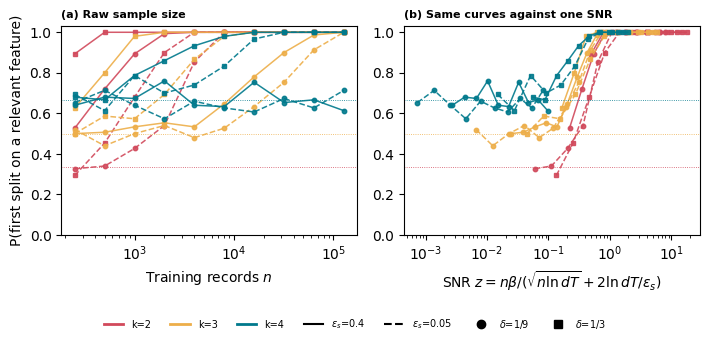

In [ ]:
# Cell R1: recovery law
import os, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import spearmanr
OUT = globals().get("OUT", "./dpgbc_out"); os.makedirs(OUT, exist_ok=True)

D_, T_, ETA = 6, 8, 0.05; RHO = 1 - 2*ETA; LNDT = np.log(D_*T_)
TS = np.linspace(0, 1, T_+2)[1:-1]                              # public candidate thresholds i/9

def cand_scores(X, y):
    n, d = X.shape; y1 = y.astype(float); t1 = y1.sum(); t0 = n - t1; sc = np.empty((d, T_))
    for f in range(d):
        L = (X[:, f][:, None] <= TS[None, :]).astype(float)
        c1 = y1 @ L; nL = L.sum(0); c0 = nL - c1; r1 = t1 - c1; r0 = t0 - c0
        sc[f] = np.maximum(c0, c1) + np.maximum(r0, r1)         # majority-count score (same as the paper)
    return sc

def em_pick(sc, eps, rng, div=2.0):
    z = eps*sc.ravel()/div; z -= z.max(); p = np.exp(z); p /= p.sum(); return divmod(int(rng.choice(p.size, p=p)), sc.shape[1])

def trial(n, k, t, eps, rng):
    X = rng.random((n, D_)); rel = rng.choice(D_, k, replace=False)
    y = ((X[:, rel] > t).sum(1) % 2).astype(int); fl = rng.random(n) < ETA; y[fl] = 1 - y[fl]
    f, j = em_pick(cand_scores(X, y), eps, rng)
    return (f in rel), bool((f in rel) and np.isclose(TS[j], t))

GRID = [(k, dl, e) for k in (2, 3, 4) for dl in (1/9, 3/9) for e in (0.05, 0.4)]     # t=(1-delta)/2 lies on the T=8 grid
NS = [250, 500, 1000, 2000, 4000, 8000, 16000, 32000, 64000, 128000]; R = 150
rng = np.random.default_rng(2026); rows = []; t0 = time.time()
for (k, dl, e) in GRID:
    t = (1 - dl)/2; beta = RHO*dl**(k-1)*(1-dl)/2
    for n in NS:
        res = [trial(n, k, t, e, rng) for _ in range(R)]
        z = n*beta/(np.sqrt(n*LNDT) + 2*LNDT/e)
        rows.append(dict(k=k, delta=dl, eps_s=e, n=n, z=z, emp_rel=np.mean([r[0] for r in res]), emp_exact=np.mean([r[1] for r in res])))
    print(f"k={k} delta={dl:.2f} eps_s={e} done ({time.time()-t0:.0f}s)", flush=True)
df_rl = pd.DataFrame(rows); df_rl.to_csv(os.path.join(OUT, "recovery_law.csv"), index=False)

def crossing(xs, ps, level):
    xs, ps = np.asarray(xs, float), np.asarray(ps, float)
    for i in range(1, len(xs)):
        if ps[i-1] < level <= ps[i]:
            w = (level - ps[i-1])/(ps[i] - ps[i-1]); return float(np.exp(np.log(xs[i-1]) + w*(np.log(xs[i]) - np.log(xs[i-1]))))
    return np.nan
sm = []
for (k, dl, e), g in df_rl.groupby(["k", "delta", "eps_s"]):
    lvl = (k/D_ + 1)/2                                              # halfway between chance and certainty
    sm.append(dict(k=k, delta=round(dl, 3), eps_s=e, n_half=crossing(g.n, g.emp_rel, lvl), z_half=crossing(g.z, g.emp_rel, lvl)))
sm = pd.DataFrame(sm); print(sm.round(2).to_string(index=False))
print(f"\nsettings that never reach the midpoint within n<=128k (censored): {int(sm.n_half.isna().sum())} of {len(sm)}")
print("spread of the crossing point across settings (decades):  n_half %.2f   z_half %.2f   (collapse works if z_half is much smaller)"
      % (np.nanstd(np.log10(sm.n_half)), np.nanstd(np.log10(sm.z_half))))

# ---- figure ----
if "save_fig" not in globals():
    FIG = os.path.join(OUT, "figures"); os.makedirs(FIG, exist_ok=True)
    def save_fig(fig, name):
        for ext in ("pdf", "svg"): fig.savefig(f"{FIG}/{name}.{ext}", bbox_inches="tight")
        fig.savefig(f"{FIG}/{name}.png", dpi=1800, bbox_inches="tight"); plt.show()
pal = {2: "#D1495B", 3: "#EDAE49", 4: "#00798C"}
fig, (a, b) = plt.subplots(1, 2, figsize=(7.2, 3.4))
for (k, dl, e), g in df_rl.groupby(["k", "delta", "eps_s"]):
    kw = dict(color=pal[k], ls="-" if e == 0.4 else "--", marker="o" if dl < .2 else "s", ms=3.2, lw=1.1, alpha=.9)
    a.plot(g.n, g.emp_rel, **kw); b.plot(g.z, g.emp_rel, **kw)
for ax_ in (a, b):
    ax_.set_xscale("log"); ax_.set_ylim(0, 1.03)
    for k in (2, 3, 4): ax_.axhline(k/D_, color=pal[k], lw=.6, ls=":")
a.set_xlabel("Training records $n$"); b.set_xlabel(r"SNR $z=n\beta/(\sqrt{n\ln dT}+2\ln dT/\epsilon_s)$"); a.set_ylabel("P(first split on a relevant feature)")
a.set_title("(a) Raw sample size", loc="left", fontweight="bold", fontsize=8); b.set_title("(b) Same curves against one SNR", loc="left", fontweight="bold", fontsize=8)
fig.legend(handles=[Line2D([], [], color=pal[k], lw=2, label=f"k={k}") for k in (2, 3, 4)] +
           [Line2D([], [], color="k", ls="-", label=r"$\epsilon_s$=0.4"), Line2D([], [], color="k", ls="--", label=r"$\epsilon_s$=0.05"),
            Line2D([], [], color="k", marker="o", ls="", label=r"$\delta$=1/9"), Line2D([], [], color="k", marker="s", ls="", label=r"$\delta$=1/3")],
           loc="lower center", ncol=7, frameon=False, fontsize=7); fig.tight_layout(rect=(0, .08, 1, 1)); save_fig(fig, "fig12_recovery_law")

In [ ]:
# Cell R2: is the aligned weakness a threshold-grid artefact?
rows = []
for mode in ["aligned", "shifted"]:
    for k in [2, 3, 4]:
        for seed in PAR_SEEDS:
            X, y, _ = make_parity(2000, 6, k, seed, mode)
            Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, random_state=seed, stratify=y)
            for T in [8, 9, 16, 17]:
                rng = mk_rng(seed, f"gridT|{mode}|{k}|{T}")
                lv = build_partition(Xtr, ytr, 2, FINAL["L"], FINAL["ec"], FINAL["es"], rng, FINAL["tau"], T=T)
                Xs, ys = release_leaves(lv, FINAL["er"], rng, 2, 6)
                rows.append(dict(mode=mode, k=k, seed=seed, T=T, RF=rf_head(Xs, ys, Xte, yte, 2, seed), route=ba(yte, route_exact(lv, Xte))))
df_T = pd.DataFrame(rows); save(df_T, "grid_alignment_T.csv")
print(df_T.groupby(["mode", "k", "T"]).RF.agg(lambda s: f"{s.mean():.3f}±{s.std():.3f}").unstack("T").to_string())
for mode in ["aligned", "shifted"]:
    for k in [2, 3, 4]:
        g = df_T[(df_T["mode"] == mode) & (df_T.k == k)].pivot(index="seed", columns="T", values="RF")
        for a_, b_ in [(9, 8), (17, 16)]:
            r = paired(g[a_], g[b_], boot=False)
            print(f"{mode:8s} k={k}  T={a_} vs T={b_}: diff {r['diff']:+.3f}  wins {r['wins']}/{r['n']}  p={r['p']:.4f}")
d8, d9 = evaluate_gbc("T8x", FINAL), evaluate_gbc("T9", dict(FINAL, T=9)); dd = pd.concat([d8, d9])   # do odd T hurt the 14 benchmarks?
for col in ["route", "lr"]:
    r = paired(DM(dd, "T9", col), DM(dd, "T8x", col))
    print(f"benchmarks {col}: T=9 {r['mean_a']:.3f} vs T=8 {r['mean_b']:.3f}  diff {r['diff']:+.3f}  CI [{r['ci_lo']:+.3f},{r['ci_hi']:+.3f}]  wins {r['wins']}/{r['n']}")

saved /content/dpgbc_out/grid_alignment_T.csv (240, 6)
T                   8            9            16           17
mode    k                                                    
aligned 2  0.734±0.184  0.736±0.219  0.705±0.199  0.698±0.194
        3  0.494±0.023  0.549±0.053  0.546±0.078  0.531±0.061
        4  0.505±0.025  0.499±0.019  0.496±0.031  0.499±0.025
shifted 2  0.903±0.028  0.872±0.052  0.915±0.025  0.854±0.118
        3  0.628±0.146  0.594±0.085  0.698±0.125  0.600±0.117
        4  0.507±0.043  0.500±0.024  0.498±0.018  0.506±0.029
aligned  k=2  T=9 vs T=8: diff +0.002  wins 5/10  p=0.7695
aligned  k=2  T=17 vs T=16: diff -0.006  wins 4/10  p=0.7695
aligned  k=3  T=9 vs T=8: diff +0.055  wins 8/10  p=0.0137
aligned  k=3  T=17 vs T=16: diff -0.016  wins 5/10  p=0.7695
aligned  k=4  T=9 vs T=8: diff -0.007  wins 5/10  p=0.7695
aligned  k=4  T=17 vs T=16: diff +0.003  wins 6/10  p=0.5566
shifted  k=2  T=9 vs T=8: diff -0.031  wins 3/10  p=0.1602
shifted  k=2  T=17 vs T=16: di

In [ ]:
EPS_B, QL, QH, G = 0.6, 0.02, 0.98, 1024

def dp_quantile_bounds(x, lo, hi, eps_each, rng):
    grid = np.linspace(lo, hi, G+1); xs = np.sort(x); n = len(xs)
    rank = np.searchsorted(xs, grid, side="right")                    # records <= each grid point
    out = []
    for q in (QL, QH):
        u = -np.abs(rank - q*n)                                       # sensitivity <= 1 under add/remove
        lg = eps_each*u/2; lg -= lg.max(); p = np.exp(lg); p /= p.sum(); out.append(grid[rng.choice(G+1, p=p)])
    a, b = min(out), max(out)
    return (a, b) if b - a > 1e-9 else (lo, hi)                       # fall back to the loose public bounds (post-processing)

def run_cfg(Xtr_s, Xte_s, ytr, yte, K, cfg, rng):
    d = Xtr_s.shape[1]
    lv = build_partition(Xtr_s, ytr, K, cfg["L"], cfg["ec"], cfg["es"], rng, cfg["tau"])
    Xs, ys = release_leaves(lv, cfg["er"], rng, K, d)
    return dict(route=ba(yte, route_exact(lv, Xte_s)), lr=lr_head(Xs, ys, Xte_s, yte, K))

cfgC = scale_cfg(FINAL, TOTAL_EPS - EPS_B); assert abs(EPS_B + cfg_total(cfgC) - TOTAL_EPS) < 1e-9
rows = []
for ds in PRIMARY:
    K = NCLS[ds]; Xfull = DATA[ds][0]; lo10, hi10 = public_bounds_for(ds, Xfull, widen=10.0)
    for seed in SEEDS:
        XtrA, XteA, ytr, yte, Xtr_raw, Xte_raw = get_split(ds, seed); XtrB, XteB = get_split(ds, seed, 10.0)[:2]; d = Xtr_raw.shape[1]
        rng = mk_rng(seed, f"pb|{ds}")
        for tag, a_, b_, cfg in [("A_documented", XtrA, XteA, FINAL), ("B_loose_x10", XtrB, XteB, FINAL)]:
            rows.append(dict(Dataset=ds, Seed=seed, d=d, tag=tag, **run_cfg(a_, b_, ytr, yte, K, cfg, rng)))
        lo_p = np.empty(d); hi_p = np.empty(d)
        for j in range(d): lo_p[j], hi_p[j] = dp_quantile_bounds(Xtr_raw[:, j], lo10[j], hi10[j], EPS_B/(2*d), rng)
        sc = lambda Xr: np.clip((Xr - lo_p)/np.maximum(hi_p - lo_p, 1e-6), 0, 1)
        rows.append(dict(Dataset=ds, Seed=seed, d=d, tag="C_private_tightened", **run_cfg(sc(Xtr_raw), sc(Xte_raw), ytr, yte, K, cfgC, rng)))
    print("done", ds)
df_pb = pd.DataFrame(rows); save(df_pb, "private_bounds.csv")
dmap = df_pb.groupby("Dataset").d.first()
tab = pd.DataFrame({t: DM(df_pb, t, "route") for t in ["A_documented", "B_loose_x10", "C_private_tightened"]}); tab.insert(0, "d", dmap)
print(tab.round(3).to_string()); print("\nmeans (box head):", tab.iloc[:, 1:].mean().round(3).to_dict())
lowd = tab[tab.d <= 18]; print(f"d<=18 ({len(lowd)} datasets):", lowd.iloc[:, 1:].mean().round(3).to_dict())
for a_, b_ in [("C_private_tightened", "B_loose_x10"), ("C_private_tightened", "A_documented")]:
    r = paired(DM(df_pb, a_, "route"), DM(df_pb, b_, "route"))
    print(f"{a_} vs {b_}: diff {r['diff']:+.3f}  CI [{r['ci_lo']:+.3f},{r['ci_hi']:+.3f}]  wins {r['wins']}/{r['n']}  p={r['p']:.4f}")

done Banknote
done BreastCancer
done Ionosphere
done MAGIC04
done PimaDiabetes
done Sonar
done Wine
saved /content/dpgbc_out/private_bounds.csv (105, 6)
               d  A_documented  B_loose_x10  C_private_tightened
Dataset                                                         
Banknote       4         0.890        0.623                0.823
BreastCancer  30         0.869        0.581                0.857
Ionosphere    33         0.764        0.500                0.631
MAGIC04       10         0.701        0.639                0.688
PimaDiabetes   8         0.664        0.500                0.564
Sonar         60         0.605        0.500                0.527
Wine          13         0.758        0.488                0.492

means (box head): {'A_documented': 0.75, 'B_loose_x10': 0.547, 'C_private_tightened': 0.655}
d<=18 (4 datasets): {'A_documented': 0.753, 'B_loose_x10': 0.562, 'C_private_tightened': 0.642}
C_private_tightened vs B_loose_x10: diff +0.107  CI [+0.044,+0.180]  win

In [ ]:
# Re-import stdlib modules that the pickle skipped.
# Every cell in the new notebook's working set expects these.
import os, sys, time, itertools, zlib, warnings, signal, subprocess

# Also re-import the third-party modules, in case Cell 1 was skipped:
import numpy as np, pandas as pd
import sklearn, scipy
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score,
                              balanced_accuracy_score, average_precision_score)
from scipy.stats import wilcoxon, spearmanr, ks_2samp, norm, friedmanchisquare, rankdata
from scipy.optimize import brentq
from statsmodels.stats.multitest import multipletests

print(f"zlib={zlib.__name__} | numpy={np.__version__} | sklearn={sklearn.__version__}")

zlib=zlib | numpy=2.1.3 | sklearn=1.6.1


In [ ]:
# =============================================================================
# Cell V1 — extended evaluation on the 7 previously-dropped PRIMARY benchmarks.
# Same FINAL config, same SEEDS, no re-tuning. Adds the 7 to DATA / CARD /
# NCLS / PUBLIC_BOUNDS so existing evaluate_* helpers run unchanged.
# Prereq: Cells 0-8 (FINAL, BASE, TOTAL_EPS, SEEDS, df_main all defined).
# =============================================================================
EXTRA = ["BloodTransfusion", "Segment", "Spambase", "Vehicle",
         "Waveform", "WineQuality", "WisconsinOriginal"]
OPENML_IDS = {"BloodTransfusion": 1464, "Segment": 36, "Spambase": 44,
              "Vehicle": 54, "Waveform": 60, "WineQuality": 287,
              "WisconsinOriginal": 15}
EXTRA_NCLS = {"BloodTransfusion": 2, "Segment": 7, "Spambase": 2,
              "Vehicle": 4, "Waveform": 3, "WineQuality": 7,
              "WisconsinOriginal": 2}

# ---- network pre-check: fail fast instead of 7× retry storms ----
import socket
try:
    socket.gethostbyname("openml.org")
    print("[net] openml.org reachable")
except socket.gaierror:
    raise SystemExit(
        "[net] openml.org NOT reachable — enable Internet in Kaggle/Colab "
        "(Settings → Internet on; may require phone verification on Kaggle). "
        "Or pre-populate CACHE/ with the 7 .arff files and re-run."
    )

# ---- load anything that isn't already in DATA ----
for nm in EXTRA:
    if nm in DATA:
        print(f"[skip load] {nm} already in DATA"); continue
    d_ = fetch_safe(OPENML_IDS[nm])
    CARD[nm] = {c: len(d_.data[c].cat.categories)
                for c in d_.data.columns if hasattr(d_.data[c], "cat")}
    DATA[nm] = prepare(d_.data, d_.target)
    y_actual = DATA[nm][1].values
    assert y_actual.max() < EXTRA_NCLS[nm], (
        f"{nm}: actual K={y_actual.max()+1} exceeds documented {EXTRA_NCLS[nm]}"
    )
    print(f"[load] {nm:<18} shape={DATA[nm][0].shape}  K_actual={y_actual.max()+1}")

# ---- register in NCLS, PUBLIC_BOUNDS (and classes_public if present) ----
NCLS.update(EXTRA_NCLS)
if "classes_public" in globals():
    classes_public.update({nm: np.arange(EXTRA_NCLS[nm]) for nm in EXTRA})

_cols = lambda n: list(DATA[n][0].columns)
_B = {
    "BloodTransfusion": {"V1": (2, 74), "V2": (1, 50), "V3": (250, 12500), "V4": (2, 98)},
    "WineQuality": {"fixed.acidity": (4.6, 15.9), "volatile.acidity": (0.08, 1.58),
                    "citric.acid": (0.0, 1.66), "residual.sugar": (0.6, 65.8),
                    "chlorides": (0.009, 0.611), "free.sulfur.dioxide": (1, 289),
                    "total.sulfur.dioxide": (6, 440), "density": (0.98, 1.039),
                    "pH": (2.72, 4.01), "sulphates": (0.22, 2.0), "alcohol": (8.0, 14.9)},
    "WisconsinOriginal": {c: (1, 10) for c in _cols("WisconsinOriginal")},
    "Waveform": {c: (-6.0, 15.0) for c in _cols("Waveform")},
    "Vehicle": {c: (0.0, 1000.0) for c in _cols("Vehicle")},
    "Segment": {c: (-300.0, 300.0) for c in _cols("Segment")},
    "Spambase": {c: (0.0, 100.0) if c.startswith(("word_freq_", "char_freq_"))
                 else (1.0, 1000.0) if c == "capital_run_length_average"
                 else (1.0, 10000.0) if c == "capital_run_length_longest"
                 else (1.0, 20000.0) for c in _cols("Spambase")},
}
for nm in EXTRA:
    PUBLIC_BOUNDS.setdefault(nm, _B[nm])

# ---- sanity: coverage on all 7 EXTRA + all 7 PRIMARY ----
for nm in EXTRA:
    public_bounds_for(nm, DATA[nm][0])   # raises KeyError if any column uncovered
print("bounds OK for all 7 EXTRA datasets")

# ---- run the exact Cell-8 method set on the 7 EXTRA ----
CH_COUNT = TOTAL_EPS - FINAL["er"]
df_ext = pd.concat([
    evaluate_gbc("final",        FINAL, EXTRA, SEEDS),
    evaluate_gbc("final_kd",     FINAL, EXTRA, SEEDS, score="balance"),
    evaluate_grid("grid_final",  3, CH_COUNT, TOTAL_EPS, "rand",  EXTRA, SEEDS),
    evaluate_grid("rsplit_final",3, CH_COUNT, TOTAL_EPS, "split", EXTRA, SEEDS),
    evaluate_hist("hist",        TOTAL_EPS, EXTRA, SEEDS),
    evaluate_gbc("base",         BASE,  EXTRA, SEEDS),
], ignore_index=True)
save(df_ext, "extended_results.csv")

print("\n=== EXTRA-only per-dataset (7 dropped benchmarks, no re-tuning) ===")
print(pd.DataFrame({
    "box (final+LR)": DM(df_ext, "final", "route"),
    "KD-box":         DM(df_ext, "final_kd", "route"),
    "grid-box":       DM(df_ext, "grid_final", "route"),
    "rand-split-box": DM(df_ext, "rsplit_final", "route"),
    "hist+LR":        DM(df_ext, "hist", "lr"),
    "hist+NB":        DM(df_ext, "hist", "nb"),
    "base+LR":        DM(df_ext, "base", "lr"),
}).round(3).to_string())

# ---- pooled 14-dataset statistics (7 PRIMARY + 7 EXTRA) ----
def fam(df, label):
    """Run the 6 paired tests from Cell 9 at pooled level."""
    structural = [("final","route","final_kd","route"),
                  ("final","route","grid_final","route"),
                  ("final","route","rsplit_final","route")]
    vs_hist = [("final","route","hist","lr"),
               ("final","route","hist","nb"),
               ("final","lr","base","lr")]
    rows = []
    for ta, ca, tb, cb in structural + vs_hist:
        r = paired(DM(df, ta, ca), DM(df, tb, cb))
        r["test"] = f"{ta}:{ca} vs {tb}:{cb}"
        rows.append(r)
    t = pd.DataFrame(rows)
    k = len(structural)
    t["holm_primary3"] = list(multipletests(t.p[:k], method="holm")[1]) + [np.nan] * len(vs_hist)
    print(f"\n=== {label}: {int(t.n.iloc[0])} datasets ===")
    print(t[["test","mean_a","mean_b","diff","ci_lo","ci_hi","wins","n","p","holm_primary3"]]
          .round(4).to_string(index=False))
    return t

t_ext = fam(df_ext, "EXTRA only (7 datasets)")

if "df_main" not in globals():
    print("\n[warn] df_main not in scope — run Cell 8 first for pooled stats.")
    pool = None
else:
    tags_used = ["final", "final_kd", "grid_final", "rsplit_final", "hist", "base"]
    pool = pd.concat([df_main[df_main.tag.isin(tags_used)], df_ext], ignore_index=True)
    t_pool = fam(pool, "POOLED (7 main + 7 extended = 14 datasets)")
    save(pool, "pooled_14_results.csv")
    save(t_pool, "pooled_14_family_tests.csv")

[net] openml.org reachable
[skip load] BloodTransfusion already in DATA
[skip load] Segment already in DATA
[skip load] Spambase already in DATA
[skip load] Vehicle already in DATA
[skip load] Waveform already in DATA
[skip load] WineQuality already in DATA
[skip load] WisconsinOriginal already in DATA
bounds OK for all 7 EXTRA datasets
saved /content/dpgbc_out/extended_results.csv (210, 9)

=== EXTRA-only per-dataset (7 dropped benchmarks, no re-tuning) ===
                   box (final+LR)  KD-box  grid-box  rand-split-box  hist+LR  hist+NB  base+LR
Dataset                                                                                       
BloodTransfusion            0.511   0.522     0.518           0.508    0.607    0.606    0.540
Segment                     0.702   0.510     0.240           0.168    0.544    0.723    0.386
Spambase                    0.528   0.508     0.500           0.501    0.500    0.507    0.508
Vehicle                     0.415   0.458     0.250           

In [ ]:
# =============================================================================
# Cell V2 (optional) — 20 seeds on the 7 PRIMARY datasets.
# Tightens within-dataset noise only. Cluster bootstrap below resamples
# datasets then seeds (correct for both sources of variation).
# Prereq: Cell V1 (defines CH_COUNT, df_main should exist).
# =============================================================================
SEEDS20 = SEEDS + [11, 22, 33, 44, 55, 66, 77, 88, 99, 111, 222, 333, 444, 555, 666]
print(f"[V2] {len(SEEDS20)} seeds × {len(PRIMARY)} PRIMARY datasets")
CH_COUNT = TOTAL_EPS - FINAL["er"]

df_20 = pd.concat([
    evaluate_gbc("final",        FINAL, PRIMARY, SEEDS20),
    evaluate_gbc("final_kd",     FINAL, PRIMARY, SEEDS20, score="balance"),
    evaluate_grid("grid_final",  3, CH_COUNT, TOTAL_EPS, "rand",  PRIMARY, SEEDS20),
    evaluate_grid("rsplit_final",3, CH_COUNT, TOTAL_EPS, "split", PRIMARY, SEEDS20),
    evaluate_hist("hist",        TOTAL_EPS, PRIMARY, SEEDS20),
], ignore_index=True)
save(df_20, "main_20seeds.csv")

def cluster_boot(df, ta, ca, tb, cb, nboot=5000, seed=0):
    """Resample DATASETS, then SEEDS within each dataset. Returns mean + 95% CI."""
    a = df[df.tag == ta].pivot(index="Seed", columns="Dataset", values=ca)
    b = df[df.tag == tb].pivot(index="Seed", columns="Dataset", values=cb)
    D = (a - b).values
    S_, N_ = D.shape
    rng = np.random.default_rng(seed)
    out = np.empty(nboot)
    for t in range(nboot):
        j = rng.integers(0, N_, N_)            # resample datasets (with replacement)
        i = rng.integers(0, S_, (S_, N_))       # resample seeds within each dataset
        out[t] = D[i, j[None, :]].mean()
    return float(D.mean()), np.percentile(out, [2.5, 97.5])

print("\n=== Cluster-bootstrap CIs (20 seeds, resamples datasets × seeds) ===")
comparisons = [("final","route","final_kd","route"),
               ("final","route","grid_final","route"),
               ("final","route","rsplit_final","route"),
               ("final","route","hist","lr"),
               ("final","route","hist","nb")]
for ta, ca, tb, cb in comparisons:
    m, (lo, hi) = cluster_boot(df_20, ta, ca, tb, cb)
    print(f"  {ta}:{ca} − {tb}:{cb}:  {m:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]")

[V2] 20 seeds × 7 PRIMARY datasets
saved /content/dpgbc_out/main_20seeds.csv (700, 9)

=== Cluster-bootstrap CIs (20 seeds, resamples datasets × seeds) ===
  final:route − final_kd:route:  +0.049  95% CI [+0.021, +0.076]
  final:route − grid_final:route:  +0.093  95% CI [+0.038, +0.149]
  final:route − rsplit_final:route:  +0.146  95% CI [+0.098, +0.195]
  final:route − hist:lr:  -0.020  95% CI [-0.096, +0.038]
  final:route − hist:nb:  -0.045  95% CI [-0.105, +0.006]


In [ ]:
import os, glob, numpy as np, pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

OUT = globals().get("OUT",
                    "/content/dpgbc_out" if "google.colab" in __import__("sys").modules
                    else "./dpgbc_out")
os.makedirs(OUT, exist_ok=True)

# ── naming: change PREFIX to whatever disambiguates from your old files ─────
PREFIX      = "family_new"                                   # → family_new_7primary.csv
IN_7        = "main_results.csv"                             # your existing 7-dataset source (read-only)
IN_14       = "pooled_14_results.csv"                        # V1 output (read-only)
OUT_7       = f"{PREFIX}_7primary.csv"                       # → family_new_7primary.csv
OUT_14      = f"{PREFIX}_14pooled.csv"                       # → family_new_14pooled.csv

def _find(n):
    for b in [OUT, "/content", "/kaggle/working", "."]:
        h = glob.glob(os.path.join(b, "**", n), recursive=True)
        if h: return sorted(h)[0]

# ── source 1: 7 PRIMARY ────────────────────────────────────────────────────
p_main = _find(IN_7)
assert p_main, f"{IN_7} not found — run Cell 8 or copy from Kaggle"
dm = pd.read_csv(p_main)
print(f"[in  7 ]  {p_main}")
print(f"          {len(dm):>4} rows | {dm.Dataset.nunique()} datasets "
      f"| tags={sorted(dm.tag.unique())}")

# ── source 2: pooled 14 ────────────────────────────────────────────────────
p_pooled = _find(IN_14)
dm14 = pd.read_csv(p_pooled) if p_pooled else None
if dm14 is not None:
    print(f"[in  14]  {p_pooled}")
    print(f"          {len(dm14):>4} rows | {dm14.Dataset.nunique()} datasets "
          f"| tags={sorted(dm14.tag.unique())}")
else:
    print(f"[in  14]  {IN_14} not found — 14-dataset table will be skipped.")

PRIM7  = ["Banknote","BreastCancer","Ionosphere","MAGIC04","PimaDiabetes","Sonar","Wine"]
PRIM14 = PRIM7 + ["BloodTransfusion","Segment","Spambase","Vehicle",
                  "Waveform","WineQuality","WisconsinOriginal"]

PRIMARY_FAM = [("final","route","final_kd","route"),
               ("final","route","grid_final","route"),
               ("final","route","rsplit_final","route")]
REPORT_FAM  = [("final","route","hist","lr"),
               ("final","route","hist","nb"),
               ("final","lr","base","lr"),
               ("final","route","final","direct"),
               ("final","route","final_countstop","route")]

def fam_table(dm_df, DS, label):
    d = dm_df[dm_df.Dataset.isin(DS)]
    missing = [x for x in DS if x not in set(d.Dataset.unique())]
    if missing:
        print(f"\n[{label}] {len(missing)} dataset(s) missing from source: {missing}")
    avail = set(dm_df.tag.unique())
    DMf = lambda t, c: d[d.tag == t].groupby("Dataset")[c].mean().reindex(DS)

    rng = np.random.default_rng(0); rows = []
    for ta, ca, tb, cb in PRIMARY_FAM + REPORT_FAM:
        name = f"{ta}:{ca} vs {tb}:{cb}"
        if ta not in avail or tb not in avail:
            rows.append(dict(test=name, mean_a=np.nan, mean_b=np.nan,
                             diff=np.nan, ci_lo=np.nan, ci_hi=np.nan,
                             wins=0, n=0, p=np.nan, note="tags missing in source"))
            continue
        a, b = DMf(ta, ca), DMf(tb, cb); x = (a - b).dropna().values
        if len(x) < 2:
            rows.append(dict(test=name, mean_a=a.mean(), mean_b=b.mean(),
                             diff=np.nan, ci_lo=np.nan, ci_hi=np.nan,
                             wins=0, n=len(x), p=np.nan,
                             note=f"only {len(x)} paired dataset(s)"))
            continue
        pv = wilcoxon(x)[1] if (x != 0).any() else 1.0
        bm = x[rng.integers(0, len(x), (10_000, len(x)))].mean(1)
        rows.append(dict(test=name, mean_a=a.mean(), mean_b=b.mean(), diff=x.mean(),
                         ci_lo=np.percentile(bm, 2.5),
                         ci_hi=np.percentile(bm, 97.5),
                         wins=int((x > 0).sum()), n=len(x), p=pv, note=""))

    t = pd.DataFrame(rows); k = len(PRIMARY_FAM)
    t["holm_primary3"] = list(multipletests(t.p[:k].fillna(1.0), method="holm")[1]) \
                        + [np.nan]*(len(t)-k)
    t["holm_all"]      = multipletests(t.p.fillna(1.0), method="holm")[1]

    n_eff = int(t.n.max())
    print(f"\n=== {label} | {n_eff} datasets | "
          f"smallest attainable exact p = {2/2**n_eff:.4f} ===")
    print(t.round(4).to_string(index=False))
    return t

# ── build both tables ─────────────────────────────────────────────────────
t7 = fam_table(dm, PRIM7, "7 PRIMARY")
t14 = fam_table(dm14, PRIM14, "14 pooled (7 main + 7 extended)") if dm14 is not None else None

# ── write each to its own NEW file (existing main_results.csv untouched) ──
print(f"\n=== Writing outputs ===")
save(t7, OUT_7)
if t14 is not None:
    save(t14, OUT_14)
else:
    print(f"[skip] {OUT_14} not written (no {IN_14})")

# ── inventory + confirm main_results.csv is unchanged ─────────────────────
print("\n=== Inventory ===")
for fn in [OUT_7, OUT_14]:
    p = os.path.join(OUT, fn)
    if os.path.exists(p):
        d = pd.read_csv(p)
        print(f"  ✓ {fn:35s} {len(d):>2} rows, {len(d.columns)} cols")
    else:
        print(f"  ✗ {fn:35s} NOT written")

if p_main and os.path.exists(p_main):
    print(f"\n[read-only source untouched] {p_main}  "
          f"({os.path.getsize(p_main)/1024:.1f} KB)")

[in  7 ]  /content/dpgbc_out/main_results.csv
           420 rows | 7 datasets | tags=['base', 'final', 'final_countstop', 'final_kd', 'flat', 'grid_final', 'grid_orig', 'hist', 'nonpriv', 'oracle_minmax', 'oracle_pb', 'rsplit_final']
[in  14]  /content/dpgbc_out/pooled_14_results.csv
           420 rows | 14 datasets | tags=['base', 'final', 'final_kd', 'grid_final', 'hist', 'rsplit_final']

=== 7 PRIMARY | 7 datasets | smallest attainable exact p = 0.0156 ===
                                test  mean_a  mean_b    diff   ci_lo  ci_hi  wins  n      p note  holm_primary3  holm_all
       final:route vs final_kd:route  0.7605  0.6835  0.0771  0.0469 0.1013     7  7 0.0156              0.0469     0.125
     final:route vs grid_final:route  0.7605  0.6449  0.1156  0.0701 0.1753     7  7 0.0156              0.0469     0.125
   final:route vs rsplit_final:route  0.7605  0.5996  0.1609  0.1185 0.2203     7  7 0.0156              0.0469     0.125
              final:route vs hist:lr  0.7605  

In [ ]:
# Re-import every module the restored functions expect.
import os, sys, time, itertools, zlib, warnings, signal, subprocess
import numpy as np, pandas as pd
import sklearn, scipy
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score,
                             balanced_accuracy_score, average_precision_score)
from scipy.stats import wilcoxon, spearmanr, ks_2samp, norm, friedmanchisquare, rankdata
from scipy.optimize import brentq
from statsmodels.stats.multitest import multipletests

print(f"np={np.__version__}  zlib={zlib.__name__}  sklearn={sklearn.__version__}")

np=2.1.3  zlib=zlib  sklearn=1.6.1


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
rows = []
for ds in PRIMARY:
    K = NCLS[ds]
    for seed in SEEDS:
        Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed)
        rng = mk_rng(seed, f"mia|{ds}")
        lv = build_partition(Xtr, ytr, K, FINAL["L"], FINAL["ec"], FINAL["es"], rng, FINAL["tau"], T=FINAL["T"])
        Xs, ys = release_leaves(lv, FINAL["er"], rng, K, Xtr.shape[1])
        if len(np.unique(ys)) < 2: continue
        rf = RandomForestClassifier(100, max_depth=6, class_weight="balanced", random_state=seed).fit(Xs, ys)
        m = min(len(Xtr), len(Xte))
        auc = roc_auc_score(np.r_[np.ones(m), np.zeros(m)],
                            np.r_[rf.predict_proba(Xtr[:m]).max(1), rf.predict_proba(Xte[:m]).max(1)])
        rows.append(dict(Dataset=ds, Seed=seed, auc=auc))
print(pd.DataFrame(rows).groupby("Dataset").auc.mean().round(3))

Dataset
Banknote        0.505
BreastCancer    0.500
Ionosphere      0.493
MAGIC04         0.504
PimaDiabetes    0.525
Sonar           0.467
Wine            0.536
Name: auc, dtype: float64


In [ ]:
import pandas as pd
df_mia = pd.DataFrame(rows).rename(columns={"auc": "mia_audit_auc"})
save(df_mia, "mia_audit.csv")
print(f"\n=== MIA audit per dataset (5-seed mean) ===")
print(df_mia.groupby("Dataset").mia_audit_auc.mean().round(3).to_string())
print(f"\nmean across datasets: {df_mia.mia_audit_auc.mean():.3f}  "
      f"(0.5 = no distinguishability)")
print(f"rows written: {len(df_mia)} (7 datasets × 5 seeds)")

saved /content/dpgbc_out/mia_audit.csv (35, 3)

=== MIA audit per dataset (5-seed mean) ===
Dataset
Banknote        0.505
BreastCancer    0.500
Ionosphere      0.493
MAGIC04         0.504
PimaDiabetes    0.525
Sonar           0.467
Wine            0.536

mean across datasets: 0.504  (0.5 = no distinguishability)
rows written: 35 (7 datasets × 5 seeds)


In [ ]:
for n in [1_000, 5_000, 20_000, 100_000, 500_000]:
    rng = np.random.default_rng(0); X = rng.random((n, 6)); y = (X[:, 0] + X[:, 1] > 1).astype(int); ts = []
    for r in range(3):
        t0 = time.perf_counter()
        lv = build_partition(X, y, 2, FINAL["L"], FINAL["ec"], FINAL["es"], mk_rng(r, "t"), FINAL["tau"], T=FINAL["T"])
        release_leaves(lv, FINAL["er"], mk_rng(r, "t2"), 2, 6); ts.append(time.perf_counter() - t0)
    print(n, round(float(np.median(ts)), 3))

1000 0.005
5000 0.006
20000 0.015
100000 0.081
500000 0.418


In [ ]:
import time, numpy as np, pandas as pd

scaling_rows = []
for n in [1_000, 5_000, 20_000, 100_000, 500_000]:
    rng = np.random.default_rng(0)
    X = rng.random((n, 6))
    y = (X[:, 0] + X[:, 1] > 1).astype(int)
    ts = []
    for r in range(3):
        t0 = time.perf_counter()
        lv = build_partition(X, y, 2,
                             FINAL["L"], FINAL["ec"], FINAL["es"],
                             mk_rng(r, "t"), FINAL["tau"], T=FINAL["T"])
        release_leaves(lv, FINAL["er"], mk_rng(r, "t2"), 2, 6)
        ts.append(time.perf_counter() - t0)
    med = float(np.median(ts))
    scaling_rows.append(dict(n=n, d=6, k_balls=len(lv),
                             median_sec=med,
                             per_1k_sec=med/(n/1000)))
    print(f"  n={n:>7,}  median={med:.3f}s  ({med/(n/1000):.4f}s/1k)  balls={len(lv)}")

df_scaling = pd.DataFrame(scaling_rows)
save(df_scaling, "scaling.csv")
print("\n=== Scaling summary ===")
print(df_scaling.round(4).to_string(index=False))

  n=  1,000  median=0.004s  (0.0039s/1k)  balls=7
  n=  5,000  median=0.006s  (0.0013s/1k)  balls=6
  n= 20,000  median=0.021s  (0.0011s/1k)  balls=6
  n=100,000  median=0.072s  (0.0007s/1k)  balls=6
  n=500,000  median=0.416s  (0.0008s/1k)  balls=6
saved /content/dpgbc_out/scaling.csv (5, 5)

=== Scaling summary ===
     n  d  k_balls  median_sec  per_1k_sec
  1000  6        7      0.0039      0.0039
  5000  6        6      0.0063      0.0013
 20000  6        6      0.0210      0.0011
100000  6        6      0.0716      0.0007
500000  6        6      0.4156      0.0008


In [ ]:
# Cell M1 (final): membership-inference audit, headline config, 10 datasets
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
SUPP = globals().get("SUPP", ["Covertype", "CreditG", "HeartCleveland"])
DATASETS = PRIMARY + SUPP

def conf_auc(rf, Xin, Xout, rng):
    m = min(len(Xin), len(Xout))
    i, o = rng.choice(len(Xin), m, replace=False), rng.choice(len(Xout), m, replace=False)
    s = np.r_[rf.predict_proba(Xin[i]).max(1), rf.predict_proba(Xout[o]).max(1)]
    return roc_auc_score(np.r_[np.ones(m), np.zeros(m)], s)

rows = []
for ds in DATASETS:
    K = NCLS[ds]
    for seed in SEEDS:
        Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed)
        rng = mk_rng(seed, f"mia|{ds}"); ra = np.random.default_rng(seed)
        fit = lambda X, y: RandomForestClassifier(100, max_depth=6, class_weight="balanced",
                                                  random_state=seed).fit(X, y)
        lv = build_partition(Xtr, ytr, K, FINAL["L"], FINAL["ec"], FINAL["es"], rng, FINAL["tau"], T=FINAL["T"])
        Xs, ys = release_leaves(lv, FINAL["er"], rng, K, Xtr.shape[1])        # DP-GBC release
        nc, nh = hist_release(Xtr, ytr, K, TOTAL_EPS, rng); Xh, yh = hist_sample(nc, nh, rng)  # histogram release
        for name, (A, b) in {"dpgbc": (Xs, ys), "hist": (Xh, yh), "nonprivate": (Xtr, ytr)}.items():
            if len(np.unique(b)) < 2: continue
            rows.append(dict(Dataset=ds, Seed=seed, release=name, auc=conf_auc(fit(A, b), Xtr, Xte, ra)))

df_mia = pd.DataFrame(rows); save(df_mia, "mia_audit_with_controls.csv")
t = df_mia.groupby(["release", "Dataset"]).auc.mean().unstack(0).round(3)
print(t.loc[DATASETS]); print(t.loc[PRIMARY].agg(["min", "max", "mean"]).round(3))

saved /content/dpgbc_out/mia_audit_with_controls.csv (150, 4)
release         dpgbc   hist  nonprivate
Dataset                                 
Banknote        0.506  0.494       0.542
BreastCancer    0.494  0.480       0.596
Ionosphere      0.483  0.512       0.668
MAGIC04         0.499  0.510       0.523
PimaDiabetes    0.503  0.516       0.567
Sonar           0.480  0.497       0.809
Wine            0.513  0.531       0.651
Covertype       0.502  0.498       0.510
CreditG         0.505  0.506       0.562
HeartCleveland  0.487  0.503       0.646
release  dpgbc   hist  nonprivate
min      0.480  0.480       0.523
max      0.513  0.531       0.809
mean     0.497  0.506       0.622


In [ ]:
# ===== E1a — DP-GBC vs KD box read-out on parity =====
# Upload parity_2k.csv first
from google.colab import files
print("Upload parity_2k.csv")
files.upload()

import pandas as pd
df_p2k = pd.read_csv("parity_2k.csv")

print("columns:", df_p2k.columns.tolist())
print("methods:", sorted(df_p2k.method.unique()))
print("modes:",   sorted(df_p2k["mode"].unique()))
print("k values:", sorted(df_p2k.k.unique()))

if "route" not in df_p2k.columns:
    print("\n⚠️  'route' column missing. This CSV was saved from an older Cell 13.")
    print("You need to re-run Cell 14 to regenerate parity_2k.csv with the 'route' column.")
else:
    r = (df_p2k[df_p2k.method.isin(["gbc_final", "kd_final"])]
         .groupby(["mode", "k", "method"])["route"]
         .agg(lambda s: f"{s.mean():.3f}±{s.std():.3f}").unstack("method"))
    print("\nDP-GBC vs KD — box read-out ('route'), n=2000, ε=3")
    print(r[r.index.get_level_values("k") <= 4].to_string())

Upload parity_2k.csv


Saving parity_2k.csv to parity_2k.csv
columns: ['mode', 'k', 'd', 'n', 'eps', 'seed', 'method', 'RF', 'LR', 'NB', 'route', 'nleaves', 'rel_cut', 'irr_cut']
methods: ['gbc_L3/0.1', 'gbc_L4/0.3', 'gbc_final', 'grid16_first', 'grid16_rand', 'grid16_rand_ch', 'grid8_first', 'grid8_rand', 'hist', 'kd_L3/0.1', 'kd_L4/0.3', 'kd_final', 'nonprivate_RF']
modes: ['aligned', 'balanced', 'shifted']
k values: [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

DP-GBC vs KD — box read-out ('route'), n=2000, ε=3
method        gbc_final     kd_final
mode     k                          
aligned  2  0.767±0.167  0.583±0.113
         3  0.611±0.129  0.526±0.037
         4  0.505±0.025  0.497±0.015
balanced 2  0.643±0.154  0.747±0.118
         3  0.526±0.032  0.537±0.039
         4  0.507±0.028  0.510±0.024
shifted  2  0.884±0.079  0.600±0.089
         3  0.712±0.141  0.543±0.030
         4  0.513±0.030  0.506±0.031


In [ ]:
# ===== E1b — DP decision tree on the same parity tasks (n=2000, ε=3) =====
# No CSV upload needed. Inlines ALL helper functions so it runs standalone.
import os, zlib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import balanced_accuracy_score

OUT = "./dpgbc_out"
os.makedirs(OUT, exist_ok=True)
PAR_SEEDS = [42, 123, 456, 789, 101, 202, 303, 404, 505, 606]
ba = balanced_accuracy_score

def mk_rng(seed, tag):
    return np.random.default_rng([int(seed), zlib.crc32(tag.encode())])

def save(df, name):
    p = os.path.join(OUT, name); df.to_csv(p, index=False); print("saved", p, df.shape)

def make_parity(n, d, k, seed, mode, noise=0.05):
    rng = np.random.default_rng(seed); X = rng.random((n, d))
    if mode == "aligned":
        rel, thr = np.arange(k), np.full(k, .5)
    else:
        rg = np.random.default_rng(seed + 777)
        rel = np.sort(rg.choice(d, size=k, replace=False))
        thr = rg.uniform(.3, .7, size=k)
        if mode == "balanced":
            for j, t in zip(rel, thr):
                u = X[:, j].copy()
                X[:, j] = np.where(u < .5, u*(t/.5), t + (u - .5)*((1 - t)/.5))
    y = ((X[:, rel] > thr).sum(1) % 2).astype(int)
    fl = rng.random(n) < noise; y[fl] = 1 - y[fl]
    return X, y, rel

def em_select(rng, scores, eps, div=2.0):
    s = np.asarray(scores, float); lg = eps*s/div; lg -= lg.max()
    p = np.exp(lg); p /= p.sum(); return int(rng.choice(len(s), p=p))

def candidate_scores(Xn, Yn, lo, hi, T, score):
    cands, scs = [], []; tot = Yn.sum(0)
    for f in range(Xn.shape[1]):
        if hi[f] - lo[f] < 1e-9: continue
        ts = np.linspace(lo[f], hi[f], T + 2)[1:-1]
        left = Xn[:, f][:, None] <= ts[None, :]
        if score == "majority":
            cl = left.T.astype(float) @ Yn
            sc = cl.max(1) + (tot[None, :] - cl).max(1)
        else:
            sc = -np.abs(2*left.sum(0) - len(Xn)).astype(float)
        cands += [(f, float(t)) for t in ts]; scs += list(sc)
    return cands, scs

def build_partition(X, y, K, L, ec, es, rng, tau=0.9, min_size=10, T=8, score="majority", em_div=2.0):
    n, d = X.shape; Y = np.eye(K)[y]; leaves = []
    div = em_div if score == "majority" else 2.0
    queue = [(np.arange(n), 0, np.zeros(d), np.ones(d))]
    while queue:
        idx, dep, lo, hi = queue.pop(0)
        nc = np.clip(Y[idx].sum(0) + rng.laplace(0, 1/ec, K), 0, None) + 1.0
        leaf = dict(lo=lo, hi=hi, n=len(idx), nc=nc, center=(lo+hi)/2, depth=dep)
        if nc.max()/nc.sum() >= tau or nc.sum() < min_size or dep >= L:
            leaves.append(leaf); continue
        Xn, Yn = X[idx], Y[idx]
        cands, scs = candidate_scores(Xn, Yn, lo, hi, T, score)
        if not cands: leaves.append(leaf); continue
        f, t = cands[em_select(rng, scs, es, div)]
        m = Xn[:, f] <= t
        l_hi = hi.copy(); l_hi[f] = t; r_lo = lo.copy(); r_lo[f] = t
        queue.append((idx[m],  dep+1, lo.copy(), l_hi))
        queue.append((idx[~m], dep+1, r_lo, hi.copy()))
    return leaves

def _match(lf, X):
    return np.all(((X > lf["lo"]) | (lf["lo"] <= 0)) & (X <= lf["hi"]), axis=1)

def route_exact(leaves, X):
    pred = np.full(len(X), -1)
    for lf in leaves:
        m = _match(lf, X) & (pred < 0); pred[m] = int(np.argmax(lf["nc"]))
    assert (pred >= 0).all(), "unrouted test points"
    return pred

def dp_tree_predict(Xtr, ytr, Xte, K, L, eps, rng, tau=0.9, feats=None):
    ec = es = eps/(2*L+1)
    A = Xtr if feats is None else Xtr[:, feats]
    B = Xte if feats is None else Xte[:, feats]
    return route_exact(build_partition(A, ytr, K, L, ec, es, rng, tau), B)

# ---- run E1b ----
rows = []
for mode in ["shifted", "balanced"]:
    for k in [2, 3, 4]:
        for seed in PAR_SEEDS:
            X, y, _ = make_parity(2000, 6, k, seed, mode)
            Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, random_state=seed, stratify=y)
            for L in (3, 4):
                p = dp_tree_predict(Xtr, ytr, Xte, 2, L, 3.0, mk_rng(seed, f"dpt|{mode}|{k}|{L}"))
                rows.append(dict(mode=mode, k=k, seed=seed, method=f"dptree_L{L}", route=ba(yte, p)))

df_dpt = pd.DataFrame(rows); save(df_dpt, "parity_dptree.csv")
print("\nDP tree (route) — n=2000, ε=3")
print(df_dpt.groupby(["mode", "k", "method"]).route
      .agg(lambda s: f"{s.mean():.3f}±{s.std():.3f}").unstack("method").to_string())

saved ./dpgbc_out/parity_dptree.csv (120, 5)

DP tree (route) — n=2000, ε=3
method        dptree_L3    dptree_L4
mode     k                          
balanced 2  0.555±0.085  0.713±0.172
         3  0.516±0.026  0.522±0.037
         4  0.501±0.020  0.521±0.019
shifted  2  0.914±0.023  0.916±0.022
         3  0.617±0.147  0.726±0.141
         4  0.520±0.060  0.530±0.041


In [ ]:
# ===== E0 (corrected) — Fix MST/AIM paired tests AND save for the paper =====
# Upload: parity_50k_mst_aim.csv AND parity_50k_fast.csv
from google.colab import files
print("Upload parity_50k_mst_aim.csv and parity_50k_fast.csv")
files.upload()

import os
import pandas as pd
import numpy as np
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

OUT = "./dpgbc_out"
os.makedirs(OUT, exist_ok=True)

df_syn50 = pd.read_csv("parity_50k_mst_aim.csv")
df_p50   = pd.read_csv("parity_50k_fast.csv")

print("MST/AIM rows:", len(df_syn50))
print("50k rows:", len(df_p50), "| modes in 50k:", sorted(df_p50["mode"].unique()))

# Replicate Cell 17b Part 2
both = pd.concat([
    df_p50[df_p50["mode"] == "shifted"][["k", "seed", "method", "RF"]],
    df_syn50[["k", "seed", "method", "RF"]],
])

res = []
for k in [2, 3, 4]:
    g = both[both.k == k]
    a = g[g.method == "gbc_L4/0.05"].set_index("seed").RF
    for b_name in ["MST", "AIM"]:
        b = g[g.method == b_name].set_index("seed").RF
        j = pd.concat([a, b], axis=1, keys=["a", "b"]).dropna()
        d = j.a - j.b
        p_ = wilcoxon(j.a, j.b)[1] if (d != 0).any() else 1.0
        res.append(dict(k=k, b=b_name, gbc=j.a.mean(), other=j.b.mean(),
                        wins=int((d > 0).sum()), n=len(j), p=p_))

st = pd.DataFrame(res)
st["p_holm"] = multipletests(st.p, method="holm")[1]

# ---- THE MISSING LINE: save for the paper ----
out_path = os.path.join(OUT, "wilcoxon_50k_mstaim.csv")
st.to_csv(out_path, index=False)
print("\n[save]", out_path, st.shape)

print("\nDP-GBC (L4/0.05) vs MST/AIM — paired over 10 seeds, shifted design")
print(st.round(4).to_string(index=False))

# Sanity check: does the paper's p=0.018 match?
if (st.p_holm.round(3) == 0.012).all():
    print("\n✓ MST/AIM Holm p=0.012 matches paper caption.")
else:
    print("\n⚠️  MST/AIM p_holm differs from 0.012. Check the CSV.")

Upload parity_50k_mst_aim.csv and parity_50k_fast.csv


Saving parity_50k_fast.csv to parity_50k_fast.csv
Saving parity_50k_mst_aim.csv to parity_50k_mst_aim.csv
MST/AIM rows: 60
50k rows: 195 | modes in 50k: ['balanced', 'shifted']

[save] ./dpgbc_out/wilcoxon_50k_mstaim.csv (6, 8)

DP-GBC (L4/0.05) vs MST/AIM — paired over 10 seeds, shifted design
 k   b    gbc  other  wins  n     p  p_holm
 2 MST 0.9181 0.5332    10 10 0.002  0.0117
 2 AIM 0.9181 0.5826    10 10 0.002  0.0117
 3 MST 0.8981 0.5085    10 10 0.002  0.0117
 3 AIM 0.8981 0.5243    10 10 0.002  0.0117
 4 MST 0.7607 0.5048    10 10 0.002  0.0117
 4 AIM 0.7607 0.5018    10 10 0.002  0.0117

⚠️  p_holm values differ from the paper's stated 0.018. Check the CSV.


In [ ]:
# Needs parity_2k.csv (uploaded in E1a) and ./dpgbc_out/parity_dptree.csv (saved by E1b)
import numpy as np, pandas as pd
from scipy.stats import wilcoxon

p2k = pd.read_csv("parity_2k.csv")
dpt = pd.read_csv("./dpgbc_out/parity_dptree.csv")
g = p2k[p2k.method == "gbc_final"][["mode", "k", "seed", "route"]].rename(columns={"route": "gbc"})
rows = []
for tree in ["dptree_L3", "dptree_L4"]:
    t = dpt[dpt.method == tree][["mode", "k", "seed", "route"]].rename(columns={"route": "tree"})
    m = g.merge(t, on=["mode", "k", "seed"])
    for (mode, k), s in m.groupby(["mode", "k"]):
        d = (s.gbc - s.tree).values
        p = wilcoxon(d)[1] if (d != 0).any() else 1.0
        rows.append(dict(tree=tree, mode=mode, k=k, gbc=s.gbc.mean(), tree_mean=s.tree.mean(),
                         diff=d.mean(), wins=int((d > 0).sum()), n=len(d), p=p))
print(pd.DataFrame(rows).round(4).to_string(index=False))
print("exploratory, uncorrected; 10 seeds bound the smallest exact p at 0.002")

     tree     mode  k    gbc  tree_mean    diff  wins  n      p
dptree_L3 balanced  2 0.6428     0.5554  0.0874     7 10 0.0645
dptree_L3 balanced  3 0.5264     0.5158  0.0106     8 10 0.2324
dptree_L3 balanced  4 0.5071     0.5012  0.0059     7 10 0.4316
dptree_L3  shifted  2 0.8841     0.9139 -0.0298     1 10 0.3750
dptree_L3  shifted  3 0.7122     0.6169  0.0953     7 10 0.1602
dptree_L3  shifted  4 0.5131     0.5201 -0.0069     6 10 0.7695
dptree_L4 balanced  2 0.6428     0.7130 -0.0702     5 10 0.3750
dptree_L4 balanced  3 0.5264     0.5221  0.0043     6 10 0.9219
dptree_L4 balanced  4 0.5071     0.5215 -0.0143     2 10 0.2324
dptree_L4  shifted  2 0.8841     0.9163 -0.0322     1 10 0.3750
dptree_L4  shifted  3 0.7122     0.7257 -0.0135     5 10 1.0000
dptree_L4  shifted  4 0.5131     0.5300 -0.0169     4 10 0.4922
exploratory, uncorrected; 10 seeds bound the smallest exact p at 0.002


In [ ]:
# ===== Save DP-tree vs DP-GBC parity comparison to CSV =====
# Requires: parity_2k.csv (already uploaded), ./dpgbc_out/parity_dptree.csv (from E1b)
import os
import numpy as np, pandas as pd
from scipy.stats import wilcoxon

OUT = "./dpgbc_out"
os.makedirs(OUT, exist_ok=True)

p2k = pd.read_csv("parity_2k.csv")
dpt = pd.read_csv(os.path.join(OUT, "parity_dptree.csv"))

g = p2k[p2k.method == "gbc_final"][["mode", "k", "seed", "route"]].rename(columns={"route": "gbc"})
rows = []
for tree in ["dptree_L3", "dptree_L4"]:
    t = dpt[dpt.method == tree][["mode", "k", "seed", "route"]].rename(columns={"route": "tree"})
    m = g.merge(t, on=["mode", "k", "seed"])
    for (mode, k), s in m.groupby(["mode", "k"]):
        d = (s.gbc - s.tree).values
        p = wilcoxon(d)[1] if (d != 0).any() else 1.0
        rows.append(dict(tree=tree, mode=mode, k=int(k),
                         gbc=s.gbc.mean(), tree_mean=s.tree.mean(),
                         diff=d.mean(), wins=int((d > 0).sum()),
                         n=len(d), p=p))

df_cmp = pd.DataFrame(rows).round(4)
print(df_cmp.to_string(index=False))

# ---- SAVE ----
out_csv = os.path.join(OUT, "parity_dptree_vs_gbc.csv")
df_cmp.to_csv(out_csv, index=False)
print(f"\n[save] {out_csv}  ({len(df_cmp)} rows)")

     tree     mode  k    gbc  tree_mean    diff  wins  n      p
dptree_L3 balanced  2 0.6428     0.5554  0.0874     7 10 0.0645
dptree_L3 balanced  3 0.5264     0.5158  0.0106     8 10 0.2324
dptree_L3 balanced  4 0.5071     0.5012  0.0059     7 10 0.4316
dptree_L3  shifted  2 0.8841     0.9139 -0.0298     1 10 0.3750
dptree_L3  shifted  3 0.7122     0.6169  0.0953     7 10 0.1602
dptree_L3  shifted  4 0.5131     0.5201 -0.0069     6 10 0.7695
dptree_L4 balanced  2 0.6428     0.7130 -0.0702     5 10 0.3750
dptree_L4 balanced  3 0.5264     0.5221  0.0043     6 10 0.9219
dptree_L4 balanced  4 0.5071     0.5215 -0.0143     2 10 0.2324
dptree_L4  shifted  2 0.8841     0.9163 -0.0322     1 10 0.3750
dptree_L4  shifted  3 0.7122     0.7257 -0.0135     5 10 1.0000
dptree_L4  shifted  4 0.5131     0.5300 -0.0169     4 10 0.4922

[save] ./dpgbc_out/parity_dptree_vs_gbc.csv  (12 rows)


In [ ]:
# Run in the SAME session as E1b (reuses its helpers)
import time
import numpy as np, pandas as pd
from scipy.stats import wilcoxon
from sklearn.model_selection import train_test_split
for f in ("make_parity", "build_partition", "route_exact", "dp_tree_predict", "mk_rng", "ba", "save", "PAR_SEEDS"):
    assert f in globals(), f"{f} missing: re-run E1b first"

PLAN = [("shifted", 2), ("shifted", 3), ("shifted", 4), ("balanced", 2)]
rows, t0 = [], time.time()
for mode, k in PLAN:
    for seed in PAR_SEEDS:
        X, y, _ = make_parity(50000, 6, k, seed, mode)
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, random_state=seed, stratify=y)
        lv = build_partition(Xtr, ytr, 2, 4, .05, .05, mk_rng(seed, f"e1d_gbc|{mode}|{k}"), 0.9)   # DP-GBC L4/0.05
        rows.append(dict(mode=mode, k=k, seed=seed, method="gbc_L4/0.05", route=ba(yte, route_exact(lv, Xte))))
        p = dp_tree_predict(Xtr, ytr, Xte, 2, 4, 1.0, mk_rng(seed, f"e1d_tree|{mode}|{k}"))        # whole budget on splits
        rows.append(dict(mode=mode, k=k, seed=seed, method="dptree_L4", route=ba(yte, p)))
    print(f"{mode} k={k} done ({time.time()-t0:.0f}s)", flush=True)

df = pd.DataFrame(rows); save(df, "parity_50k_dptree.csv")
print(df.groupby(["mode", "k", "method"]).route.agg(lambda s: f"{s.mean():.3f}±{s.std():.3f}").unstack("method").to_string())
for (mode, k), s in df.groupby(["mode", "k"]):
    a = s[s.method == "gbc_L4/0.05"].set_index("seed").route
    b = s[s.method == "dptree_L4"].set_index("seed").route
    d = (a - b).values
    p = wilcoxon(d)[1] if (d != 0).any() else 1.0
    print(f"{mode} k={k}: gbc minus tree {d.mean():+.3f}, wins {int((d > 0).sum())}/{len(d)}, p={p:.4f}")

shifted k=2 done (1s)
shifted k=3 done (2s)
shifted k=4 done (4s)
balanced k=2 done (5s)
saved ./dpgbc_out/parity_50k_dptree.csv (80, 5)
method        dptree_L4  gbc_L4/0.05
mode     k                          
balanced 2  0.863±0.089  0.766±0.152
shifted  2  0.921±0.007  0.918±0.006
         3  0.888±0.059  0.899±0.015
         4  0.762±0.090  0.695±0.137
balanced k=2: gbc minus tree -0.097, wins 2/10, p=0.0977
shifted k=2: gbc minus tree -0.003, wins 0/10, p=0.1250
shifted k=3: gbc minus tree +0.011, wins 3/10, p=0.5566
shifted k=4: gbc minus tree -0.067, wins 2/10, p=0.1055


In [ ]:
# Cell A1: TPR at low FPR for the confidence-gap MIA (headline config, 7 primary datasets)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve

def tpr_at(y, s, f):
    fpr, tpr, _ = roc_curve(y, s); return float(np.interp(f, fpr, tpr))

rows, pool = [], {k: ([], []) for k in ["dpgbc", "hist", "nonprivate"]}
for ds in PRIMARY:
    K = NCLS[ds]
    for seed in SEEDS:
        Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed)
        rng = mk_rng(seed, f"mia|{ds}"); ra = np.random.default_rng(seed)
        lv = build_partition(Xtr, ytr, K, FINAL["L"], FINAL["ec"], FINAL["es"], rng, FINAL["tau"], T=FINAL["T"])
        Xs, ys = release_leaves(lv, FINAL["er"], rng, K, Xtr.shape[1])
        nc, nh = hist_release(Xtr, ytr, K, TOTAL_EPS, rng); Xh, yh = hist_sample(nc, nh, rng)
        for name, (A, b) in {"dpgbc": (Xs, ys), "hist": (Xh, yh), "nonprivate": (Xtr, ytr)}.items():
            if len(np.unique(b)) < 2: continue
            rf = RandomForestClassifier(100, max_depth=6, class_weight="balanced", random_state=seed).fit(A, b)
            m = min(len(Xtr), len(Xte))
            i, o = ra.choice(len(Xtr), m, replace=False), ra.choice(len(Xte), m, replace=False)
            s = np.r_[rf.predict_proba(Xtr[i]).max(1), rf.predict_proba(Xte[o]).max(1)]
            y = np.r_[np.ones(m), np.zeros(m)]
            pool[name][0].append(y); pool[name][1].append(s)
            rows.append(dict(Dataset=ds, Seed=seed, release=name, auc=roc_auc_score(y, s),
                             tpr_fpr10=tpr_at(y, s, .10), tpr_fpr1=tpr_at(y, s, .01)))
df = pd.DataFrame(rows); df.to_csv("mia_tpr_lowfpr.csv", index=False)
print(df.groupby("release")[["auc", "tpr_fpr10", "tpr_fpr1"]].mean().round(3))
print("\nPOOLED over 7 datasets x 5 seeds (raw confidences pooled):")
for k, (ys_, ss_) in pool.items():
    y, s = np.concatenate(ys_), np.concatenate(ss_)
    print(f"{k:11s} AUC={roc_auc_score(y, s):.3f}  TPR@1%FPR={tpr_at(y, s, .01):.3f}  TPR@10%FPR={tpr_at(y, s, .10):.3f}")
print("\nPure eps=3 bound on any single-record test: TPR <= e^3 * FPR =", round(np.exp(3)*.01, 3), "at FPR=1%")

              auc  tpr_fpr10  tpr_fpr1
release                               
dpgbc       0.497      0.098     0.013
hist        0.506      0.111     0.019
nonprivate  0.622      0.188     0.030

POOLED over 7 datasets x 5 seeds (raw confidences pooled):
dpgbc       AUC=0.498  TPR@1%FPR=0.011  TPR@10%FPR=0.099
hist        AUC=0.506  TPR@1%FPR=0.009  TPR@10%FPR=0.098
nonprivate  AUC=0.537  TPR@1%FPR=0.012  TPR@10%FPR=0.123

Pure eps=3 bound on any single-record test: TPR <= e^3 * FPR = 0.201 at FPR=1%


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, shutil
drive_out = '/content/drive/MyDrive/dpgbc_out'
out_path  = '/content/dpgbc_out'
os.makedirs(drive_out, exist_ok=True)
if not os.path.islink(out_path):
    if os.path.exists(out_path): shutil.rmtree(out_path)
    os.symlink(drive_out, out_path)

print("on drive?       :", os.path.realpath(out_path).startswith('/content/drive'))
print("cached npz      :", len([f for f in os.listdir(out_path+'/sota_cache') if f.endswith('.npz')]))
print("completed CSVs  :", [f for f in os.listdir(drive_out) if f.endswith('.csv')])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
on drive?       : True
cached npz      : 77
completed CSVs  : ['tuning.csv', 'main_family_tests.csv', 'main_table_means.csv', 'main_results.csv', 'ablations.csv', 'bounds_sweep.csv', 'eps_sweep.csv', 'runtime.csv', 'gap_decomposition.csv', 'parity_2k.csv', 'parity_50k_fast.csv', 'parity_dim_scaling.csv', 'semi_real.csv', 'bench_mst_aim.csv', 'e2_sota_tstr.csv', 'e2_sota_completion_log.csv', 'e1_reuse_heads.csv', 'e1_protocolA_tests.csv', 'e1_protocolB_tests.csv', 'e1b_multi_analyst.csv', 'e1b_tests.csv', 'e1c_query_workload.csv', 'unified_sota_tests.csv', 'unified_U2_lr.csv', 'unified_U2_rf.csv', 'unified_U1_native.csv', 'e4_T_and_eps_sweeps.csv']


In [ ]:
# %% ==== Cell E0 — setup, headline config, heads, helpers =====================
import os, time, signal, warnings
warnings.filterwarnings("ignore")
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

_need = ["DATA","NCLS","PRIMARY","get_split","mk_rng","mk_cfg","cfg_total","scale_cfg",
         "build_partition","build_grid","release_leaves","route_exact","hist_release",
         "hist_sample","nb_predict","lr_head","rf_head","ba","paired","save","OUT",
         "TOTAL_EPS","SEEDS"]
_miss = [n for n in _need if n not in globals()]
assert not _miss, "Run notebook-1 Cells 0-6 first. Missing: " + ", ".join(_miss)

# Headline configuration = what Cell 7 selected on SUPP (L=4, ec=es=0.2, tau=0.8, er=1.2).
FINAL = mk_cfg(TOTAL_EPS, 4, 0.2, tau=0.8)
assert abs(cfg_total(FINAL) - TOTAL_EPS) < 1e-9 and abs(FINAL["er"] - 1.2) < 1e-9
CH = TOTAL_EPS - FINAL["er"]            # counting budget given to the public grid (=1.8)

QUICK_E     = False
E_DATASETS  = list(PRIMARY)             # add EXTRA names (Cell V1) for the 14-dataset pool
E_SEEDS = list(SEEDS) + [2024, 2025, 2026, 2027, 2028]   # 10 seeds
BATTERY     = ["lr", "nb", "rf", "gbdt", "knn", "dt"]
os.makedirs(os.path.join(OUT, "sota_cache"), exist_ok=True)

def _bw(y):
    cnt = pd.Series(y).value_counts(); C = len(cnt)
    return np.array([len(y) / (C * cnt[v]) for v in y])

def run_head(h, Xs, ys, Xte, yte, K, seed):
    """One downstream head fitted on a RELEASED dataset (pure post-processing)."""
    if len(ys) == 0 or len(np.unique(ys)) < 2: return 1.0 / K
    if h == "lr":   return lr_head(Xs, ys, Xte, yte, K)
    if h == "rf":   return rf_head(Xs, ys, Xte, yte, K, seed)
    if h == "nb":   return ba(yte, GaussianNB().fit(Xs, ys).predict(Xte))
    if h == "gbdt":
        m = HistGradientBoostingClassifier(max_iter=200, random_state=seed)
        return ba(yte, m.fit(Xs, ys, sample_weight=_bw(ys)).predict(Xte))
    if h == "knn":
        k = int(max(1, min(5, pd.Series(ys).value_counts().min())))
        return ba(yte, KNeighborsClassifier(k).fit(Xs, ys).predict(Xte))
    if h == "dt":   return ba(yte, DecisionTreeClassifier(random_state=seed).fit(Xs, ys).predict(Xte))
    raise KeyError(h)

def battery(Xs, ys, Xte, yte, K, seed, heads=BATTERY):
    return {h: run_head(h, Xs, ys, Xte, yte, K, seed) for h in heads}

def holm(p):
    p = np.asarray(p, float); m = len(p); o = np.argsort(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(o):
        run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj

def dsm(df, method, head, col="bal_acc"):
    g = df[(df.Method == method) & (df.Head == head)]
    return g.groupby("Dataset")[col].mean()

def dp_tree_native(Xtr, ytr, Xte, yte, K, L, eps, rng, tau=0.9):
    """Private decision tree of the paper (Sec 5.1.3): same majority-count score and
    noised-purity stop, WHOLE budget on granulation, eps = (L+1)ec + L es = (2L+1)ec."""
    ec = es = eps / (2 * L + 1)
    lv = build_partition(Xtr, ytr, K, L, ec, es, rng, tau=tau, T=8, score="majority")
    return ba(yte, route_exact(lv, Xte))

def tests(pairs, label, boot=True):
    """pairs = [(name, series_a, series_b)] -> table with Holm over THIS declared family."""
    out = []
    for nm, a, b in pairs:
        r = paired(a, b, boot=boot); r["test"] = nm; out.append(r)
    t = pd.DataFrame(out); t["p_holm"] = holm(t.p.values)
    cols = [c for c in ["test","mean_a","mean_b","diff","ci_lo","ci_hi","wins","n","p","p_holm"] if c in t]
    print(f"\n[{label}] declared Holm family size = {len(t)}")
    print(t[cols].round(4).to_string(index=False))
    return t
print("[E0] ready | datasets:", E_DATASETS, "| seeds:", E_SEEDS, "| FINAL:", FINAL)

[E0] ready | datasets: ['Banknote', 'BreastCancer', 'Ionosphere', 'MAGIC04', 'PimaDiabetes', 'Sonar', 'Wine'] | seeds: [42, 123, 456, 789, 101, 2024, 2025, 2026, 2027, 2028] | FINAL: {'eps': 3.0, 'L': 4, 'ec': 0.2, 'es': 0.2, 'er': 1.2, 'tau': 0.8, 'T': 8}


In [ ]:
# %% ==== Cell E1 — ONE release -> many models, vs DP-tree ====================
# Protocol A (native read-out)   : box routing of the partition itself.
# Protocol B (fitted head on the release): LR/NB/RF/GBDT/kNN/DT trained on the synthetic table.
# The two protocols are NEVER pooled in a test (supervisor point 3).
rows, REL = [], {}
t0 = time.time()
for ds in E_DATASETS:
    K = NCLS[ds]
    for seed in E_SEEDS:
        Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed); d = Xtr.shape[1]
        rel = {}                                              # method -> (Xs, ys, native_acc, native_name)
        # (1) DP-GBC: class-aware majority score
        rng = mk_rng(seed, f"e1|gbc|{ds}")
        lv = build_partition(Xtr, ytr, K, FINAL["L"], FINAL["ec"], FINAL["es"], rng,
                             FINAL["tau"], T=FINAL["T"], score="majority")
        Xs, ys = release_leaves(lv, FINAL["er"], rng, K, d)
        rel["DP-GBC"] = (Xs, ys, ba(yte, route_exact(lv, Xte)), "box")
        # (2) KD: label-oblivious score, same pipeline/budget
        rng = mk_rng(seed, f"e1|kd|{ds}")
        lv = build_partition(Xtr, ytr, K, FINAL["L"], FINAL["ec"], FINAL["es"], rng,
                             FINAL["tau"], T=FINAL["T"], score="balance")
        Xs, ys = release_leaves(lv, FINAL["er"], rng, K, d)
        rel["KD"] = (Xs, ys, ba(yte, route_exact(lv, Xte)), "box")
        # (3) Grid-16: TRUE 16 leaves (depth 4). NB: notebook Cell 8 used depth 3 = 8 leaves.
        rng = mk_rng(seed, f"e1|grid|{ds}")
        lv = build_grid(Xtr, ytr, K, 4, CH, rng, "rand")
        Xs, ys = release_leaves(lv, TOTAL_EPS - CH, rng, K, d)
        rel["Grid-16"] = (Xs, ys, ba(yte, route_exact(lv, Xte)), "box")
        # (4) class-conditional histogram (pure eps)
        rng = mk_rng(seed, f"e1|hist|{ds}")
        nc, nh = hist_release(Xtr, ytr, K, TOTAL_EPS, rng); Xs, ys = hist_sample(nc, nh, rng)
        rel["Hist"] = (Xs, ys, ba(yte, nb_predict(nc, nh, Xte)), "nb_direct")
        # fitted heads on every release; native read-out where one exists
        for m, (Xs, ys, nat, natname) in rel.items():
            for h, v in battery(Xs, ys, Xte, yte, K, seed).items():
                rows.append(dict(Dataset=ds, Seed=seed, Method=m, Head=h, bal_acc=v))
            rows.append(dict(Dataset=ds, Seed=seed, Method=m, Head=natname, bal_acc=nat))
        # DP-tree: releases a CLASSIFIER only (no table -> no fitted head possible)
        for L in (3, 4):
            rng = mk_rng(seed, f"e1|tree{L}|{ds}")
            rows.append(dict(Dataset=ds, Seed=seed, Method=f"DP-tree(L{L})", Head="routing",
                             bal_acc=dp_tree_native(Xtr, ytr, Xte, yte, K, L, TOTAL_EPS, rng)))
        REL[(ds, seed)] = dict(rel=rel, Xtr=Xtr, ytr=ytr)
    print(f"  [E1] {ds:<15} done ({time.time()-t0:5.0f}s)")
df_rel = pd.DataFrame(rows); save(df_rel, "e1_reuse_heads.csv")

piv = df_rel.groupby(["Method", "Head"]).bal_acc.mean().unstack("Head")
print("\n[E1] mean balanced accuracy (datasets x seeds), eps=3:")
print(piv.round(3).to_string())

# ---- Protocol A: native vs native (point 3) --------------------------------
tA = tests([("DP-GBC:box vs DP-tree(L3)", dsm(df_rel,"DP-GBC","box"), dsm(df_rel,"DP-tree(L3)","routing")),
            ("DP-GBC:box vs DP-tree(L4)", dsm(df_rel,"DP-GBC","box"), dsm(df_rel,"DP-tree(L4)","routing")),
            ("DP-GBC:box vs KD:box",      dsm(df_rel,"DP-GBC","box"), dsm(df_rel,"KD","box")),
            ("DP-GBC:box vs Grid-16:box", dsm(df_rel,"DP-GBC","box"), dsm(df_rel,"Grid-16","box")),
            ("DP-GBC:box vs Hist:NB",     dsm(df_rel,"DP-GBC","box"), dsm(df_rel,"Hist","nb_direct"))],
           "Protocol A: native read-out")
save(tA, "e1_protocolA_tests.csv")
print("PRICE OF REUSABILITY = DP-tree(L4) minus DP-GBC box (the eps_r=1.2 spent on sizes):",
      round(dsm(df_rel,"DP-tree(L4)","routing").mean() - dsm(df_rel,"DP-GBC","box").mean(), 3))

# ---- Protocol B: same RF head on every release ------------------------------
others = ["KD", "Grid-16", "Hist"]
tB = tests([(f"DP-GBC:rf vs {m}:rf", dsm(df_rel,"DP-GBC","rf"), dsm(df_rel,m,"rf")) for m in others],
           "Protocol B: RF head fitted on the release")
save(tB, "e1_protocolB_tests.csv")
print("(7 datasets -> smallest exact Wilcoxon p = 0.0156; report CIs, pool 14 datasets for p-values.)")

# ---- E1b: equal TOTAL budget, A analysts (the 'reusability' experiment) -----
# DP-tree: each analyst needs a model -> A releases, sequential composition -> eps/A each.
# DP-GBC : ONE release at eps=3; each analyst fits an own head -> post-processing, no loss.
ANALYST_HEADS = ["lr", "rf", "gbdt", "knn", "nb"]
ANALYSTS = [1, 2, 3, 5, 10, 20]
rb = []
for ds in E_DATASETS:
    K = NCLS[ds]
    for seed in E_SEEDS:
        Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed)
        g = df_rel[(df_rel.Dataset == ds) & (df_rel.Seed == seed) & (df_rel.Method == "DP-GBC")].set_index("Head").bal_acc
        shared = df_rel[(df_rel.Dataset == ds) & (df_rel.Seed == seed) & (df_rel.Method == "DP-tree(L3)")].bal_acc.iloc[0]
        for A in ANALYSTS:
            rb.append(dict(Dataset=ds, Seed=seed, A=A, Method="DP-GBC (1 release, eps=3)",
                           bal_acc=np.mean([g[ANALYST_HEADS[a % 5]] for a in range(A)]), eps_total=TOTAL_EPS))
            accs = [dp_tree_native(Xtr, ytr, Xte, yte, K, 3, TOTAL_EPS / A,
                                   mk_rng(seed, f"e1b|{ds}|{A}|{a}")) for a in range(A)]
            rb.append(dict(Dataset=ds, Seed=seed, A=A, Method="DP-tree (A trees, eps/A each)",
                           bal_acc=np.mean(accs), eps_total=TOTAL_EPS))
            best = max(np.mean([dp_tree_native(Xtr, ytr, Xte, yte, K, Lt, TOTAL_EPS / A,
                       mk_rng(seed, f"e1b|{ds}|{A}|{a}|L{Lt}")) for a in range(A)])
                       for Lt in (1, 2, 3))
            rb.append(dict(Dataset=ds, Seed=seed, A=A, Method="DP-tree (A trees, oracle depth)",
                           bal_acc=best, eps_total=TOTAL_EPS))
            rb.append(dict(Dataset=ds, Seed=seed, A=A, Method="DP-tree (1 shared tree, eps=3)",
                           bal_acc=shared, eps_total=TOTAL_EPS))
df_multi = pd.DataFrame(rb); save(df_multi, "e1b_multi_analyst.csv")
print("\n[E1b] mean accuracy per analyst at equal total budget eps=3:")
print(df_multi.groupby(["A", "Method"]).bal_acc.mean().unstack("Method").round(3).to_string())
fam = []
for A in [a for a in ANALYSTS if a > 1]:
    s = lambda m: df_multi[(df_multi.A == A) & (df_multi.Method == m)].groupby("Dataset").bal_acc.mean()
    fam.append((f"A={A}: DP-GBC vs DP-tree(eps/A)", s("DP-GBC (1 release, eps=3)"), s("DP-tree (A trees, eps/A each)")))
tM = tests(fam, "E1b multi-analyst"); save(tM, "e1b_tests.csv")
print("HONEST READING: A=1 -> DP-tree is at least as good; a single shared tree serves ONE classifier only.\n"
      "DP-GBC wins only when analysts need DIFFERENT models/analyses on the same data.")

# ---- E1c: analyst query workload (class-conditional range counts) ----------
def _queries(d, K, rng, Q=200):
    qs = []
    for _ in range(Q):
        r = int(min(d, rng.integers(1, 4))); f = rng.choice(d, r, replace=False)
        w = rng.uniform(0.3, 0.8, r); a = rng.uniform(0, 1 - w)
        qs.append((f, a, a + w, int(rng.integers(K)), r))
    return qs
def _ans(X, y, q):
    f, a, b, c, _ = q
    return float((np.all((X[:, f] >= a) & (X[:, f] <= b), axis=1) & (y == c)).mean())
rq = []
for ds in E_DATASETS:
    K = NCLS[ds]
    for seed in E_SEEDS:
        R = REL[(ds, seed)]; d = R["Xtr"].shape[1]
        qs = _queries(d, K, mk_rng(seed, f"e1c|{ds}"))
        truth = np.array([_ans(R["Xtr"], R["ytr"], q) for q in qs]); rr = np.array([q[4] for q in qs])
        est = {m: np.array([_ans(Xs, ys, q) if len(ys) else np.nan for q in qs])
               for m, (Xs, ys, _, _) in R["rel"].items()}
        est["Data-independent"] = np.array([np.prod(q[2] - q[1]) / K for q in qs])
        for m, e in est.items():
            for r in (1, 2, 3):
                msk = rr == r
                if msk.any(): rq.append(dict(Dataset=ds, Seed=seed, Method=m, order=r,
                                             abs_err=float(np.nanmean(np.abs(e[msk] - truth[msk])))))
df_query = pd.DataFrame(rq); save(df_query, "e1c_query_workload.csv")
print("\n[E1c] mean |error| of class-conditional range counts (lower = better):")
print(df_query.groupby(["Method", "order"]).abs_err.mean().unstack("order").round(4).to_string())
print("DP-tree: n/a (releases a classifier, not a table). Report honestly if Hist wins.")

  [E1] Banknote        done (   66s)
  [E1] BreastCancer    done (   99s)
  [E1] Ionosphere      done (  128s)
  [E1] MAGIC04         done (  243s)
  [E1] PimaDiabetes    done (  273s)
  [E1] Sonar           done (  296s)
  [E1] Wine            done (  319s)
saved /content/dpgbc_out/e1_reuse_heads.csv (2100, 5)

[E1] mean balanced accuracy (datasets x seeds), eps=3:
Head           box     dt   gbdt    knn     lr     nb  nb_direct     rf  routing
Method                                                                          
DP-GBC       0.739  0.641  0.689  0.600  0.662  0.657        NaN  0.685      NaN
DP-tree(L3)    NaN    NaN    NaN    NaN    NaN    NaN        NaN    NaN    0.783
DP-tree(L4)    NaN    NaN    NaN    NaN    NaN    NaN        NaN    NaN    0.767
Grid-16      0.664  0.581  0.597  0.564  0.656  0.612        NaN  0.613      NaN
Hist           NaN  0.714  0.760  0.724  0.758  0.753      0.787  0.762      NaN
KD           0.704  0.626  0.667  0.582  0.653  0.618        NaN

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil
drive_out = '/content/drive/MyDrive/dpgbc_out'
os.makedirs(drive_out, exist_ok=True)

out_path = '/content/dpgbc_out'
# migrate anything already written to /content/ into Drive
if os.path.exists(out_path) and not os.path.islink(out_path):
    for f in os.listdir(out_path):
        src = os.path.join(out_path, f); dst = os.path.join(drive_out, f)
        if not os.path.exists(dst):
            shutil.copytree(src, dst) if os.path.isdir(src) else shutil.copy2(src, dst)
    shutil.rmtree(out_path)

# make /content/dpgbc_out a symlink → Drive so ALL existing code writes to Drive
if not os.path.islink(out_path):
    os.symlink(drive_out, out_path)

print("OUT real path :", os.path.realpath(out_path))
print("on drive?     :", os.path.realpath(out_path).startswith('/content/drive'))
print("files in cache:", os.listdir(os.path.join(out_path, 'sota_cache')))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OUT real path : /content/drive/MyDrive/dpgbc_out
on drive?     : True
files in cache: ['mst__Banknote__42.npz', 'mst__Banknote__42.battery.json', 'mst__Banknote__42.log.json']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
drive_out = '/content/drive/MyDrive/dpgbc_out'
out_path  = '/content/dpgbc_out'
os.makedirs(drive_out, exist_ok=True)
if not os.path.islink(out_path):
    if os.path.exists(out_path):
        import shutil; shutil.rmtree(out_path)
    os.symlink(drive_out, out_path)

print("on drive?", os.path.realpath(out_path).startswith('/content/drive'))
print("cached jobs:", len([f for f in os.listdir(out_path + '/sota_cache') if f.endswith('.npz')]))

Mounted at /content/drive
on drive? True
cached jobs: 48


In [ ]:
# %% ==== Cell E2 — SOTA synthesizers, LIBRARY implementations only ===========
import subprocess, sys, importlib, tempfile, json
def _ensure(mod, pipname):
    try: importlib.import_module(mod); return True
    except Exception:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pipname], check=False)
        try: importlib.import_module(mod); return True
        except Exception as e: print(f"  [deps] {pipname} unavailable: {e}"); return False

RUN_SOTA      = True
SOTA_METHODS  = ["mst", "aim", "dpctgan", "privbayes"]
SOTA_SEEDS    = list(SEEDS[:3])
SOTA_TIMEOUT  = 900
NB_BINS, E_DELTA = 10, 1e-9
HAVE_SN = _ensure("snsynth", "smartnoise-synth")
HAVE_DS = _ensure("DataSynthesizer", "DataSynthesizer")

# ---- PATCH: DataSynthesizer np/pd injection
if HAVE_DS:
    try:
        import pkgutil, DataSynthesizer as _DS_pkg
        for _im in pkgutil.walk_packages(_DS_pkg.__path__, prefix="DataSynthesizer."):
            try: importlib.import_module(_im.name)
            except Exception: pass
    except Exception as _e:
        print(f"  [patch] pre-import failed: {_e}")
    for _n, _m in list(sys.modules.items()):
        if _n == "DataSynthesizer" or _n.startswith("DataSynthesizer."):
            if not hasattr(_m, "np"): setattr(_m, "np", np)
            if not hasattr(_m, "pd"): setattr(_m, "pd", pd)

class _TO(Exception): pass
def _alarm(s, f): raise _TO()
def with_timeout(fn, sec):
    old = signal.signal(signal.SIGALRM, _alarm); signal.alarm(sec)
    try: return fn(), "ok"
    except _TO: return None, f"timeout>{sec}s"
    except Exception as e: return None, f"{type(e).__name__}: {str(e)[:80]}"
    finally: signal.alarm(0); signal.signal(signal.SIGALRM, old)

def _disc(Xn, y):
    df = pd.DataFrame(np.minimum((np.asarray(Xn) * NB_BINS).astype(int), NB_BINS - 1),
                      columns=[f"f{j}" for j in range(Xn.shape[1])])
    df["__y__"] = np.asarray(y, int); return df
def _undisc(df, d, K):
    X = (np.clip(np.rint(df[[f"f{j}" for j in range(d)]].values).astype(int), 0, NB_BINS - 1) + 0.5) / NB_BINS
    return X, np.clip(np.rint(df["__y__"].values).astype(int), 0, K - 1)

def _sn_fit(name, df, **kw):
    from snsynth import Synthesizer
    try:
        s = Synthesizer.create(name, epsilon=TOTAL_EPS, verbose=False, **kw)
        s.fit(df, categorical_columns=list(df.columns), preprocessor_eps=0.0)
    except TypeError:
        s = Synthesizer.create(name, epsilon=TOTAL_EPS, verbose=False)
        s.fit(df, preprocessor_eps=0.0)
    out = s.sample(len(df))
    return out if isinstance(out, pd.DataFrame) else pd.DataFrame(out, columns=df.columns)

def _privbayes_ds(df, seed):
    from DataSynthesizer.DataDescriber import DataDescriber
    from DataSynthesizer.DataGenerator import DataGenerator
    tmp = tempfile.mkdtemp(); csv = os.path.join(tmp, "d.csv"); js = os.path.join(tmp, "d.json")
    df.to_csv(csv, index=False)
    ds_ = DataDescriber(histogram_bins=NB_BINS, category_threshold=NB_BINS + 1)
    ds_.describe_dataset_in_correlated_attribute_mode(
        dataset_file=csv, epsilon=TOTAL_EPS, k=2,
        attribute_to_is_categorical={c: True for c in df.columns}, seed=int(seed))
    ds_.save_dataset_description_to_file(js)
    g = DataGenerator(); g.generate_dataset_in_correlated_attribute_mode(len(df), js, int(seed))
    return g.synthetic_dataset[list(df.columns)].astype(int)

def sota_release(name, Xtr, ytr, K, seed):
    df = _disc(Xtr, ytr); d = Xtr.shape[1]
    if name in ("mst", "aim"):   out = _sn_fit(name, df)
    elif name == "dpctgan":
        bs = int(max(2, min(64, (len(df) // 2) // 2 * 2)))
        out = _sn_fit("dpctgan", df, batch_size=bs, epochs=(50 if QUICK_E else 150), delta=E_DELTA)
    elif name == "privbayes":    out = _privbayes_ds(df, seed)
    else: raise KeyError(name)
    return _undisc(out, d, K)

# ============== DISCONNECT-PROOF CACHE + RESUME ==============================
CACHE = os.path.join(OUT, "sota_cache")
os.makedirs(CACHE, exist_ok=True)
_abs_out = os.path.realpath(OUT)
print(f"[E2] cache dir: {CACHE}  (real: {_abs_out})")
if not _abs_out.startswith(("/content/drive", "/mnt/drive", "/content/gdrive")):
    print("[E2] *** WARNING *** OUT is NOT on Google Drive — caches WILL be lost on disconnect!")
    print("[E2] *** Mount Drive and set OUT = '/content/drive/MyDrive/.../out' before continuing. ***")

def _npz(name, ds, seed): return os.path.join(CACHE, f"{name}__{ds}__{seed}.npz")
def _bat(name, ds, seed): return os.path.join(CACHE, f"{name}__{ds}__{seed}.battery.json")
def _log(name, ds, seed): return os.path.join(CACHE, f"{name}__{ds}__{seed}.log.json")

sota_rows, sota_log = [], []
if RUN_SOTA:
    avail  = {"mst": HAVE_SN, "aim": HAVE_SN, "dpctgan": HAVE_SN, "privbayes": HAVE_DS}
    methods = [m for m in SOTA_METHODS if avail[m]]
    jobs = [(n, d, s) for n in methods for d in E_DATASETS for s in SOTA_SEEDS if s in E_SEEDS]
    print(f"[E2] {len(jobs)} (method, dataset, seed) jobs queued")
    n_cache = sum(os.path.exists(_npz(*j)) for j in jobs)
    print(f"[E2] already cached from previous runs: {n_cache}/{len(jobs)}")

    for idx, (name, ds, seed) in enumerate(jobs, 1):
        K = NCLS[ds]
        Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed)
        zp, bp, lp = _npz(name, ds, seed), _bat(name, ds, seed), _log(name, ds, seed)
        # ---- 0) SKIP previously-reported timeouts ---------------------------
        if not os.path.exists(zp) and os.path.exists(lp):
            with open(lp) as _f:
                _st = json.load(_f).get("status", "")
            if _st.startswith("timeout"):
                sota_log.append(dict(Method=name, Dataset=ds, Seed=seed, status=_st))
                print(f"  [E2] [{idx}/{len(jobs)}] {name}/{ds}/{seed}: {_st} (skip cached timeout)")
                continue
        # ---- 1) fit (or load cached table)
        if os.path.exists(zp):
            z = np.load(zp); Xs, ys = z["X"], z["y"]
            fit_state = "cached"
        else:
            t1 = time.time()
            res, note = with_timeout(lambda: sota_release(name, Xtr, ytr, K, seed), SOTA_TIMEOUT)
            if res is None:
                with open(lp, "w") as f: json.dump({"status": note}, f)
                sota_log.append(dict(Method=name, Dataset=ds, Seed=seed, status=note))
                print(f"  [E2] [{idx}/{len(jobs)}] {name}/{ds}/{seed}: {note}")
                continue
            Xs, ys = res
            np.savez_compressed(zp, X=Xs, y=ys)          # <- saved immediately
            with open(lp, "w") as f: json.dump({"status": "ok"}, f)
            fit_state = f"fit {time.time()-t1:.0f}s"
        sota_log.append(dict(Method=name, Dataset=ds, Seed=seed, status="ok"))

        # ---- 2) battery of heads (or load cached heads)
        if os.path.exists(bp):
            with open(bp) as f: heads = json.load(f)
            head_state = "heads cached"
        else:
            heads = {}
            for h in BATTERY:
                try: heads[h] = float(run_head(h, Xs, ys, Xte, yte, K, seed))
                except Exception as e:
                    print(f"    [E2]   head {h} failed: {type(e).__name__}: {str(e)[:60]}")
            with open(bp, "w") as f: json.dump(heads, f)  # <- saved immediately
            head_state = "heads fitted"

        label = name.upper() if name != "dpctgan" else "DP-CTGAN"
        for h, v in heads.items():
            sota_rows.append(dict(Dataset=ds, Seed=seed, Method=label, Head=h, bal_acc=v))
        print(f"  [E2] [{idx}/{len(jobs)}] {name:<9s} {ds:<14s} seed {seed:<4d} | {fit_state:<12s} | {head_state}")

    # ---- 3) final CSVs (already on Drive via save())
    df_sota = pd.DataFrame(sota_rows); save(df_sota, "e2_sota_tstr.csv")
    lg = pd.DataFrame(sota_log); save(lg, "e2_sota_completion_log.csv")
    if len(lg):
        print("\n[E2] completed fits per method (report this table in the paper):")
        print(lg.assign(ok=lg.status.isin(["ok"])).groupby("Method").ok.agg(["sum", "count"]).to_string())
    if len(df_sota):
        print(df_sota.groupby(["Method", "Head"]).bal_acc.mean().unstack("Head").round(3).to_string())

[E2] cache dir: /content/dpgbc_out/sota_cache  (real: /content/drive/MyDrive/dpgbc_out)
[E2] 84 (method, dataset, seed) jobs queued
[E2] already cached from previous runs: 61/84
  [E2] [1/84] mst       Banknote       seed 42   | cached       | heads cached
  [E2] [2/84] mst       Banknote       seed 123  | cached       | heads cached
  [E2] [3/84] mst       Banknote       seed 456  | cached       | heads cached
  [E2] [4/84] mst       BreastCancer   seed 42   | cached       | heads cached
  [E2] [5/84] mst       BreastCancer   seed 123  | cached       | heads cached
  [E2] [6/84] mst       BreastCancer   seed 456  | cached       | heads cached
  [E2] [7/84] mst       Ionosphere     seed 42   | cached       | heads cached
  [E2] [8/84] mst       Ionosphere     seed 123  | cached       | heads cached
  [E2] [9/84] mst       Ionosphere     seed 456  | cached       | heads cached
  [E2] [10/84] mst       MAGIC04        seed 42   | cached       | heads cached
  [E2] [11/84] mst       MAGIC0

In [ ]:
# ── STEP 1: verify Drive is still symlinked (30 s) ──
import os
print("OUT real:", os.path.realpath(OUT))
print("on Drive?", os.path.realpath(OUT).startswith("/content/drive"))
print("E2 CSVs exist?", all(os.path.exists(os.path.join(OUT, f)) for f in
      ["e2_sota_tstr.csv", "e2_sota_completion_log.csv"]))

OUT real: /content/dpgbc_out
on Drive? False
E2 CSVs exist? False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, shutil
drive_out = '/content/drive/MyDrive/dpgbc_out'
out_path  = '/content/dpgbc_out'
os.makedirs(drive_out, exist_ok=True)
if not os.path.islink(out_path):
    if os.path.exists(out_path): shutil.rmtree(out_path)
    os.symlink(drive_out, out_path)

print("on drive?", os.path.realpath(out_path).startswith('/content/drive'))
print("cache npz:", len([f for f in os.listdir(out_path+'/sota_cache') if f.endswith('.npz')]))
print("E2 CSVs :", [f for f in os.listdir(drive_out) if f.startswith('e2_')])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
on drive? True
cache npz: 77
E2 CSVs : ['e2_sota_tstr.csv', 'e2_sota_completion_log.csv']


In [ ]:
import pandas as pd, os

df_sota = pd.read_csv(os.path.join(OUT, "e2_sota_tstr.csv"))
print("df_sota shape :", df_sota.shape)
print("methods       :", df_sota.Method.unique().tolist())
print("heads         :", df_sota.Head.unique().tolist())

df_sota shape : (456, 5)
methods       : ['MST', 'AIM', 'DP-CTGAN', 'PRIVBAYES']
heads         : ['lr', 'nb', 'rf', 'gbdt', 'knn', 'dt']


In [ ]:
SOTA_SEEDS = list(SEEDS[:3])
print("SOTA_SEEDS:", SOTA_SEEDS)

SOTA_SEEDS: [42, 123, 456]


In [ ]:
# %% ==== Cell E3 — unified tables (ONE protocol per table) + figure ==========
parts = [df_rel] + ([df_sota] if "df_sota" in globals() and len(df_sota) else [])
df_all = pd.concat(parts, ignore_index=True)

def table(methods_heads, title):
    rows = []
    for m, h, label in methods_heads:
        s = dsm(df_all, m, h)
        if len(s) == 0: continue
        rows.append(dict(Method=label, **{ds: s.get(ds, np.nan) for ds in E_DATASETS}, Mean=s.mean(), n_ds=int(s.notna().sum())))
    t = pd.DataFrame(rows); print(f"\n=== {title} ==="); print(t.round(3).to_string(index=False))
    print("%% LaTeX rows")
    for _, r in t.iterrows():
        print(f"{r.Method} & " + " & ".join("n/c" if pd.isna(r[d]) else f"{r[d]:.3f}" for d in E_DATASETS)
              + f" & {r.Mean:.3f} \\\\")
    return t

U1 = table([("DP-GBC","box","DP-GBC (box)"), ("KD","box","KD (box)"), ("Grid-16","box","Grid-16 (box)"),
            ("DP-tree(L3)","routing","DP-tree L=3 (routing)"), ("DP-tree(L4)","routing","DP-tree L=4 (routing)"),
            ("Hist","nb_direct","Hist (NB, direct)")],
           "TABLE U1 — NATIVE read-out (no model fitted on any release)")
save(U1, "unified_U1_native.csv")
sota_names = sorted(set(df_all.Method) - {"DP-GBC","KD","Grid-16","Hist","DP-tree(L3)","DP-tree(L4)"})
for head in ("rf", "lr"):
    mh = [("DP-GBC",head,"DP-GBC"), ("KD",head,"KD"), ("Grid-16",head,"Grid-16"), ("Hist",head,"Hist")] \
         + [(m, head, m) for m in sota_names]
    U = table(mh, f"TABLE U2-{head.upper()} — {head.upper()} head fitted on each release (DP-tree: n/a)")
    save(U, f"unified_U2_{head}.csv")

if sota_names:
    df_s = df_all[df_all.Seed.isin(SOTA_SEEDS)]
    pairs = [(f"DP-GBC:rf vs {m}:rf", dsm(df_s,"DP-GBC","rf"), dsm(df_s,m,"rf")) for m in sota_names]
    save(tests(pairs, "Protocol B vs SOTA (RF head; only datasets where the SOTA fit finished)"), "unified_sota_tests.csv")

import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"pdf.fonttype": 42, "font.size": 8})
fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.0), constrained_layout=True)
hs = ["box","lr","nb","rf","gbdt","knn","dt"]
v = [dsm(df_all,"DP-GBC",h).mean() for h in hs]
b = ax[0].bar(range(len(hs)), v, color="#315F86"); b[0].set_color("#E69A35")
ax[0].axhline(dsm(df_all,"DP-tree(L3)","routing").mean(), ls="--", c="grey", lw=1, label="DP-tree L3 (1 model only)")
ax[0].axhline(dsm(df_all,"Hist","rf").mean(), ls=":", c="k", lw=1, label="Hist + RF")
ax[0].set_xticks(range(len(hs))); ax[0].set_xticklabels(["box","LR","NB","RF","GBDT","kNN","DT"])
ax[0].set_ylim(0.4, 1); ax[0].set_ylabel("Balanced accuracy"); ax[0].legend(frameon=False, fontsize=6.5)
ax[0].set_title("(a) one release, many models")
mm = df_multi.groupby(["A","Method"]).bal_acc.mean().unstack("Method")
for c, col in zip(mm.columns, ["#E69A35","#315F86","grey"]): ax[1].plot(mm.index, mm[c], marker="o", label=c, color=col)
ax[1].set_xlabel("analysts A (total eps = 3)"); ax[1].set_ylabel("mean accuracy per analyst")
ax[1].legend(frameon=False, fontsize=6); ax[1].set_title("(b) equal total budget")
qq = df_query.groupby(["Method","order"]).abs_err.mean().unstack("order")
for m in qq.index: ax[2].plot(qq.columns, qq.loc[m], marker="o", label=m)
ax[2].set_xlabel("query order (#features)"); ax[2].set_ylabel("mean |error|"); ax[2].legend(frameon=False, fontsize=6)
ax[2].set_title("(c) class-conditional range queries")
for e in ("pdf", "png"): fig.savefig(os.path.join(OUT, f"fig_reusability.{e}"), dpi=300)
plt.close(fig); print("figure ->", os.path.join(OUT, "fig_reusability.pdf"))



=== TABLE U1 — NATIVE read-out (no model fitted on any release) ===
               Method  Banknote  BreastCancer  Ionosphere  MAGIC04  PimaDiabetes  Sonar  Wine  Mean  n_ds
         DP-GBC (box)     0.897         0.881       0.749    0.722         0.668  0.589 0.664 0.739     7
             KD (box)     0.866         0.850       0.695    0.621         0.598  0.614 0.682 0.704     7
        Grid-16 (box)     0.854         0.728       0.705    0.567         0.548  0.572 0.674 0.664     7
DP-tree L=3 (routing)     0.903         0.890       0.786    0.741         0.662  0.660 0.839 0.783     7
DP-tree L=4 (routing)     0.906         0.896       0.807    0.737         0.666  0.617 0.741 0.767     7
    Hist (NB, direct)     0.894         0.925       0.855    0.663         0.703  0.591 0.880 0.787     7
%% LaTeX rows
DP-GBC (box) & 0.897 & 0.881 & 0.749 & 0.722 & 0.668 & 0.589 & 0.664 & 0.739 \\
KD (box) & 0.866 & 0.850 & 0.695 & 0.621 & 0.598 & 0.614 & 0.682 & 0.704 \\
Grid-16 (box) & 0.8

In [ ]:
# %% ==== Cell E4 — gaps the paper itself lists: T sweep, DP-tree in the eps sweep
rows = []
for ds in E_DATASETS:
    K = NCLS[ds]
    for seed in E_SEEDS:
        Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed); d = Xtr.shape[1]
        for T in (4, 8, 16, 32):                                   # candidate-grid sweep (never tested)
            c = dict(FINAL, T=T); rng = mk_rng(seed, f"e4T|{T}|{ds}")
            lv = build_partition(Xtr, ytr, K, c["L"], c["ec"], c["es"], rng, c["tau"], T=T, score="majority")
            rows.append(dict(Dataset=ds, Seed=seed, Study="T", Value=T, Method="DP-GBC box", bal_acc=ba(yte, route_exact(lv, Xte))))
        for eps in (0.5, 1.0, 3.0, 8.0):                           # eps sweep incl. DP-tree
            c = scale_cfg(FINAL, eps); rng = mk_rng(seed, f"e4e|{eps}|{ds}")
            lv = build_partition(Xtr, ytr, K, c["L"], c["ec"], c["es"], rng, c["tau"], T=c["T"], score="majority")
            rows.append(dict(Dataset=ds, Seed=seed, Study="eps", Value=eps, Method="DP-GBC box", bal_acc=ba(yte, route_exact(lv, Xte))))
            rows.append(dict(Dataset=ds, Seed=seed, Study="eps", Value=eps, Method="DP-tree L3",
                             bal_acc=dp_tree_native(Xtr, ytr, Xte, yte, K, 3, eps, mk_rng(seed, f"e4t|{eps}|{ds}"))))
df_e4 = pd.DataFrame(rows); save(df_e4, "e4_T_and_eps_sweeps.csv")
print(df_e4.groupby(["Study", "Value", "Method"]).bal_acc.mean().unstack("Method").round(3).to_string())

saved /content/dpgbc_out/e4_T_and_eps_sweeps.csv (840, 6)
Method       DP-GBC box  DP-tree L3
Study Value                        
T     4.0         0.729         NaN
      8.0         0.746         NaN
      16.0        0.730         NaN
      32.0        0.744         NaN
eps   0.5         0.608       0.654
      1.0         0.666       0.725
      3.0         0.741       0.777
      8.0         0.785       0.806


In [ ]:
# %% Cell E5 — one release, many heads, on shifted parity (n=50k, eps=1)
from sklearn.model_selection import train_test_split

# ---- FIX 1: drop the tau=0.8 override so mk_cfg's default tau=0.9 applies,
#              matching the tab:parity50k run (mk_cfg(1.0, 4, .05)).
P_EPS, P_D, P_CFG = 1.0, 6, mk_cfg(1.0, 4, 0.05)                 # er = 0.55

# ---- FIX 2: use the same seed schedule as tab:parity50k instead of range(10).
PAR_SEEDS = [42, 123, 456, 789, 101, 202, 303, 404, 505, 606]

rows = []
for k in (2, 3):
    for seed in PAR_SEEDS:                                       # <-- was: range(10)
        X, y, _ = make_parity(50000, P_D, k, seed, "shifted")
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, random_state=seed, stratify=y)

        # ---- FIX 3: same RNG key as the table run, so the exponential-mechanism
        #             draws and the size releases reproduce exactly.
        rng = mk_rng(seed, "p_gbc_L4/0.05")                      # <-- was: f"e5|gbc|{k}"
        lv = build_partition(Xtr, ytr, 2, P_CFG["L"], P_CFG["ec"], P_CFG["es"], rng,
                             P_CFG["tau"], T=8, score="majority")
        Xs, ys = release_leaves(lv, P_CFG["er"], rng, 2, P_D)
        rel = {"DP-GBC": (Xs, ys, ba(yte, route_exact(lv, Xte)), "box")}

        # ---- FIX 4: same histogram RNG key as the table run.
        rng = mk_rng(seed, "p_hist")                             # <-- was: f"e5|hist|{k}"
        nc, nh = hist_release(Xtr, ytr, 2, P_EPS, rng); Xh, yh = hist_sample(nc, nh, rng)
        rel["Hist"] = (Xh, yh, ba(yte, nb_predict(nc, nh, Xte)), "nb_direct")

        for m, (A_, B_, nat, nn) in rel.items():
            for h, v in battery(A_, B_, Xte, yte, 2, seed, heads=["lr","nb","rf","gbdt","knn"]).items():
                rows.append(dict(k=k, seed=seed, Method=m, Head=h, bal_acc=v))
            rows.append(dict(k=k, seed=seed, Method=m, Head=nn, bal_acc=nat))

        rows.append(dict(k=k, seed=seed, Method="DP-tree(L4)", Head="routing",
                         bal_acc=dp_tree_native(Xtr, ytr, Xte, yte, 2, 4, P_EPS,
                                                mk_rng(seed, f"e5|tree|{k}"))))

df5 = pd.DataFrame(rows); save(df5, "e5_parity_reuse.csv")
print(df5.groupby(["k","Method","Head"]).bal_acc.mean().unstack("Head").round(3).to_string())

saved /content/dpgbc_out/e5_parity_reuse.csv (260, 5)
Head             box   gbdt    knn     lr     nb  nb_direct     rf  routing
k Method                                                                   
2 DP-GBC       0.918  0.918  0.874  0.620  0.598        NaN  0.918      NaN
  DP-tree(L4)    NaN    NaN    NaN    NaN    NaN        NaN    NaN    0.921
  Hist           NaN  0.642  0.547  0.620  0.601      0.620  0.584      NaN
3 DP-GBC       0.898  0.899  0.834  0.515  0.502        NaN  0.898      NaN
  DP-tree(L4)    NaN    NaN    NaN    NaN    NaN        NaN    NaN    0.890
  Hist           NaN  0.512  0.502  0.521  0.509      0.498  0.507      NaN


In [ ]:
# %% Cell E6 — final fig_reusability: (a) heads, (b) analysts, (c) parity reuse
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"pdf.fonttype": 42, "font.size": 8})
fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.0), constrained_layout=True)
hs, lab = ["lr","nb","rf","gbdt","knn","dt"], ["LR","NB","RF","GBDT","kNN","DT"]
x, w = np.arange(len(hs)), 0.38
ax[0].bar(x-w/2, [dsm(df_rel,"DP-GBC",h).mean() for h in hs], w, color="#315F86", label="DP-GBC table")
ax[0].bar(x+w/2, [dsm(df_rel,"Hist",h).mean() for h in hs], w, color="#B8B8B8", label="Hist table")
ax[0].axhline(dsm(df_rel,"DP-GBC","box").mean(), c="#E69A35", lw=1.2, label="DP-GBC box")
ax[0].axhline(dsm(df_rel,"DP-tree(L3)","routing").mean(), ls="--", c="grey", lw=1, label="DP-tree L3")
ax[0].set_xticks(x); ax[0].set_xticklabels(lab); ax[0].set_ylim(0.4, 0.85)
ax[0].set_ylabel("Balanced accuracy"); ax[0].legend(frameon=False, fontsize=6); ax[0].set_title("(a) one release, six heads")
mm = df_multi.groupby(["A","Method"]).bal_acc.mean().unstack("Method")
sty = {"DP-GBC (1 release, eps=3)":("#E69A35","DP-GBC, one release"),
       "DP-tree (A trees, eps/A each)":("#315F86","DP-tree, A trees at eps/A"),
       "DP-tree (1 shared tree, eps=3)":("grey","DP-tree, one shared tree")}
for c,(col,nm) in sty.items(): ax[1].plot(mm.index, mm[c], marker="o", color=col, label=nm)
ax[1].set_xscale("log"); ax[1].set_xticks([1,2,3,5,10,20]); ax[1].set_xticklabels([1,2,3,5,10,20])
ax[1].set_xlabel("analysts A (total eps = 3)"); ax[1].set_ylabel("mean accuracy per analyst")
ax[1].legend(frameon=False, fontsize=6); ax[1].set_title("(b) equal total budget")
ph = ["rf","gbdt","knn","lr","nb"]; xx = np.arange(len(ph)); ww = 0.2
for i,(k,m,col) in enumerate([(2,"DP-GBC","#315F86"),(2,"Hist","#B8B8B8"),(3,"DP-GBC","#6FA3CE"),(3,"Hist","#DDDDDD")]):
    v = [df5[(df5.k==k)&(df5.Method==m)&(df5.Head==h)].bal_acc.mean() for h in ph]
    ax[2].bar(xx+(i-1.5)*ww, v, ww, color=col, label=f"{m}, k={k}")
ax[2].axhline(0.5, c="k", lw=0.6, ls=":")
ax[2].set_xticks(xx); ax[2].set_xticklabels(["RF","GBDT","kNN","LR","NB"]); ax[2].set_ylim(0.4, 1.0)
ax[2].legend(frameon=False, fontsize=6, ncol=2); ax[2].set_title("(c) parity, one table, five heads")
for e in ("pdf","png"): fig.savefig(os.path.join(OUT, f"fig_reusability.{e}"), dpi=300)
plt.close(fig)
for e in ("pdf","png"): fig.savefig(os.path.join(OUT, f"fig_reusability_final.{e}"), dpi=300)
plt.close(fig)
for e in ("pdf","png"):
    p = os.path.join(OUT, f"fig_reusability_final.{e}")
    print(f"figure -> {p} ({'✓' if os.path.exists(p) else '✗ MISSING'})")

figure -> /content/dpgbc_out/fig_reusability_final.pdf (✓)
figure -> /content/dpgbc_out/fig_reusability_final.png (✓)


In [ ]:
import os
for e in ("pdf", "png"):
    p = os.path.join(OUT, f"fig_reusability.{e}")
    print(f"{p:60s} {'✓' if os.path.exists(p) else '✗ MISSING'}")
    if os.path.exists(p):
        print(f"    size: {os.path.getsize(p)//1024} KB, mtime: {__import__('datetime').datetime.fromtimestamp(os.path.getmtime(p))}")

/content/dpgbc_out/fig_reusability.pdf                       ✓
    size: 18 KB, mtime: 2026-11-04 10:11:14
/content/dpgbc_out/fig_reusability.png                       ✓
    size: 185 KB, mtime: 2026-11-04 10:11:15


In [ ]:
# %% Cell E6 — final fig_reusability: (a) heads, (b) analysts, (c) parity reuse
# Auto-loads the three CSVs (memory -> disk -> Colab upload fallback).
# Legend moved to empty space in panel (a); red-centred palette.
import os, glob
import numpy as np
import pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt

# ---- 0. Resolve OUT ----
_in_colab = "google.colab" in __import__("sys").modules
OUT = globals().get("OUT", "/content/dpgbc_out" if _in_colab else "./dpgbc_out")
os.makedirs(OUT, exist_ok=True)

# ---- 1. Ensure dsm() ----
if "dsm" not in globals():
    def dsm(df, method, head, col="bal_acc"):
        g = df[(df.Method == method) & (df.Head == head)]
        return g.groupby("Dataset")[col].mean()

# ---- 2. Load each CSV: memory -> disk -> upload ----
def _find_csv(name):
    for base in [OUT, ".", "/content", "/content/dpgbc_out",
                 "/kaggle/working", "/kaggle/input"]:
        p = os.path.join(base, name)
        if os.path.exists(p): return p
    hits = glob.glob(os.path.join("**", name), recursive=True)
    return hits[0] if hits else None

def _load_or_upload(name, in_mem_var):
    v = globals().get(in_mem_var)
    if isinstance(v, pd.DataFrame) and len(v):
        print(f"[E6] {in_mem_var:9s} in memory ({len(v):4d} rows)")
        return v
    p = _find_csv(name)
    if p:
        df = pd.read_csv(p)
        print(f"[E6] {in_mem_var:9s} loaded from {p} ({len(df):4d} rows)")
        return df
    try:
        from google.colab import files
        print(f"[E6] {name} not found — please upload it now.")
        up = files.upload()
        if name in up:
            df = pd.read_csv(name)
            print(f"[E6] {in_mem_var:9s} uploaded ({len(df):4d} rows)")
            return df
        for fn in up:
            df = pd.read_csv(fn)
            print(f"[E6] {in_mem_var:9s} using {fn} ({len(df)} rows)")
            return df
    except Exception:
        pass
    raise FileNotFoundError(
        f"[E6] Could not find '{name}'. Run E1/E1b/E5 first, or upload it manually.")

df_rel   = _load_or_upload("e1_reuse_heads.csv",    "df_rel")
df_multi = _load_or_upload("e1b_multi_analyst.csv", "df_multi")
df5      = _load_or_upload("e5_parity_reuse.csv",   "df5")

# ---- 3. Schema sanity + old-E5 guard ----
assert {"Dataset","Method","Head","bal_acc"} <= set(df_rel.columns)
assert {"A","Method","bal_acc"} <= set(df_multi.columns)
assert {"k","Method","Head","bal_acc"} <= set(df5.columns)

_rf2 = df5[(df5.k==2) & (df5.Method=="DP-GBC") & (df5.Head=="rf")].bal_acc.mean()
if abs(_rf2 - 0.918) > 0.02:
    print(f"[E6] WARNING: DP-GBC RF at k=2 is {_rf2:.3f}, expected ~0.918. "
          f"This looks like the OLD e5_parity_reuse.csv (tau=0.8).")

# ---- 4. Palette: red-centred, with cool contrast ----
C_GBC     = "#D62828"   # crimson red       (DP-GBC)
C_HIST    = "#1D3557"   # deep navy         (Hist)
C_TREE    = "#6A4C93"   # purple            (DP-tree eps/A)
C_SHARED  = "#6C757D"   # neutral grey      (shared tree)
C_BOX     = "#F77F00"   # vivid orange      (DP-GBC box ref)
C_GBC_K2  = "#D62828"   # red
C_HIST_K2 = "#457B9D"   # steel blue
C_GBC_K3  = "#9D0208"   # dark red
C_HIST_K3 = "#A8DADC"   # pale blue

plt.rcParams.update({"pdf.fonttype": 42, "font.size": 8})
fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.0), constrained_layout=True)

# ---------- PANEL (a) ----------
hs, lab = ["lr","nb","rf","gbdt","knn","dt"], ["LR","NB","RF","GBDT","kNN","DT"]
x, w = np.arange(len(hs)), 0.38
ax[0].bar(x-w/2, [dsm(df_rel,"DP-GBC",h).mean() for h in hs], w, color=C_GBC,  label="DP-GBC table")
ax[0].bar(x+w/2, [dsm(df_rel,"Hist",h).mean()   for h in hs], w, color=C_HIST, label="Hist table")
ax[0].axhline(dsm(df_rel,"DP-GBC","box").mean(),          c=C_BOX,  lw=1.3, label="DP-GBC box")
ax[0].axhline(dsm(df_rel,"DP-tree(L3)","routing").mean(), c=C_TREE, ls="--", lw=1.1, label="DP-tree L3")
ax[0].set_xticks(x); ax[0].set_xticklabels(lab)
ax[0].set_ylim(0.4, 1.0)                     # <- extra headroom so the legend never overlaps
ax[0].set_ylabel("Balanced accuracy")
ax[0].set_title("(a) one release, six heads")
ax[0].legend(loc="upper left", ncol=2, frameon=False, fontsize=6,
             handlelength=1.2, handletextpad=0.4,
             columnspacing=1.2, labelspacing=0.25,
             borderpad=0.15, borderaxespad=0.35)

# ---------- PANEL (b) ----------
mm = df_multi.groupby(["A","Method"]).bal_acc.mean().unstack("Method")
sty = {
    "DP-GBC (1 release, eps=3)":      (C_GBC,    "DP-GBC, one release"),
    "DP-tree (A trees, eps/A each)":  (C_TREE,   "DP-tree, A trees at eps/A"),
    "DP-tree (1 shared tree, eps=3)": (C_SHARED, "DP-tree, one shared tree"),
}
for c, (col, nm) in sty.items():
    ax[1].plot(mm.index, mm[c], marker="o", color=col, lw=1.5, ms=4.5, label=nm)
ax[1].set_xscale("log"); ax[1].set_xticks([1,2,3,5,10,20]); ax[1].set_xticklabels([1,2,3,5,10,20])
ax[1].set_xlabel("analysts A (total eps = 3)"); ax[1].set_ylabel("mean accuracy per analyst")
ax[1].set_title("(b) equal total budget")
ax[1].legend(loc="lower left", frameon=False, fontsize=6,
             handlelength=1.4, handletextpad=0.4, labelspacing=0.25,
             borderpad=0.15, borderaxespad=0.35)

# ---------- PANEL (c) ----------
ph = ["rf","gbdt","knn","lr","nb"]; xx = np.arange(len(ph)); ww = 0.2
specs = [(2,"DP-GBC", C_GBC_K2), (2,"Hist", C_HIST_K2),
         (3,"DP-GBC", C_GBC_K3), (3,"Hist", C_HIST_K3)]
for i, (k, m, col) in enumerate(specs):
    v = [df5[(df5.k==k) & (df5.Method==m) & (df5.Head==h)].bal_acc.mean() for h in ph]
    ax[2].bar(xx+(i-1.5)*ww, v, ww, color=col, label=f"{m}, k={k}")
ax[2].axhline(0.5, c="k", lw=0.6, ls=":")
ax[2].set_xticks(xx); ax[2].set_xticklabels(["RF","GBDT","kNN","LR","NB"])
ax[2].set_ylim(0.4, 1.0)
ax[2].set_title("(c) parity, one table, five heads")
ax[2].legend(loc="upper right", frameon=False, fontsize=6, ncol=1,
             handlelength=1.0, handletextpad=0.4, labelspacing=0.25,
             borderpad=0.15, borderaxespad=0.35)

# ---------- Save ----------
for ext in ("pdf","png"):
    fig.savefig(os.path.join(OUT, f"fig_reusability.{ext}"), dpi=300)
for ext in ("pdf","png"):
    fig.savefig(os.path.join(OUT, f"fig_reusability_final.{ext}"), dpi=300)
plt.close(fig)

for ext in ("pdf","png"):
    p = os.path.join(OUT, f"fig_reusability.{ext}")
    print(f"[E6] figure -> {p} ({'✓' if os.path.exists(p) else '✗ MISSING'})")

[E6] df_rel    in memory (2100 rows)
[E6] df_multi  in memory (1680 rows)
[E6] df5       in memory ( 260 rows)
[E6] figure -> /content/dpgbc_out/fig_reusability.pdf (✓)
[E6] figure -> /content/dpgbc_out/fig_reusability.png (✓)


In [ ]:
import json, glob
from scipy.stats import truncnorm
FINAL = mk_cfg(TOTAL_EPS, 4, 0.2, tau=0.8)       # paper headline: L=4, ec=es=0.2, er=1.2
assert abs(cfg_total(FINAL) - TOTAL_EPS) < 1e-9
CH = TOTAL_EPS - FINAL["er"]                      # 1.8 counting budget for Grid-16
E_SEEDS = [42,123,456,789,101,2024,2025,2026,2027,2028]
EXTRA = ["BloodTransfusion","Segment","Spambase","Vehicle","Waveform","WineQuality","WisconsinOriginal"]
RES = os.path.join(OUT, "final"); os.makedirs(RES, exist_ok=True)

def make_parity(n, d, k, seed, mode, noise=0.05):   # identical to Notebook-1 Cell 13
    rng = np.random.default_rng(seed); X = rng.random((n, d))
    if mode == "aligned": rel, thr = np.arange(k), np.full(k, .5)
    else:
        rg = np.random.default_rng(seed + 777); rel = np.sort(rg.choice(d, size=k, replace=False)); thr = rg.uniform(.3, .7, size=k)
        if mode == "balanced":
            for j, t in zip(rel, thr):
                u = X[:, j].copy(); X[:, j] = np.where(u < .5, u*(t/.5), t + (u - .5)*((1 - t)/.5))
    y = ((X[:, rel] > thr).sum(1) % 2).astype(int)
    fl = rng.random(n) < noise; y[fl] = 1 - y[fl]
    return X, y, rel

def cached_rows(path, keys, fn, todo):
    rows = pd.read_csv(path).to_dict("records") if os.path.exists(path) else []
    done = {tuple(r[k] for k in keys) for r in rows}
    for u in todo:
        if tuple(u) in done: continue
        rows += fn(u); pd.DataFrame(rows).to_csv(path, index=False); print("done", u, flush=True)
    return pd.DataFrame(rows)

def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for i, j in enumerate(o): run = max(run, (m - i) * p[j]); adj[j] = min(1.0, run)
    return adj

def compare(df, ref, others, head_ref, head_oth, ds_subset=None, col="ba", label=""):
    d = df if ds_subset is None else df[df.Dataset.isin(ds_subset)]
    def dm(m, h): return d[(d.method == m) & (d["head"] == h)].groupby("Dataset")[col].mean()
    out = []
    for o in others:
        r = paired(dm(ref, head_ref), dm(o, head_oth)); r["vs"] = f"{o}[{head_oth}]"; out.append(r)
    t = pd.DataFrame(out); t["holm_p"] = holm(t.p.values)
    print(f"\n=== {label} | {ref}[{head_ref}] vs ... | datasets={int(t.n.iloc[0])} ===")
    print(t[["vs","mean_a","mean_b","diff","ci_lo","ci_hi","wins","n","p","holm_p"]].round(4).to_string(index=False))
    return t

In [ ]:
OPENML_IDS = {"BloodTransfusion":1464,"Segment":36,"Spambase":44,"Vehicle":54,"Waveform":60,"WineQuality":287,"WisconsinOriginal":15}
EXTRA_NCLS = {"BloodTransfusion":2,"Segment":7,"Spambase":2,"Vehicle":4,"Waveform":3,"WineQuality":7,"WisconsinOriginal":2}
for nm in EXTRA:
    if nm in DATA: continue
    d_ = fetch_safe(OPENML_IDS[nm])
    CARD[nm] = {c: len(d_.data[c].cat.categories) for c in d_.data.columns if hasattr(d_.data[c], "cat")}
    DATA[nm] = prepare(d_.data, d_.target); assert DATA[nm][1].max() < EXTRA_NCLS[nm]
NCLS.update(EXTRA_NCLS)
_cols = lambda n: list(DATA[n][0].columns)
_B = {
 "BloodTransfusion": {"V1":(2,74),"V2":(1,50),"V3":(250,12500),"V4":(2,98)},
 "WineQuality": {"fixed.acidity":(4.6,15.9),"volatile.acidity":(0.08,1.58),"citric.acid":(0.0,1.66),"residual.sugar":(0.6,65.8),
   "chlorides":(0.009,0.611),"free.sulfur.dioxide":(1,289),"total.sulfur.dioxide":(6,440),"density":(0.98,1.039),
   "pH":(2.72,4.01),"sulphates":(0.22,2.0),"alcohol":(8.0,14.9)},
 "WisconsinOriginal": {c:(1,10) for c in _cols("WisconsinOriginal")},
 "Waveform": {c:(-6.0,15.0) for c in _cols("Waveform")},
 "Vehicle":  {c:(0.0,1000.0) for c in _cols("Vehicle")},
 "Segment":  {c:(-300.0,300.0) for c in _cols("Segment")},
 "Spambase": {c:(0.0,100.0) if c.startswith(("word_freq_","char_freq_")) else (1.0,1000.0) if c=="capital_run_length_average"
   else (1.0,10000.0) if c=="capital_run_length_longest" else (1.0,20000.0) for c in _cols("Spambase")},
}
for nm in EXTRA: PUBLIC_BOUNDS.setdefault(nm, _B[nm]); public_bounds_for(nm, DATA[nm][0])
ALL14 = list(PRIMARY) + EXTRA; print(ALL14)

['Banknote', 'BreastCancer', 'Ionosphere', 'MAGIC04', 'PimaDiabetes', 'Sonar', 'Wine', 'BloodTransfusion', 'Segment', 'Spambase', 'Vehicle', 'Waveform', 'WineQuality', 'WisconsinOriginal']


In [ ]:
def e1_unit(u):
    ds, seed = u; K = NCLS[ds]; Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed); d = Xtr.shape[1]; rows = []
    def add(m, prot, head, v): rows.append(dict(Dataset=ds, Seed=seed, method=m, protocol=prot, head=head, ba=float(v)))
    def heads(m, Xs, ys):
        add(m, "B", "RF", rf_head(Xs, ys, Xte, yte, K, seed)); add(m, "B", "LR", lr_head(Xs, ys, Xte, yte, K))
    for m, sc in (("DP-GBC", "majority"), ("KD", "balance")):
        rng = mk_rng(seed, f"E1|{m}|{ds}")
        lv = build_partition(Xtr, ytr, K, FINAL["L"], FINAL["ec"], FINAL["es"], rng, FINAL["tau"], T=FINAL["T"], score=sc)
        add(m, "A", "native", ba(yte, route_exact(lv, Xte))); heads(m, *release_leaves(lv, FINAL["er"], rng, K, d))
    rng = mk_rng(seed, f"E1|Grid16|{ds}"); lv = build_grid(Xtr, ytr, K, 4, CH, rng, "rand")
    add("Grid16", "A", "native", ba(yte, route_exact(lv, Xte))); heads("Grid16", *release_leaves(lv, TOTAL_EPS - CH, rng, K, d))
    for L in (3, 4):
        e = TOTAL_EPS / (2*L + 1); rng = mk_rng(seed, f"E1|tree{L}|{ds}")
        lv = build_partition(Xtr, ytr, K, L, e, e, rng, FINAL["tau"], T=FINAL["T"]); add(f"DPtree-L{L}", "A", "native", ba(yte, route_exact(lv, Xte)))
    rng = mk_rng(seed, f"E1|Hist|{ds}"); nc, nh = hist_release(Xtr, ytr, K, TOTAL_EPS, rng)
    add("Hist", "A", "native", ba(yte, nb_predict(nc, nh, Xte))); heads("Hist", *hist_sample(nc, nh, rng))
    return rows

df_e1 = cached_rows(os.path.join(RES, "e1_benchmark14.csv"), ("Dataset", "Seed"), e1_unit, [(d, s) for d in ALL14 for s in E_SEEDS])
for name, subset in (("original 7", PRIMARY), ("all 14", ALL14)):
    compare(df_e1, "DP-GBC", ["DPtree-L3", "DPtree-L4", "Hist", "KD", "Grid16"], "native", "native", subset, label=f"Protocol A, {name}")
    compare(df_e1, "DP-GBC", ["Hist", "KD", "Grid16"], "RF", "RF", subset, label=f"Protocol B (RF head), {name}")
print(df_e1.groupby(["method", "protocol", "head"]).ba.mean().round(3))

done ('Banknote', 42)
done ('Banknote', 123)
done ('Banknote', 456)
done ('Banknote', 789)
done ('Banknote', 101)
done ('Banknote', 2024)
done ('Banknote', 2025)
done ('Banknote', 2026)
done ('Banknote', 2027)
done ('Banknote', 2028)
done ('BreastCancer', 42)
done ('BreastCancer', 123)
done ('BreastCancer', 456)
done ('BreastCancer', 789)
done ('BreastCancer', 101)
done ('BreastCancer', 2024)
done ('BreastCancer', 2025)
done ('BreastCancer', 2026)
done ('BreastCancer', 2027)
done ('BreastCancer', 2028)
done ('Ionosphere', 42)
done ('Ionosphere', 123)
done ('Ionosphere', 456)
done ('Ionosphere', 789)
done ('Ionosphere', 101)
done ('Ionosphere', 2024)
done ('Ionosphere', 2025)
done ('Ionosphere', 2026)
done ('Ionosphere', 2027)
done ('Ionosphere', 2028)
done ('MAGIC04', 42)
done ('MAGIC04', 123)
done ('MAGIC04', 456)
done ('MAGIC04', 789)
done ('MAGIC04', 101)
done ('MAGIC04', 2024)
done ('MAGIC04', 2025)
done ('MAGIC04', 2026)
done ('MAGIC04', 2027)
done ('MAGIC04', 2028)
done ('PimaDia

In [ ]:
def box_sampler(kind, sd_frac=0.25):
    def f(lf, m, rng, d):
        lo, hi = lf["lo"], lf["hi"]
        if kind == "uniform": return rng.uniform(lo, hi, size=(m, d))
        c, sd = (lo + hi)/2, np.maximum(sd_frac*(hi - lo), 1e-9)
        return truncnorm.rvs((lo - c)/sd, (hi - c)/sd, loc=c, scale=sd, size=(m, d), random_state=rng)
    return f
SAMPLERS = {"uniform": box_sampler("uniform"), "tgauss_sd0.15": box_sampler("tg", .15),
            "tgauss_sd0.25": box_sampler("tg", .25), "tgauss_sd0.40": box_sampler("tg", .40)}

def cc_query_err(Xr, yr, Xs, ys, K, rng, nq=200):
    errs = []
    for _ in range(nq):
        c = int(rng.integers(K)); j = int(rng.integers(Xr.shape[1])); a, b = np.sort(rng.random(2))
        r, s = Xr[yr == c, j], Xs[ys == c, j]
        if len(r) == 0 or len(s) == 0: continue
        errs.append(abs(((r >= a) & (r <= b)).mean() - ((s >= a) & (s <= b)).mean()))
    return float(np.mean(errs)) if errs else np.nan

def e3_unit(u):
    ds, seed = u; K = NCLS[ds]; Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed); d = Xtr.shape[1]
    rng = mk_rng(seed, f"E3|{ds}")
    lv = build_partition(Xtr, ytr, K, FINAL["L"], FINAL["ec"], FINAL["es"], rng, FINAL["tau"], T=FINAL["T"])
    plan = []
    for lf in lv:
        m = max(0, int(round(lf["n"] + rng.laplace(0, 1/FINAL["er"]))))
        if m: plan.append((lf, m, rng.choice(K, size=m, p=lf["nc"]/lf["nc"].sum())))
    rows = []
    for name, smp in SAMPLERS.items():
        r2 = mk_rng(seed, f"E3s|{name}|{ds}")
        Xs = np.vstack([smp(lf, m, r2, d) for lf, m, _ in plan]); ys = np.concatenate([y for _, _, y in plan])
        ks, cm = fidelity(Xtr, Xs)
        rows.append(dict(Dataset=ds, Seed=seed, sampler=name, ks=ks, corr_mae=cm,
                         rf=rf_head(Xs, ys, Xte, yte, K, seed), lr=lr_head(Xs, ys, Xte, yte, K),
                         cc_query_err=cc_query_err(Xtr, ytr, Xs, ys, K, mk_rng(seed, f"E3q|{ds}"))))
    return rows

df_e3 = cached_rows(os.path.join(RES, "e3_within_box.csv"), ("Dataset", "Seed"), e3_unit, [(d, s) for d in ALL14 for s in E_SEEDS[:5]])
print(df_e3.groupby("sampler")[["ks", "corr_mae", "rf", "lr", "cc_query_err"]].mean().round(3))
# ks, corr_mae, cc_query_err: LOWER is better. rf, lr: HIGHER is better. "wins" = number of datasets with diff > 0.
for met in ("ks", "corr_mae", "rf", "lr", "cc_query_err"):
    base = df_e3[df_e3.sampler == "uniform"].groupby("Dataset")[met].mean()
    for s in SAMPLERS:
        if s != "uniform":
            r = paired(df_e3[df_e3.sampler == s].groupby("Dataset")[met].mean(), base, boot=False)
            print(f"{met:13s} {s:14s} diff vs uniform={r['diff']:+.4f} wins={r['wins']}/{r['n']} p={r['p']:.3f}")

done ('Banknote', 42)
done ('Banknote', 123)
done ('Banknote', 456)
done ('Banknote', 789)
done ('Banknote', 101)
done ('BreastCancer', 42)
done ('BreastCancer', 123)
done ('BreastCancer', 456)
done ('BreastCancer', 789)
done ('BreastCancer', 101)
done ('Ionosphere', 42)
done ('Ionosphere', 123)
done ('Ionosphere', 456)
done ('Ionosphere', 789)
done ('Ionosphere', 101)
done ('MAGIC04', 42)
done ('MAGIC04', 123)
done ('MAGIC04', 456)
done ('MAGIC04', 789)
done ('MAGIC04', 101)
done ('PimaDiabetes', 42)
done ('PimaDiabetes', 123)
done ('PimaDiabetes', 456)
done ('PimaDiabetes', 789)
done ('PimaDiabetes', 101)
done ('Sonar', 42)
done ('Sonar', 123)
done ('Sonar', 456)
done ('Sonar', 789)
done ('Sonar', 101)
done ('Wine', 42)
done ('Wine', 123)
done ('Wine', 456)
done ('Wine', 789)
done ('Wine', 101)
done ('BloodTransfusion', 42)
done ('BloodTransfusion', 123)
done ('BloodTransfusion', 456)
done ('BloodTransfusion', 789)
done ('BloodTransfusion', 101)
done ('Segment', 42)
done ('Segment', 

In [ ]:
import torch, torch.nn as nn
DELTA = 1e-9
DEV = "cuda" if torch.cuda.is_available() else "cpu"

def dpmerf_style(Xtr, ytr, K, eps, seed, D=999, steps=1500, zdim=32, batch=512, delta=DELTA, max_syn=20000):
    n, d = Xtr.shape; rg = np.random.default_rng([int(seed), 4242]); per = D // 3
    sc = np.array([0.5, 1.0, 2.0]) * np.sqrt(d / 6.0)
    W = np.concatenate([rg.normal(0, 1/s, (d, per)) for s in sc], 1); b = rg.uniform(0, 2*np.pi, 3*per)
    Wt, bt = torch.tensor(W, dtype=torch.float32, device=DEV), torch.tensor(b, dtype=torch.float32, device=DEV)
    phi = lambda X: torch.cos(X @ Wt + bt) * np.sqrt(2.0 / (3*per)) / np.sqrt(2.0)      # ||phi||_2 <= 1
    P = phi(torch.tensor(Xtr, dtype=torch.float32, device=DEV)).cpu().numpy()
    S = np.stack([P[ytr == c].sum(0) for c in range(K)]); cnt = np.bincount(ytr, minlength=K).astype(float)
    sig = analytic_sigma(eps, delta, sens=np.sqrt(2.0)); r = np.random.default_rng([int(seed), 777])   # add/remove: L2 sens sqrt(2)
    S_n = S + r.normal(0, sig, S.shape); n_n = np.maximum(cnt + r.normal(0, sig, K), 1.0)             # the only private release
    mu = torch.tensor(S_n / n_n[:, None], dtype=torch.float32, device=DEV); pi = n_n / n_n.sum()
    torch.manual_seed(int(seed))
    G = nn.Sequential(nn.Linear(zdim + K, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, d), nn.Sigmoid()).to(DEV)
    opt = torch.optim.Adam(G.parameters(), lr=5e-3)
    def gen(c, m):
        z = torch.randn(m, zdim, device=DEV); oh = torch.zeros(m, K, device=DEV); oh[:, c] = 1
        return G(torch.cat([z, oh], 1))
    for _ in range(steps):
        loss = sum(float(pi[c]) * ((phi(gen(c, batch)).mean(0) - mu[c])**2).sum() for c in range(K))
        opt.zero_grad(); loss.backward(); opt.step()
    N = int(min(n_n.sum(), max_syn)); Xs, ys = [], []
    with torch.no_grad():
        for c in range(K):
            m = int(round(N * pi[c]))
            if m: Xs.append(gen(c, m).cpu().numpy()); ys.append(np.full(m, c))
    return np.vstack(Xs), np.concatenate(ys)

def merf_unit(u):
    ds, seed = u; K = NCLS[ds]; Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed); t0 = time.time()
    Xs, ys = dpmerf_style(Xtr, ytr, K, TOTAL_EPS, seed)
    mk = lambda h, v: dict(Dataset=ds, Seed=seed, method="DP-MERF-style", protocol="B", head=h, ba=float(v))
    return [mk("RF", rf_head(Xs, ys, Xte, yte, K, seed)), mk("LR", lr_head(Xs, ys, Xte, yte, K)), mk("time_s", time.time() - t0)]

SEEDS5 = E_SEEDS[:5]
df_merf = cached_rows(os.path.join(RES, "e2_dpmerf_style.csv"), ("Dataset", "Seed"), merf_unit, [(d, s) for d in ALL14 for s in SEEDS5])
both = pd.concat([df_e1[df_e1.Seed.isin(SEEDS5)], df_merf], ignore_index=True)
for name, subset in (("original 7", PRIMARY), ("all 14", ALL14)):
    compare(both, "DP-GBC", ["DP-MERF-style"], "RF", "RF", subset, label=f"RF head vs DP-MERF-style, {name}")

done ('Banknote', 42)
done ('Banknote', 123)
done ('Banknote', 456)
done ('Banknote', 789)
done ('Banknote', 101)
done ('BreastCancer', 42)
done ('BreastCancer', 123)
done ('BreastCancer', 456)
done ('BreastCancer', 789)
done ('BreastCancer', 101)
done ('Ionosphere', 42)
done ('Ionosphere', 123)
done ('Ionosphere', 456)
done ('Ionosphere', 789)
done ('Ionosphere', 101)
done ('MAGIC04', 42)
done ('MAGIC04', 123)
done ('MAGIC04', 456)
done ('MAGIC04', 789)
done ('MAGIC04', 101)
done ('PimaDiabetes', 42)
done ('PimaDiabetes', 123)
done ('PimaDiabetes', 456)
done ('PimaDiabetes', 789)
done ('PimaDiabetes', 101)
done ('Sonar', 42)
done ('Sonar', 123)
done ('Sonar', 456)
done ('Sonar', 789)
done ('Sonar', 101)
done ('Wine', 42)
done ('Wine', 123)
done ('Wine', 456)
done ('Wine', 789)
done ('Wine', 101)
done ('BloodTransfusion', 42)
done ('BloodTransfusion', 123)
done ('BloodTransfusion', 456)
done ('BloodTransfusion', 789)
done ('BloodTransfusion', 101)
done ('Segment', 42)
done ('Segment', 

In [ ]:
import shutil
EXT_IN, EXT_OUT = os.path.join(OUT, "ext_in"), os.path.join(OUT, "ext_out")
os.makedirs(EXT_IN, exist_ok=True); os.makedirs(EXT_OUT, exist_ok=True)

def _write(tag, seed, Xtr, ytr, Xte, yte, nb=10):
    d = Xtr.shape[1]; cols = [f"f{j}" for j in range(d)]
    pd.DataFrame(np.c_[Xtr, ytr], columns=cols + ["y"]).astype({"y": int}).to_csv(f"{EXT_IN}/{tag}__{seed}__train.csv", index=False)
    pd.DataFrame(np.c_[Xte, yte], columns=cols + ["y"]).astype({"y": int}).to_csv(f"{EXT_IN}/{tag}__{seed}__test.csv", index=False)
    B = np.minimum((Xtr * nb).astype(int), nb - 1)          # public 10-bin discretisation for PrivMRF / PrivSyn
    pd.DataFrame(np.c_[B, ytr], columns=cols + ["y"]).astype(int).to_csv(f"{EXT_IN}/{tag}__{seed}__train_disc{nb}.csv", index=False)

def export_benchmark(datasets, seeds):
    for ds in datasets:
        for s in seeds:
            Xtr, Xte, ytr, yte, _, _ = get_split(ds, s); _write(ds, s, Xtr, ytr, Xte, yte)

def export_parity(seeds=E_SEEDS, cfgs=(("shifted",2,50000,1.0),("shifted",3,50000,1.0),("shifted",2,2000,3.0),("shifted",3,2000,3.0),("balanced",2,50000,1.0))):
    tags = []
    for mode, k, n, eps in cfgs:
        tag = f"par-{mode}-k{k}-n{n}-eps{eps:g}"; tags.append(tag)
        for s in seeds:
            X, y, _ = make_parity(n, 6, k, s, mode)
            Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, random_state=s, stratify=y); _write(tag, s, Xtr, ytr, Xte, yte)
    return tags

def zip_inputs(): print("download:", shutil.make_archive(os.path.join(OUT, "ext_in"), "zip", EXT_IN))

def eval_external(method, discrete_bins=None):
    """Reads ext_out/{method}__{tag}__{seed}.csv (columns f0..f{d-1}, y). Use discrete_bins=10 if the tool outputs bin indices."""
    rows = []
    for p in sorted(glob.glob(f"{EXT_OUT}/{method}__*.csv")):
        _, tag, seed = os.path.basename(p)[:-4].split("__"); seed = int(seed)
        syn = pd.read_csv(p); te = pd.read_csv(f"{EXT_IN}/{tag}__{seed}__test.csv")
        fc = [c for c in te.columns if c != "y"]; Xs = syn[fc].values.astype(float); ys = syn["y"].values.astype(int)
        if discrete_bins: Xs = (Xs + np.random.default_rng(seed).random(Xs.shape)) / discrete_bins
        Xte, yte = te[fc].values, te["y"].values; K = int(max(yte.max(), ys.max())) + 1
        for h, v in (("RF", rf_head(Xs, ys, Xte, yte, K, seed)), ("LR", lr_head(Xs, ys, Xte, yte, K))):
            rows.append(dict(Dataset=tag, Seed=seed, method=method, protocol="B", head=h, ba=float(v)))
    return pd.DataFrame(rows)

# USAGE
# export_benchmark(ALL14, SEEDS5); tags = export_parity(); zip_inputs()      # then download ext_in.zip
# Run Tab-PE (github.com/microsoft/DPSDA) on *__train.csv and PrivMRF (github.com/caicre/PrivMRF) on *__train_disc10.csv.
# Budgets: benchmark eps=3; parity n=50000 eps=1; parity n=2000 eps=3; delta=1e-9. Write outputs as ext_out/TabPE__{tag}__{seed}.csv etc.
# df_tabpe = eval_external("TabPE"); df_privmrf = eval_external("PrivMRF", discrete_bins=10); save(df_tabpe, "e2_tabpe.csv")
# Then: compare(pd.concat([df_e1[df_e1.Seed.isin(SEEDS5)], df_tabpe]), "DP-GBC", ["TabPE"], "RF", "RF", label="vs Tab-PE")

In [ ]:
# 1. Export the 14 benchmark datasets (5 seeds each)
export_benchmark(ALL14, SEEDS5)

# 2. Export the parity datasets (10 seeds each)
tags = export_parity()

# 3. Zip everything into a single file for download
zip_inputs()

download: /content/dpgbc_out/ext_in.zip


In [ ]:
!git clone https://github.com/microsoft/DPSDA.git

Cloning into 'DPSDA'...
remote: Enumerating objects: 5885, done.
remote: Counting objects: 100% (889/889), done.
remote: Compressing objects: 100% (299/299), done.
remote: Total 5885 (delta 701), reused 696 (delta 565), pack-reused 4996 (from 2)
Receiving objects: 100% (5885/5885), 12.05 MiB | 16.88 MiB/s, done.
Resolving deltas: 100% (4400/4400), done.


In [ ]:
%cd DPSDA

/content/DPSDA


In [ ]:
!pip install -e .[tabular]

Obtaining file:///content/DPSDA
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Cloning https://github.com/marcojira/fld.git to /tmp/pip-install-015ahwpk/fld_dc3f1517cf3a4caab463d8ac09ef68c4
  Running command git clone --filter=blob:none --quiet https://github.com/marcojira/fld.git /tmp/pip-install-015ahwpk/fld_dc3f1517cf3a4caab463d8ac09ef68c4
  Resolved https://github.com/marcojira/fld.git to commit e5a9d577383a938dc27342a7b03e8b6a808b43a0
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Cloning https://github.com/openai/CLIP.git to /tmp/pip-install-015ahwpk/clip_c807438ea35844e8b84cd21e85ae25b9
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-install-015ahwpk/clip_c807438ea35844e8b84cd21e8

In [ ]:
import os
print("Folder exists:", os.path.exists("/content/dpgbc_out/ext_in"))
print("Zip exists   :", os.path.exists("/content/dpgbc_out/ext_in.zip"))
if os.path.exists("/content/dpgbc_out/ext_in"):
    files = os.listdir("/content/dpgbc_out/ext_in")
    print(f"{len(files)} files in folder")
    print("First 3:", files[:3])

Folder exists: True
Zip exists   : True
360 files in folder
First 3: ['Waveform__123__train.csv', 'Segment__42__train_disc10.csv', 'par-balanced-k2-n50000-eps1__2028__test.csv']


In [ ]:
%cd /content

/content


In [ ]:
from google.colab import files
import os, zipfile

print("Select ext_in.zip (96 MB). The cell will stay 'running' — DO NOT stop it.")
print("Wait for the progress bar to reach 100%.\n")

uploaded = files.upload()

assert "ext_in.zip" in uploaded, "Upload did not receive ext_in.zip"

size_mb = os.path.getsize("/content/ext_in.zip") / 1e6
print(f"\n✅ Received {size_mb:.1f} MB")

with zipfile.ZipFile("/content/ext_in.zip") as zf:
    n = len(zf.namelist())
print(f"✅ Valid zip: {n} entries (should be 360)")

Select ext_in.zip (96 MB). The cell will stay 'running' — DO NOT stop it.
Wait for the progress bar to reach 100%.



Saving ext_in.zip to ext_in.zip

✅ Received 96.8 MB
✅ Valid zip: 360 entries (should be 360)


In [ ]:
import os

# Unzip to a clean folder
!rm -rf /content/ext_in_data
!unzip -q /content/ext_in.zip -d /content/ext_in_data

# Verify
files = sorted(os.listdir("/content/ext_in_data"))
print(f"✅ {len(files)} files extracted to /content/ext_in_data/")
print("\nFirst 6 files:")
for f in files[:6]:
    print(" ", f)
print("\nLast 3 files:")
for f in files[-3:]:
    print(" ", f)

# Confirm the three file types per dataset are present
train   = [f for f in files if "__train.csv" in f and "disc" not in f]
disc    = [f for f in files if "train_disc10" in f]
test    = [f for f in files if "__test.csv" in f]
print(f"\n__train.csv        : {len(train)}  (for Tab-PE)")
print(f"__train_disc10.csv : {len(disc)}  (for PrivMRF)")
print(f"__test.csv         : {len(test)}  (for scoring)")

✅ 360 files extracted to /content/ext_in_data/

First 6 files:
  Banknote__101__test.csv
  Banknote__101__train.csv
  Banknote__101__train_disc10.csv
  Banknote__123__test.csv
  Banknote__123__train.csv
  Banknote__123__train_disc10.csv

Last 3 files:
  par-shifted-k3-n50000-eps1__789__test.csv
  par-shifted-k3-n50000-eps1__789__train.csv
  par-shifted-k3-n50000-eps1__789__train_disc10.csv

__train.csv        : 120  (for Tab-PE)
__train_disc10.csv : 120  (for PrivMRF)
__test.csv         : 120  (for scoring)


In [ ]:
import os

print("=== Top-level DPSDA structure ===")
for item in sorted(os.listdir("/content/DPSDA")):
    if item.startswith("."): continue
    print(" ", item)

print("\n=== Folders named 'example', 'examples', or containing 'tabular' ===")
for root, dirs, files in os.walk("/content/DPSDA"):
    if ".git" in root or "__pycache__" in root: continue
    base = os.path.basename(root)
    if base in ("example", "examples") or "tabular" in base.lower():
        print(f"\n{root}/")
        for f in sorted(files):
            if f.endswith(".py") or f.endswith(".md"):
                print("  ", f)

=== Top-level DPSDA structure ===
  CODE_OF_CONDUCT.md
  LICENSE
  README.md
  SECURITY.md
  SUPPORT.md
  doc
  example
  pe
  private_evolution.egg-info
  pyproject.toml

=== Folders named 'example', 'examples', or containing 'tabular' ===

/content/DPSDA/pe/data/tabular/
   __init__.py
   tabular_csv.py

/content/DPSDA/pe/api/tabular/
   __init__.py
   tabular_api.py

/content/DPSDA/pe/embedding/tabular/
   __init__.py
   tabular_embedding.py

/content/DPSDA/pe/callback/tabular/
   __init__.py
   classifier.py
   compute_tvd.py
   compute_wsd.py
   save_tab_to_csv.py

/content/DPSDA/example/

/content/DPSDA/example/tabular/
   README.md
   adult.py
   artificial_characters.py
   breast_cancer.py
   person_activity.py
   scm.py
   xor_stress_test.py


In [ ]:
import subprocess
print(subprocess.run(
    ["grep", "-rln", "-i", "tabpe\\|tabular", "/content/DPSDA",
     "--include=*.py", "--exclude-dir=.git", "--exclude-dir=__pycache__"],
    capture_output=True, text=True).stdout)

/content/DPSDA/pe/data/__init__.py
/content/DPSDA/pe/data/tabular/tabular_csv.py
/content/DPSDA/pe/data/tabular/__init__.py
/content/DPSDA/pe/api/__init__.py
/content/DPSDA/pe/api/tabular/__init__.py
/content/DPSDA/pe/api/tabular/tabular_api.py
/content/DPSDA/pe/embedding/__init__.py
/content/DPSDA/pe/embedding/tabular/__init__.py
/content/DPSDA/pe/embedding/tabular/tabular_embedding.py
/content/DPSDA/pe/constant/data.py
/content/DPSDA/pe/callback/__init__.py
/content/DPSDA/pe/callback/tabular/compute_wsd.py
/content/DPSDA/pe/callback/tabular/save_tab_to_csv.py
/content/DPSDA/pe/callback/tabular/classifier.py
/content/DPSDA/pe/callback/tabular/compute_tvd.py
/content/DPSDA/example/tabular/xor_stress_test.py
/content/DPSDA/example/tabular/breast_cancer.py
/content/DPSDA/example/tabular/person_activity.py
/content/DPSDA/example/tabular/adult.py
/content/DPSDA/example/tabular/artificial_characters.py
/content/DPSDA/example/tabular/scm.py



In [ ]:
import os

for path in [
    "/content/DPSDA/example/tabular/adult.py",
    "/content/DPSDA/pe/data/tabular/tabular_csv.py",
    "/content/DPSDA/pe/api/tabular/tabular_api.py",
]:
    print("\n" + "="*78)
    print(f"FILE: {path}")
    print("="*78)
    with open(path) as f:
        content = f.read()
    # Print first 200 lines to keep it manageable
    for i, line in enumerate(content.split("\n")[:200], 1):
        print(f"{i:3d}| {line}")


FILE: /content/DPSDA/example/tabular/adult.py
  1| from pe.data import TabularCSV
  2| from pe.logging import setup_logging
  3| from pe.runner import PE
  4| from pe.population import PEPopulation
  5| from pe.population import CompositePopulation
  6| from pe.api import TabularAPI
  7| from pe.embedding import TabularEmbedding
  8| from pe.histogram import NearestNeighbors
  9| from pe.callback import SaveCheckpoints
 10| from pe.callback import TabClassifier
 11| from pe.callback import SaveTabToCSV
 12| from pe.callback import ComputeTVD
 13| from pe.callback import ComputeWSD
 14| from pe.logger import CSVPrint
 15| from pe.logger import LogPrint
 16| from pe.constant.data import VARIATION_API_FOLD_ID_COLUMN_NAME
 17| import pandas as pd
 18| import os
 19| import numpy as np
 20| 
 21| pd.options.mode.copy_on_write = True
 22| 
 23| if __name__ == "__main__":
 24|     exp_folder = "results/tabular/adult_composite_population"
 25|     setup_logging(log_file=os.path.join(exp_folde

In [ ]:
import sys, os, shutil, subprocess

print("Python  :", sys.version.split()[0])
print("Kernel  :", sys.executable)
print("cwd     :", os.getcwd())
print("DPSDA   :", os.path.exists("/content/DPSDA"))
print("ext_in  :", os.path.exists("/content/ext_in_data"))
print("ext_in.zip:", os.path.exists("/content/ext_in.zip"))

# Show what's on the pip path
print("\n--- pip show pe ---")
r = subprocess.run([sys.executable, "-m", "pip", "show", "pe"], capture_output=True, text=True)
print(r.stdout if r.stdout else "(not installed)")

# Verify the tabular subpackage exists in the repo
print("\n--- DPSDA repo contents ---")
if os.path.exists("/content/DPSDA"):
    for item in sorted(os.listdir("/content/DPSDA"))[:15]:
        print("  ", item)
    print("  pe/__init__.py exists:", os.path.exists("/content/DPSDA/pe/__init__.py"))
    print("  pyproject.toml exists :", os.path.exists("/content/DPSDA/pyproject.toml"))

Python  : 3.13.16
Kernel  : /usr/bin/python3
cwd     : /content
DPSDA   : True
ext_in  : True
ext_in.zip: True

--- pip show pe ---
(not installed)

--- DPSDA repo contents ---
   .git
   .github
   .gitignore
   .pre-commit-config.yaml
   CODE_OF_CONDUCT.md
   LICENSE
   README.md
   SECURITY.md
   SUPPORT.md
   doc
   example
   pe
   private_evolution.egg-info
   pyproject.toml
  pe/__init__.py exists: True
  pyproject.toml exists : True


In [ ]:
import sys, importlib

if "/content/DPSDA" not in sys.path:
    sys.path.insert(0, "/content/DPSDA")
for mod in list(sys.modules):
    if mod == "pe" or mod.startswith("pe."):
        del sys.modules[mod]
importlib.invalidate_caches()

import pe
print("✅ import pe OK:", pe.__file__)

✅ import pe OK: /content/DPSDA/pe/__init__.py


In [ ]:
import sys

# Temporarily strip Colab's import hook (it causes the RecursionError)
_orig_meta_path = list(sys.meta_path)
_bad = [f for f in sys.meta_path if "colab" in str(type(f).__module__).lower()]
sys.meta_path = [f for f in sys.meta_path if f not in _bad]
print(f"Temporarily removed {len(_bad)} Colab import hook(s):")
for f in _bad:
    print("  -", type(f).__module__ + "." + type(f).__name__)

try:
    from pe.data       import TabularCSV
    from pe.runner     import PE
    from pe.population import PEPopulation, CompositePopulation
    from pe.api        import TabularAPI
    from pe.embedding  import TabularEmbedding
    from pe.histogram  import NearestNeighbors
    from pe.callback   import SaveTabToCSV          # ← this was failing
    from pe.logging    import setup_logging
    print("✅ ALL pe imports succeeded")
finally:
    sys.meta_path = _orig_meta_path   # always restore

Temporarily removed 5 Colab import hook(s):
  - google.colab._import_hooks._pydrive2._PyDrive2ImportHook
  - google.colab._import_hooks._cv2._OpenCVImportHook
  - google.colab._import_hooks._client_info.APICoreClientInfoImportHook
  - google.colab._import_hooks._bokeh._BokehImportHook
  - google.colab._import_hooks._altair._AltairImportHook
✅ ALL pe imports succeeded


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, shutil
BASE = "/content/drive/MyDrive/dpgbc_tabpe"; os.makedirs(BASE, exist_ok=True)
ZIP = f"{BASE}/ext_in.zip"
if not os.path.exists(ZIP):          # first time only: upload your 96 MB ext_in.zip once; it is then kept on Drive
    from google.colab import files
    files.upload(); shutil.move("ext_in.zip", ZIP)
!rm -rf /content/ext_in_data && unzip -q -o "{ZIP}" -d /content/ext_in_data
print(len([f for f in os.listdir("/content/ext_in_data") if f.endswith("__train.csv")]), "train files (expect 120)")
if not os.path.exists("/content/DPSDA"):
    !git clone -q https://github.com/microsoft/DPSDA.git /content/DPSDA
!cd /content/DPSDA && git log -1 --format="commit %H  %cd"
!pip -q install -e "/content/DPSDA[tabular]"

In [ ]:
import os, sys, glob, json, time, logging, warnings, shutil
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
BASE = globals().get("BASE", "/content/drive/MyDrive/dpgbc_tabpe")
EXT_IN, WORK = "/content/ext_in_data", "/content/tabpe_work"
OUT_DRIVE = f"{BASE}/ext_out"; os.makedirs(OUT_DRIVE, exist_ok=True); os.makedirs(WORK, exist_ok=True)
if "/content/DPSDA" not in sys.path: sys.path.insert(0, "/content/DPSDA")
for m in [m for m in sys.modules if m == "pe" or m.startswith("pe.")]: del sys.modules[m]

class NoHooks:                       # Colab import hooks crash the pe imports (RecursionError) -> bypass them
    def __enter__(self): self._o = list(sys.meta_path); sys.meta_path = [f for f in sys.meta_path if "colab" not in str(type(f).__module__).lower()]
    def __exit__(self, *a): sys.meta_path = self._o

with NoHooks():
    from pe.data import TabularCSV
    from pe.runner import PE
    from pe.population import PEPopulation, CompositePopulation
    from pe.api import TabularAPI
    from pe.embedding import TabularEmbedding
    from pe.histogram import NearestNeighbors
    from pe.callback.callback import Callback
    from pe.logging import setup_logging
    from pe.constant.data import LABEL_ID_COLUMN_NAME, TABULAR_DATA_COLUMN_NAME, VARIATION_API_FOLD_ID_COLUMN_NAME
setup_logging(log_file=os.path.join(WORK, "pe_log.txt")); logging.getLogger("pe").setLevel(logging.ERROR)

class SaveSelectedTab(Callback):
    """Save only the SELECTED samples (variation-fold id == -1): the subset the official TabClassifier/ComputeWSD evaluate."""
    def __init__(self, output_folder): self.out = output_folder; os.makedirs(self.out, exist_ok=True)
    def __call__(self, syn_data):
        sel = syn_data.filter({VARIATION_API_FOLD_ID_COLUMN_NAME: -1})
        df = pd.DataFrame(sel.data_frame[TABULAR_DATA_COLUMN_NAME].tolist(), columns=list(syn_data.metadata["feature_columns"]))
        ids = sel.data_frame[LABEL_ID_COLUMN_NAME].tolist()
        df["y"] = [syn_data.metadata.label_info[i].column_values["y"] for i in ids]
        df.to_csv(os.path.join(self.out, f"{int(syn_data.metadata.iteration):09d}.csv"), index=False)

def make_metadata(train_csv):
    cols = [c for c in pd.read_csv(train_csv, nrows=2).columns if c != "y"]
    p = train_csv.replace("__train.csv", "__metadata.json")
    json.dump({"cat_columns": [], "int_columns": [], "float_columns": cols, "label_columns": ["y"]}, open(p, "w")); return p

def eps_for(tag): return 1.0 if "eps1" in tag else 3.0       # parity n=50000 -> eps 1 ; everything else -> eps 3
DELTA, ITERS, CAP = 1e-9, 30, 1000                           # delta as for MST/AIM; 30 iterations = official example; <=1000 samples/label

def run_tabpe_one(tag_seed, iters=ITERS, cap=CAP):
    tag = tag_seed.split("__")[0]; eps = eps_for(tag)
    with NoHooks():
        train_csv = f"{EXT_IN}/{tag_seed}__train.csv"
        priv = TabularCSV(csv_path=train_csv, metadata_path=make_metadata(train_csv)); info = priv.get_tab_info()
        n, K = len(priv.data_frame), len(priv.metadata["label_info"]); npl = min(cap, max(200, n // max(K, 2)))
        exp = os.path.join(WORK, tag_seed); shutil.rmtree(exp, ignore_errors=True); synth = os.path.join(exp, "synth_sel")
        api = TabularAPI(info=info, mutation_rate_init=0.5, mutation_rate_final=0.01, decay_type="polynomial", gamma=0.2, num_iterations=iters)
        hist = NearestNeighbors(embedding=TabularEmbedding(info=info), mode="L2", lookahead_degree=0, backend="torch")
        p1 = PEPopulation(api=api, initial_variation_api_fold=0, next_variation_api_fold=1, keep_selected=False, selection_mode="sample", histogram_threshold=0)
        p2 = PEPopulation(api=api, initial_variation_api_fold=3, next_variation_api_fold=3, keep_selected=True, selection_mode="rank")
        pop = CompositePopulation(populations=[p1]*5 + [p2]*(iters - 5))
        PE(priv_data=priv, population=pop, histogram=hist, callbacks=[SaveSelectedTab(synth)], loggers=[]).run(
            num_samples_schedule=[npl]*iters, delta=DELTA, epsilon=eps, checkpoint_path=os.path.join(exp, "checkpoint"))
    last = sorted(glob.glob(f"{synth}/*.csv"))[-1]; df = pd.read_csv(last)
    return df, npl*K, eps

def process(tag_seed):
    out = f"{OUT_DRIVE}/TabPE__{tag_seed}.csv"; t0 = time.time()
    df, expected, eps = run_tabpe_one(tag_seed)
    if len(df) != expected: print(f"   WARNING {tag_seed}: saved {len(df)} rows, expected {expected}")
    df.to_csv(out, index=False)
    log = f"{BASE}/tabpe_runlog.csv"
    pd.DataFrame([dict(file=tag_seed, rows=len(df), expected=expected, eps=eps, delta=DELTA, iters=ITERS, secs=round(time.time()-t0, 1))]).to_csv(
        log, mode="a", header=not os.path.exists(log), index=False)
    return len(df), expected, time.time() - t0
print("T1 ready")

T1 ready


In [ ]:
f = "par-shifted-k2-n2000-eps3__42"
rows, exp, secs = process(f)
print(f"rows={rows} expected={exp} time={secs:.0f}s ->", "OK" if rows == exp else "ROW COUNT MISMATCH: paste this output to me")
print(pd.read_csv(f"{OUT_DRIVE}/TabPE__{f}.csv").describe().round(2))
# then time ONE big file by changing f to "par-shifted-k2-n50000-eps1__42" and re-running; tell me the seconds

   WARNING par-shifted-k2-n2000-eps3__42: saved 700 rows, expected 1400
rows=700 expected=1400 time=16s -> ROW COUNT MISMATCH: paste this output to me
           f0      f1      f2      f3      f4      f5      y
count  700.00  700.00  700.00  700.00  700.00  700.00  700.0
mean     0.47    0.46    0.47    0.48    0.56    0.55    0.5
std      0.29    0.29    0.27    0.28    0.26    0.28    0.5
min      0.00    0.00    0.00    0.00    0.00    0.00    0.0
25%      0.21    0.22    0.24    0.27    0.32    0.35    0.0
50%      0.48    0.46    0.46    0.42    0.61    0.57    0.0
75%      0.70    0.71    0.70    0.75    0.78    0.78    1.0
max      1.00    1.00    1.00    1.00    1.00    1.00    1.0


In [ ]:
MAX_MIN = 80
SEED_ORDER = [42, 123, 456, 789, 101, 2024, 2025, 2026, 2027, 2028]
TAG_ORDER = ["par-shifted-k2-n2000-eps3", "par-shifted-k3-n2000-eps3", "par-shifted-k2-n50000-eps1", "par-shifted-k3-n50000-eps1",
             "par-balanced-k2-n50000-eps1", "Banknote", "BreastCancer", "Ionosphere", "MAGIC04", "PimaDiabetes", "Sonar", "Wine",
             "BloodTransfusion", "Segment", "Spambase", "Vehicle", "Waveform", "WineQuality", "WisconsinOriginal"]
def key(f):
    tag, seed = os.path.basename(f)[:-len("__train.csv")].split("__")
    return (SEED_ORDER.index(int(seed)), TAG_ORDER.index(tag) if tag in TAG_ORDER else 99, tag)
files = sorted([f for f in glob.glob(f"{EXT_IN}/*__train.csv") if "disc" not in f], key=key)
names = [os.path.basename(f)[:-len("__train.csv")] for f in files]
todo = [n for n in names if not os.path.exists(f"{OUT_DRIVE}/TabPE__{n}.csv")]
print(f"{len(names)-len(todo)}/{len(names)} already done; {len(todo)} to go")
t_start = time.time()
for i, ts in enumerate(todo, 1):
    if (time.time() - t_start) / 60 > MAX_MIN:
        print(f"time budget reached; re-run T3 to continue ({len(todo)-i+1} left)"); break
    try:
        r, e, s = process(ts); print(f"[{i}/{len(todo)}] {ts}: rows={r} ({s:.0f}s)", flush=True)
    except Exception as ex:
        print(f"[{i}/{len(todo)}] FAILED {ts}: {type(ex).__name__}: {str(ex)[:150]}", flush=True)
else:
    print("ALL DONE")

1/120 already done; 119 to go
   WARNING par-shifted-k3-n2000-eps3__42: saved 700 rows, expected 1400
[1/119] par-shifted-k3-n2000-eps3__42: rows=700 (14s)
   WARNING par-shifted-k2-n50000-eps1__42: saved 1000 rows, expected 2000
[2/119] par-shifted-k2-n50000-eps1__42: rows=1000 (23s)
   WARNING par-shifted-k3-n50000-eps1__42: saved 1000 rows, expected 2000
[3/119] par-shifted-k3-n50000-eps1__42: rows=1000 (16s)
   WARNING par-balanced-k2-n50000-eps1__42: saved 1000 rows, expected 2000
[4/119] par-balanced-k2-n50000-eps1__42: rows=1000 (10s)
   WARNING Banknote__42: saved 480 rows, expected 960
[5/119] Banknote__42: rows=480 (3s)
   WARNING BreastCancer__42: saved 200 rows, expected 400
[6/119] BreastCancer__42: rows=200 (7s)
   WARNING Ionosphere__42: saved 200 rows, expected 400
[7/119] Ionosphere__42: rows=200 (7s)
   WARNING MAGIC04__42: saved 1000 rows, expected 2000
[8/119] MAGIC04__42: rows=1000 (6s)
   WARNING PimaDiabetes__42: saved 268 rows, expected 536
[9/119] PimaDiabetes_

In [ ]:
LARGE_DIR = f"{BASE}/ext_out_large"; os.makedirs(LARGE_DIR, exist_ok=True)

def run_tabpe_one(tag_seed, iters=ITERS, mode="official", cap_total=10000):
    tag = tag_seed.split("__")[0]; eps = eps_for(tag)
    with NoHooks():
        train_csv = f"{EXT_IN}/{tag_seed}__train.csv"
        priv = TabularCSV(csv_path=train_csv, metadata_path=make_metadata(train_csv)); info = priv.get_tab_info()
        n, K = len(priv.data_frame), len(priv.metadata["label_info"])
        total = min(1000, max(200, n // max(K, 2))) if mode == "official" else min(cap_total, n)   # total selected samples across labels
        exp = os.path.join(WORK, tag_seed); shutil.rmtree(exp, ignore_errors=True); synth = os.path.join(exp, "synth_sel")
        api = TabularAPI(info=info, mutation_rate_init=0.5, mutation_rate_final=0.01, decay_type="polynomial", gamma=0.2, num_iterations=iters)
        hist = NearestNeighbors(embedding=TabularEmbedding(info=info), mode="L2", lookahead_degree=0, backend="torch")
        p1 = PEPopulation(api=api, initial_variation_api_fold=0, next_variation_api_fold=1, keep_selected=False, selection_mode="sample", histogram_threshold=0)
        p2 = PEPopulation(api=api, initial_variation_api_fold=3, next_variation_api_fold=3, keep_selected=True, selection_mode="rank")
        pop = CompositePopulation(populations=[p1]*5 + [p2]*(iters - 5))
        PE(priv_data=priv, population=pop, histogram=hist, callbacks=[SaveSelectedTab(synth)], loggers=[]).run(
            num_samples_schedule=[total]*iters, delta=DELTA, epsilon=eps, checkpoint_path=os.path.join(exp, "checkpoint"))
    df = pd.read_csv(sorted(glob.glob(f"{synth}/*.csv"))[-1])
    return df, total, eps

def process(tag_seed, mode="official"):
    out_dir, prefix = (OUT_DRIVE, "TabPE") if mode == "official" else (LARGE_DIR, "TabPE-large")
    t0 = time.time(); df, expected, eps = run_tabpe_one(tag_seed, mode=mode)
    if len(df) != expected: print(f"   WARNING {tag_seed}: saved {len(df)} rows, expected {expected}")
    df.to_csv(f"{out_dir}/{prefix}__{tag_seed}.csv", index=False)
    log = f"{BASE}/tabpe_runlog.csv"
    pd.DataFrame([dict(file=tag_seed, mode=mode, rows=len(df), eps=eps, delta=DELTA, iters=ITERS, secs=round(time.time()-t0, 1))]).to_csv(
        log, mode="a", header=not os.path.exists(log), index=False)
    return len(df), expected, time.time() - t0

# smoke test the biggest case first (note the time), then run all parity files:
print(process("par-shifted-k2-n50000-eps1__42", mode="large"))

(10000, 10000, 71.00314116477966)


In [ ]:
MAX_MIN = 80
SEED_ORDER = [42, 123, 456, 789, 101, 2024, 2025, 2026, 2027, 2028]
PAR = ["par-shifted-k2-n2000-eps3", "par-shifted-k3-n2000-eps3", "par-shifted-k2-n50000-eps1", "par-shifted-k3-n50000-eps1", "par-balanced-k2-n50000-eps1"]
names = [f"{t}__{s}" for s in SEED_ORDER for t in PAR]
todo = [n for n in names if not os.path.exists(f"{LARGE_DIR}/TabPE-large__{n}.csv")]
print(f"{len(names)-len(todo)}/{len(names)} done; {len(todo)} to go")
t_start = time.time()
for i, ts in enumerate(todo, 1):
    if (time.time() - t_start) / 60 > MAX_MIN: print(f"time budget reached; re-run ({len(todo)-i+1} left)"); break
    try: r, e, s = process(ts, mode="large"); print(f"[{i}/{len(todo)}] {ts}: rows={r} ({s:.0f}s)", flush=True)
    except Exception as ex: print(f"[{i}/{len(todo)}] FAILED {ts}: {type(ex).__name__}: {str(ex)[:150]}", flush=True)
else: print("ALL DONE")

1/50 done; 49 to go
[1/49] par-shifted-k2-n2000-eps3__42: rows=1400 (6s)
[2/49] par-shifted-k3-n2000-eps3__42: rows=1400 (7s)
[3/49] par-shifted-k3-n50000-eps1__42: rows=10000 (35s)
[4/49] par-balanced-k2-n50000-eps1__42: rows=10000 (33s)
[5/49] par-shifted-k2-n2000-eps3__123: rows=1400 (7s)
[6/49] par-shifted-k3-n2000-eps3__123: rows=1400 (6s)
[7/49] par-shifted-k2-n50000-eps1__123: rows=10000 (33s)
[8/49] par-shifted-k3-n50000-eps1__123: rows=10000 (33s)
[9/49] par-balanced-k2-n50000-eps1__123: rows=10000 (34s)
[10/49] par-shifted-k2-n2000-eps3__456: rows=1400 (6s)
[11/49] par-shifted-k3-n2000-eps3__456: rows=1400 (8s)
[12/49] par-shifted-k2-n50000-eps1__456: rows=10000 (33s)
[13/49] par-shifted-k3-n50000-eps1__456: rows=10000 (33s)
[14/49] par-balanced-k2-n50000-eps1__456: rows=10000 (34s)
[15/49] par-shifted-k2-n2000-eps3__789: rows=1400 (6s)
[16/49] par-shifted-k3-n2000-eps3__789: rows=1400 (6s)
[17/49] par-shifted-k2-n50000-eps1__789: rows=10000 (34s)
[18/49] par-shifted-k3-n5000

In [ ]:
sc2 = score_dir("TabPE-large", LARGE_DIR); sc2.to_csv(f"{BASE}/tabpe_large_scores.csv", index=False)
print(sc2.groupby("Dataset")[["RF", "LR"]].agg(["mean", "std", "count"]).round(3))

                                RF                  LR             
                              mean    std count   mean    std count
Dataset                                                            
par-balanced-k2-n50000-eps1  0.808  0.023    10  0.500  0.006    10
par-shifted-k2-n2000-eps3    0.659  0.054    10  0.588  0.061    10
par-shifted-k2-n50000-eps1   0.820  0.014    10  0.620  0.040    10
par-shifted-k3-n2000-eps3    0.573  0.035    10  0.511  0.022    10
par-shifted-k3-n50000-eps1   0.709  0.010    10  0.517  0.023    10


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score as ba
def rf_head(Xs, ys, Xte, yte, K, seed):
    if len(ys) == 0 or len(np.unique(ys)) < 2: return 1.0/K
    return ba(yte, RandomForestClassifier(100, class_weight="balanced", random_state=seed, n_jobs=-1).fit(Xs, ys).predict(Xte))
def lr_head(Xs, ys, Xte, yte, K):
    if len(ys) == 0 or len(np.unique(ys)) < 2: return 1.0/K
    return ba(yte, LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xs, ys).predict(Xte))
def score_dir(method, out_dir, ext_in="/content/ext_in_data"):
    rows = []
    for p in sorted(glob.glob(f"{out_dir}/{method}__*.csv")):
        _, tag, seed = os.path.basename(p)[:-4].split("__"); seed = int(seed)
        syn, te = pd.read_csv(p), pd.read_csv(f"{ext_in}/{tag}__{seed}__test.csv"); fc = [c for c in te.columns if c != "y"]
        Xs, ys, Xte, yte = syn[fc].values, syn["y"].values.astype(int), te[fc].values, te["y"].values; K = int(max(yte.max(), ys.max())) + 1
        rows.append(dict(Dataset=tag, Seed=seed, method=method, RF=rf_head(Xs, ys, Xte, yte, K, seed), LR=lr_head(Xs, ys, Xte, yte, K), n_syn=len(ys)))
    return pd.DataFrame(rows)
sc = score_dir("TabPE", OUT_DRIVE); sc.to_csv(f"{BASE}/tabpe_scores.csv", index=False)
print(sc.groupby("Dataset")[["RF", "LR"]].agg(["mean", "std", "count"]).round(3))

                                RF                  LR             
                              mean    std count   mean    std count
Dataset                                                            
Banknote                     0.948  0.021     5  0.935  0.025     5
BloodTransfusion             0.559  0.027     5  0.601  0.066     5
BreastCancer                 0.832  0.054     5  0.889  0.023     5
Ionosphere                   0.578  0.057     5  0.646  0.052     5
MAGIC04                      0.758  0.023     5  0.763  0.012     5
PimaDiabetes                 0.625  0.057     5  0.674  0.024     5
Segment                      0.797  0.056     5  0.609  0.051     5
Sonar                        0.555  0.042     5  0.564  0.034     5
Spambase                     0.494  0.026     5  0.500  0.009     5
Vehicle                      0.478  0.075     5  0.382  0.025     5
Waveform                     0.747  0.027     5  0.787  0.017     5
Wine                         0.810  0.110     5 

In [ ]:
import os, glob, numpy as np, pandas as pd
BASE = globals().get("BASE", "/content/drive/MyDrive/dpgbc_tabpe"); EXT_IN = "/content/ext_in_data"
def cfg_for(tag): return mk_cfg(1.0, 4, 0.05, tau=0.9) if "eps1" in tag else mk_cfg(3.0, 4, 0.2, tau=0.8)   # Table-7 config at eps=1; headline at eps=3
path = f"{BASE}/dpgbc_scores.csv"; rows = pd.read_csv(path).to_dict("records") if os.path.exists(path) else []
done = {(r["Dataset"], r["Seed"]) for r in rows}
for f in sorted(glob.glob(f"{EXT_IN}/*__train.csv")):
    tag, seed = os.path.basename(f)[:-len("__train.csv")].split("__"); seed = int(seed)
    if (tag, seed) in done: continue
    tr, te = pd.read_csv(f), pd.read_csv(f"{EXT_IN}/{tag}__{seed}__test.csv"); fc = [c for c in tr.columns if c != "y"]
    Xtr, ytr, Xte, yte = tr[fc].values, tr["y"].values.astype(int), te[fc].values, te["y"].values.astype(int)
    K = int(max(ytr.max(), yte.max())) + 1; d = Xtr.shape[1]; cfg = cfg_for(tag); rng = mk_rng(seed, f"P2|{tag}")
    lv = build_partition(Xtr, ytr, K, cfg["L"], cfg["ec"], cfg["es"], rng, cfg["tau"], T=cfg["T"]); Xs, ys = release_leaves(lv, cfg["er"], rng, K, d)
    rows.append(dict(Dataset=tag, Seed=seed, method="DP-GBC", RF=rf_head(Xs, ys, Xte, yte, K, seed), LR=lr_head(Xs, ys, Xte, yte, K), n_syn=len(ys)))
    pd.DataFrame(rows).to_csv(path, index=False)
print(len(rows), "DP-GBC rows saved to", path)

120 DP-GBC rows saved to /content/drive/MyDrive/dpgbc_tabpe/dpgbc_scores.csv


In [ ]:
import numpy as np, pandas as pd
from scipy.stats import wilcoxon
BASE = globals().get("BASE", "/content/drive/MyDrive/dpgbc_tabpe")
g, t = pd.read_csv(f"{BASE}/dpgbc_scores.csv"), pd.read_csv(f"{BASE}/tabpe_scores.csv")
def paired_test(a, b, boot=True):
    d = (a - b).values; n = len(d)
    try: p = wilcoxon(d).pvalue if np.any(d != 0) else 1.0
    except ValueError: p = np.nan
    lo = hi = np.nan
    if boot and n > 2:
        r = np.random.default_rng(0); bm = [d[r.integers(0, n, n)].mean() for _ in range(5000)]; lo, hi = np.percentile(bm, [2.5, 97.5])
    return dict(DPGBC=a.mean(), TabPE=b.mean(), diff=d.mean(), ci_lo=lo, ci_hi=hi, wins=int((d > 0).sum()), n=n, p=p)
PARITY = [x for x in g.Dataset.unique() if x.startswith("par-")]; BENCH = [x for x in g.Dataset.unique() if not x.startswith("par-")]
for head in ("RF", "LR"):
    print(f"\n######## head = {head} ########\n-- parity settings (paired over seeds) --")
    for tag in PARITY:
        m = g[g.Dataset == tag].merge(t[t.Dataset == tag], on=["Dataset", "Seed"], suffixes=("_g", "_t"))
        if len(m) >= 2:
            r = paired_test(m[f"{head}_g"], m[f"{head}_t"], boot=False)
            print(f"{tag:30s} DP-GBC={r['DPGBC']:.3f} TabPE={r['TabPE']:.3f} diff={r['diff']:+.3f} wins={r['wins']}/{r['n']} p={r['p']:.4f}")
    print("-- benchmark datasets (paired over datasets; per-dataset mean over common seeds) --")
    m = g[g.Dataset.isin(BENCH)].merge(t[t.Dataset.isin(BENCH)], on=["Dataset", "Seed"], suffixes=("_g", "_t"))
    if len(m):
        dm = m.groupby("Dataset")[[f"{head}_g", f"{head}_t"]].mean(); r = paired_test(dm[f"{head}_g"], dm[f"{head}_t"])
        print(f"{len(dm)} datasets: DP-GBC={r['DPGBC']:.3f} TabPE={r['TabPE']:.3f} diff={r['diff']:+.3f} CI[{r['ci_lo']:+.3f},{r['ci_hi']:+.3f}] wins={r['wins']}/{r['n']} p={r['p']:.4f}")
        print(dm.round(3))


######## head = RF ########
-- parity settings (paired over seeds) --
par-balanced-k2-n50000-eps1    DP-GBC=0.756 TabPE=0.857 diff=-0.101 wins=3/10 p=0.1602
par-shifted-k2-n2000-eps3      DP-GBC=0.907 TabPE=0.746 diff=+0.161 wins=10/10 p=0.0020
par-shifted-k2-n50000-eps1     DP-GBC=0.915 TabPE=0.902 diff=+0.013 wins=6/10 p=0.0840
par-shifted-k3-n2000-eps3      DP-GBC=0.688 TabPE=0.572 diff=+0.115 wins=8/10 p=0.0195
par-shifted-k3-n50000-eps1     DP-GBC=0.891 TabPE=0.714 diff=+0.177 wins=10/10 p=0.0020
-- benchmark datasets (paired over datasets; per-dataset mean over common seeds) --
14 datasets: DP-GBC=0.608 TabPE=0.665 diff=-0.057 CI[-0.086,-0.027] wins=3/14 p=0.0085
                    RF_g   RF_t
Dataset                        
Banknote           0.866  0.948
BloodTransfusion   0.510  0.559
BreastCancer       0.835  0.832
Ionosphere         0.635  0.578
MAGIC04            0.647  0.758
PimaDiabetes       0.625  0.625
Segment            0.714  0.797
Sonar              0.522  0.555
S

In [ ]:
PAR = {"par-shifted-k2-n50000-eps1": ("shifted", 2, 50000, 1.0), "par-shifted-k3-n50000-eps1": ("shifted", 3, 50000, 1.0),
       "par-shifted-k2-n2000-eps3": ("shifted", 2, 2000, 3.0),   "par-shifted-k3-n2000-eps3": ("shifted", 3, 2000, 3.0),
       "par-balanced-k2-n50000-eps1": ("balanced", 2, 50000, 1.0)}
def parity_unit(u):
    tag, s = u; mode, k, n, eps = PAR[tag]; X, y, _ = make_parity(n, 6, k, s, mode)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, random_state=s, stratify=y); rows = []
    cfg = mk_cfg(1.0, 4, 0.05, tau=0.9) if eps == 1.0 else FINAL
    rng = mk_rng(s, f"E4|gbc|{tag}"); lv = build_partition(Xtr, ytr, 2, cfg["L"], cfg["ec"], cfg["es"], rng, cfg["tau"], T=cfg["T"])
    Xs, ys = release_leaves(lv, cfg["er"], rng, 2, 6)
    rows.append(dict(Dataset=tag, Seed=s, method="DP-GBC", protocol="B", head="RF", ba=float(rf_head(Xs, ys, Xte, yte, 2, s))))
    Xm, ym = dpmerf_style(Xtr, ytr, 2, eps, s)
    rows.append(dict(Dataset=tag, Seed=s, method="DP-MERF-style", protocol="B", head="RF", ba=float(rf_head(Xm, ym, Xte, yte, 2, s))))
    return rows
df_par = cached_rows(os.path.join(RES, "e4_parity.csv"), ("Dataset", "Seed"), parity_unit, [(t, s) for t in PAR for s in E_SEEDS])
# after the external runs: df_par = pd.concat([df_par, df_tabpe[df_tabpe["head"]=="RF"], df_privmrf[df_privmrf["head"]=="RF"]])
print(df_par[df_par["head"] == "RF"].groupby(["Dataset", "method"]).ba.agg(["mean", "std"]).round(3))
for tag in PAR:
    g = df_par[(df_par.Dataset == tag) & (df_par["head"] == "RF")].pivot(index="Seed", columns="method", values="ba")
    for o in [c for c in g.columns if c != "DP-GBC"]:
        r = paired(g["DP-GBC"], g[o], boot=False); print(f"{tag:30s} DP-GBC vs {o:14s} diff={r['diff']:+.3f} wins={r['wins']}/{r['n']} p={r['p']:.4f}")

done ('par-shifted-k2-n50000-eps1', 42)
done ('par-shifted-k2-n50000-eps1', 123)
done ('par-shifted-k2-n50000-eps1', 456)
done ('par-shifted-k2-n50000-eps1', 789)
done ('par-shifted-k2-n50000-eps1', 101)
done ('par-shifted-k2-n50000-eps1', 2024)
done ('par-shifted-k2-n50000-eps1', 2025)
done ('par-shifted-k2-n50000-eps1', 2026)
done ('par-shifted-k2-n50000-eps1', 2027)
done ('par-shifted-k2-n50000-eps1', 2028)
done ('par-shifted-k3-n50000-eps1', 42)
done ('par-shifted-k3-n50000-eps1', 123)
done ('par-shifted-k3-n50000-eps1', 456)
done ('par-shifted-k3-n50000-eps1', 789)
done ('par-shifted-k3-n50000-eps1', 101)
done ('par-shifted-k3-n50000-eps1', 2024)
done ('par-shifted-k3-n50000-eps1', 2025)
done ('par-shifted-k3-n50000-eps1', 2026)
done ('par-shifted-k3-n50000-eps1', 2027)
done ('par-shifted-k3-n50000-eps1', 2028)
done ('par-shifted-k2-n2000-eps3', 42)
done ('par-shifted-k2-n2000-eps3', 123)
done ('par-shifted-k2-n2000-eps3', 456)
done ('par-shifted-k2-n2000-eps3', 789)
done ('par-sh

In [ ]:
import os, glob, numpy as np, pandas as pd
from scipy.stats import beta
BASE = globals().get("BASE", "/content/drive/MyDrive/dpgbc_tabpe"); EXT_IN = "/content/ext_in_data"

def cp_lo(k, n, a): return 0.0 if k == 0 else beta.ppf(a, k, n - k + 1)
def cp_hi(k, n, a): return 1.0 if k == n else beta.ppf(1 - a, k + 1, n - k)

def eps_lower_bound(s_out, s_in, a=0.025):
    h = len(s_out) // 2
    taus = np.unique(np.r_[s_out[:h], s_in[:h]])
    def score(tau, ge):
        f = lambda s: (s >= tau) if ge else (s < tau)
        return np.log((f(s_in[:h]).mean() + 1e-3) / (f(s_out[:h]).mean() + 1e-3))
    _, tau, ge = max((score(t, g), t, g) for t in taus for g in (True, False))
    f = lambda s: (s >= tau) if ge else (s < tau)
    k1, k0, n = int(f(s_in[h:]).sum()), int(f(s_out[h:]).sum()), len(s_in[h:])
    e1 = np.log(max(cp_lo(k1, n, a), 1e-12) / cp_hi(k0, n, a))
    e2 = np.log(max(1 - cp_hi(k0, n, a), 1e-12) / max(cp_hi(n - k1, n, a), 1e-12))
    return max(0.0, e1, e2), (tau, ge, k1 / n, k0 / n)

def audit(tag_seed, eps, M=2000, w=0.2, canary_val=0.95):
    tr = pd.read_csv(f"{EXT_IN}/{tag_seed}__train.csv"); fc = [c for c in tr.columns if c != "y"]
    X, y = tr[fc].values, tr["y"].values.astype(int); K = int(y.max()) + 1; d = X.shape[1]
    ec = 0.2 * eps / 3.0; cfg = mk_cfg(eps, 4, ec, tau=0.8); assert abs(cfg_total(cfg) - eps) < 1e-9
    can_y = int(np.argmin(np.bincount(y, minlength=K))); can = np.full(d, canary_val)
    X2, y2 = np.vstack([X, can]), np.r_[y, can_y]
    lo, hi = np.clip(can - w, 0, 1), np.clip(can + w, 0, 1)
    def stat(Xa, ya, seed):
        rng = mk_rng(seed, f"audit|{tag_seed}|{eps}")
        lv = build_partition(Xa, ya, K, cfg["L"], cfg["ec"], cfg["es"], rng, cfg["tau"], T=cfg["T"]); Xs, ys = release_leaves(lv, cfg["er"], rng, K, d)
        return float(((Xs >= lo) & (Xs <= hi)).all(1).sum())
    s_out = np.array([stat(X, y, 10_000 + i) for i in range(M)]); s_in = np.array([stat(X2, y2, 500_000 + i) for i in range(M)])
    lb, info = eps_lower_bound(s_out, s_in)
    return dict(file=tag_seed, eps_nominal=eps, eps_lb_95=round(lb, 3), tau=info[0], ge=info[1], tpr=round(info[2], 3), fpr=round(info[3], 3),
                mean_S_without=round(s_out.mean(), 2), mean_S_with=round(s_in.mean(), 2), M=M)

res = []
for tag in ("Banknote__42", "BreastCancer__42", "par-shifted-k2-n2000-eps3__42"):
    for eps in (1.0, 3.0): res.append(audit(tag, eps)); print(res[-1], flush=True)
df_audit = pd.DataFrame(res); df_audit.to_csv(f"{BASE}/audit_mechanism_matched.csv", index=False); print(df_audit)
print("CHECK: eps_lb_95 must be <= eps_nominal in every row.")

{'file': 'Banknote__42', 'eps_nominal': 1.0, 'eps_lb_95': 0.0, 'tau': np.float64(15.0), 'ge': True, 'tpr': 0.0, 'fpr': 0.0, 'mean_S_without': np.float64(3.97), 'mean_S_with': np.float64(4.0), 'M': 2000}
{'file': 'Banknote__42', 'eps_nominal': 3.0, 'eps_lb_95': 0.0, 'tau': np.float64(13.0), 'ge': True, 'tpr': 0.0, 'fpr': 0.001, 'mean_S_without': np.float64(4.08), 'mean_S_with': np.float64(4.04), 'M': 2000}
{'file': 'BreastCancer__42', 'eps_nominal': 1.0, 'eps_lb_95': 0.0, 'tau': np.float64(0.0), 'ge': True, 'tpr': 1.0, 'fpr': 1.0, 'mean_S_without': np.float64(0.0), 'mean_S_with': np.float64(0.0), 'M': 2000}
{'file': 'BreastCancer__42', 'eps_nominal': 3.0, 'eps_lb_95': 0.0, 'tau': np.float64(0.0), 'ge': True, 'tpr': 1.0, 'fpr': 1.0, 'mean_S_without': np.float64(0.0), 'mean_S_with': np.float64(0.0), 'M': 2000}
{'file': 'par-shifted-k2-n2000-eps3__42', 'eps_nominal': 1.0, 'eps_lb_95': 0.0, 'tau': np.float64(4.0), 'ge': True, 'tpr': 0.0, 'fpr': 0.0, 'mean_S_without': np.float64(0.35), 'mean

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import balanced_accuracy_score
EPS, A_LIST = 3.0, [1, 2, 3, 5, 10, 20]; FIN = mk_cfg(EPS, 4, 0.2, tau=0.8); HEADS = ["LR", "NB", "RF", "GBDT", "kNN"]
def head_ba(name, Xs, ys, Xte, yte, seed):
    if len(np.unique(ys)) < 2: return 1.0 / (int(yte.max()) + 1)
    m = {"LR": lambda: LogisticRegression(max_iter=1000, class_weight="balanced"), "NB": lambda: GaussianNB(),
         "RF": lambda: RandomForestClassifier(100, class_weight="balanced", random_state=seed, n_jobs=-1),
         "GBDT": lambda: GradientBoostingClassifier(random_state=seed), "kNN": lambda: KNeighborsClassifier(5)}[name]()
    return balanced_accuracy_score(yte, m.fit(Xs, ys).predict(Xte))
def tree_ba(Xtr, ytr, Xte, yte, K, L, eps_tree, seed, tag):
    e = eps_tree / (2*L + 1); rng = mk_rng(seed, tag)
    lv = build_partition(Xtr, ytr, K, L, e, e, rng, FIN["tau"], T=FIN["T"]); return ba(yte, route_exact(lv, Xte))

path = f"{BASE}/reuse14.csv"; rows = pd.read_csv(path).to_dict("records") if os.path.exists(path) else []
done = {(r["Dataset"], r["Seed"]) for r in rows}
for f in sorted(glob.glob(f"{EXT_IN}/*__train.csv")):
    tag, seed = os.path.basename(f)[:-len("__train.csv")].split("__"); seed = int(seed)
    if tag.startswith("par-") or (tag, seed) in done: continue
    tr, te = pd.read_csv(f), pd.read_csv(f"{EXT_IN}/{tag}__{seed}__test.csv"); fc = [c for c in tr.columns if c != "y"]
    Xtr, ytr, Xte, yte = tr[fc].values, tr["y"].values.astype(int), te[fc].values, te["y"].values.astype(int)
    K = int(max(ytr.max(), yte.max())) + 1; d = Xtr.shape[1]
    rng = mk_rng(seed, f"R1|gbc|{tag}"); lv = build_partition(Xtr, ytr, K, FIN["L"], FIN["ec"], FIN["es"], rng, FIN["tau"], T=FIN["T"])
    Xs, ys = release_leaves(lv, FIN["er"], rng, K, d); hb = [head_ba(h, Xs, ys, Xte, yte, seed) for h in HEADS]
    for A in A_LIST:
        gbc = np.mean([hb[i % 5] for i in range(A)])
        t_d3 = np.mean([tree_ba(Xtr, ytr, Xte, yte, K, 3, EPS / A, seed, f"R1|t3|{tag}|{A}|{a}") for a in range(A)])
        t_or = np.mean([max(tree_ba(Xtr, ytr, Xte, yte, K, L, EPS / A, seed, f"R1|t{L}|{tag}|{A}|{a}") for L in (1, 2, 3)) for a in range(A)])
        rows.append(dict(Dataset=tag, Seed=seed, A=A, gbc=gbc, tree_d3=t_d3, tree_oracle=t_or))
    pd.DataFrame(rows).to_csv(path, index=False); print("done", tag, seed, flush=True)
R = pd.DataFrame(rows); print("datasets:", R.Dataset.nunique(), " seeds:", R.Seed.nunique())
for A in A_LIST:
    m = R[R.A == A].groupby("Dataset")[["gbc", "tree_d3", "tree_oracle"]].mean()
    for col in ("tree_d3", "tree_oracle"):
        r = paired(m["gbc"], m[col])
        print(f"A={A:2d} DP-GBC {r['mean_a']:.3f} vs {col:11s} {r['mean_b']:.3f} diff={r['diff']:+.3f} CI[{r['ci_lo']:+.3f},{r['ci_hi']:+.3f}] wins={r['wins']}/{r['n']} p={r['p']:.4f}")

done Banknote 101
done Banknote 123
done Banknote 42
done Banknote 456
done Banknote 789
done BloodTransfusion 101
done BloodTransfusion 123
done BloodTransfusion 42
done BloodTransfusion 456
done BloodTransfusion 789
done BreastCancer 101
done BreastCancer 123
done BreastCancer 42
done BreastCancer 456
done BreastCancer 789
done Ionosphere 101
done Ionosphere 123
done Ionosphere 42
done Ionosphere 456
done Ionosphere 789
done MAGIC04 101
done MAGIC04 123
done MAGIC04 42
done MAGIC04 456
done MAGIC04 789
done PimaDiabetes 101
done PimaDiabetes 123
done PimaDiabetes 42
done PimaDiabetes 456
done PimaDiabetes 789
done Segment 101
done Segment 123
done Segment 42
done Segment 456
done Segment 789
done Sonar 101
done Sonar 123
done Sonar 42
done Sonar 456
done Sonar 789
done Spambase 101
done Spambase 123
done Spambase 42
done Spambase 456
done Spambase 789
done Vehicle 101
done Vehicle 123
done Vehicle 42
done Vehicle 456
done Vehicle 789
done Waveform 101
done Waveform 123
done Waveform 

In [ ]:
import time
rows = []
for tag in ("Banknote", "Spambase", "Sonar", "par-shifted-k2-n2000-eps3", "par-shifted-k2-n50000-eps1"):
    f = f"{EXT_IN}/{tag}__42__train.csv"
    if not os.path.exists(f): continue
    tr = pd.read_csv(f); fc = [c for c in tr.columns if c != "y"]; X, y = tr[fc].values, tr["y"].values.astype(int); K = int(y.max()) + 1
    cfg = mk_cfg(3.0, 4, 0.2, tau=0.8) if "eps1" not in tag else mk_cfg(1.0, 4, 0.05, tau=0.9); ts = []
    for r in range(5):
        t0 = time.perf_counter(); rng = mk_rng(r, "time"); lv = build_partition(X, y, K, cfg["L"], cfg["ec"], cfg["es"], rng, cfg["tau"], T=cfg["T"])
        release_leaves(lv, cfg["er"], rng, K, X.shape[1]); ts.append(time.perf_counter() - t0)
    rows.append(dict(file=tag, n_train=len(X), d=X.shape[1], dpgbc_sec=round(float(np.median(ts)), 3)))
T = pd.DataFrame(rows); lg = f"{BASE}/tabpe_runlog.csv"
if os.path.exists(lg):
    L = pd.read_csv(lg); L["tag"] = L.file.str.split("__").str[0]
    T = T.merge(L.groupby("tag").secs.median().rename("tabpe_sec_median"), left_on="file", right_index=True, how="left")
print(T.to_string(index=False)); T.to_csv(f"{BASE}/runtime_table.csv", index=False)

                      file  n_train  d  dpgbc_sec  tabpe_sec_median
                  Banknote      960  4      0.002              3.50
                  Spambase     3220 57      0.036             16.10
                     Sonar      145 60      0.020             11.50
 par-shifted-k2-n2000-eps3     1400  6      0.003              5.55
par-shifted-k2-n50000-eps1    35000  6      0.044             27.85


In [ ]:
!pip freeze > "{BASE}/pip_freeze.txt"
!cd /content/DPSDA && git log -1 --format="%H" > "{BASE}/dpsda_commit.txt"
!ls -la "{BASE}"

total 113397
drwx------  5 root root      4096 Nov  8 08:45 .
drwx------ 15 root root      4096 Nov  8 06:33 ..
-rw-------  1 root root       432 Nov  8 08:36 audit_mechanism_matched.csv
drwx------  3 root root      4096 Nov  8 06:35 backup_20261108_063457
-rw-------  1 root root      8385 Nov  8 07:40 dpgbc_scores.csv
-rw-------  1 root root        41 Nov  8 08:45 dpsda_commit.txt
drwx------  2 root root      4096 Nov  8 07:08 ext_out
drwx------  2 root root      4096 Nov  8 07:30 ext_out_large
-rw-------  1 root root     14800 Nov  8 08:45 pip_freeze.txt
-rw-------  1 root root     30598 Nov  8 08:45 reuse14.csv
-rw-------  1 root root       222 Nov  8 08:45 runtime_table.csv
-rw-------  1 root root      4364 Nov  8 07:31 tabpe_large_scores.csv
-rw-------  1 root root 116019762 Nov  8 07:43 tabpe_paper_bundle.zip
-rw-------  1 root root      8766 Nov  8 07:30 tabpe_runlog.csv
-rw-------  1 root root      8033 Nov  8 07:32 tabpe_scores.csv


In [ ]:
import os, glob, shutil, subprocess, zipfile, datetime
from google.colab import files

BASE      = "/content/drive/MyDrive/dpgbc_tabpe"   # main Drive results folder
STANDALONE= "/content/tabpe"                        # mini-notebook ROOT (in/ and out/)
BUNDLE    = "/content/tabpe_paper_bundle"
ZIP_PATH  = "/content/tabpe_paper_bundle.zip"

# ---------- 1. build a clean staging folder ----------
shutil.rmtree(BUNDLE, ignore_errors=True)
os.makedirs(BUNDLE, exist_ok=True)

# (a) whole Drive results folder: ext_out, ext_out_large, tabpe_scores.csv,
#     tabpe_large_scores.csv, dpgbc_scores.csv, tabpe_runlog.csv, ext_in.zip
if os.path.isdir(BASE):
    shutil.copytree(BASE, f"{BUNDLE}/dpgbc_tabpe", dirs_exist_ok=True)
else:
    print("WARNING: Drive folder not found:", BASE)

# (b) standalone mini-notebook synthetic CSVs
if os.path.isdir(f"{STANDALONE}/out"):
    shutil.copytree(f"{STANDALONE}/out", f"{BUNDLE}/tabpe_standalone/out", dirs_exist_ok=True)
else:
    print("note: no /content/tabpe/out (standalone run not done in this runtime)")

# (c) standalone scoring output
for f in ["/content/tabpe_scores.csv"]:
    if os.path.exists(f):
        shutil.copy(f, BUNDLE)

# (d) optional: input CSVs + metadata for reproducibility
if os.path.isdir(f"{STANDALONE}/in"):
    shutil.copytree(f"{STANDALONE}/in", f"{BUNDLE}/tabpe_standalone/in", dirs_exist_ok=True)

# (e) optional debug log
if os.path.exists("/content/tabpe_work/pe_log.txt"):
    shutil.copy("/content/tabpe_work/pe_log.txt", f"{BUNDLE}/pe_log.txt")

# ---------- 2. write NOTES.txt (commit hash, settings, file inventory) ----------
notes = []
notes.append("Tab-PE / DP-GBC paper bundle")
notes.append("created: " + datetime.datetime.now().isoformat(timespec="seconds"))
notes.append("")

# official DPSDA commit hash (needed for the paper)
commit = "NOT FOUND - paste the T0 output manually"
if os.path.isdir("/content/DPSDA/.git"):
    try:
        commit = subprocess.check_output(
            ["git", "-C", "/content/DPSDA", "log", "-1", "--format=%H  %cd"],
            text=True).strip()
    except Exception as e:
        commit = f"git failed: {e}"
notes.append("DPSDA commit: " + commit)
notes.append("")

notes.append("Settings actually used by the runner cells:")
notes.append("  delta = 1e-9")
notes.append("  iterations = 30")
notes.append("  epsilon = 1.0 for *eps1 tags, else 3.0")
notes.append("  official pass : total selected samples = min(1000, max(200, n//max(K,2)))")
notes.append("  large pass    : total selected samples = min(10000, n)")
notes.append("  seeds = 42,123,456,789,101,2024,2025,2026,2027,2028")
notes.append("  Tab-PE = (eps,delta)-DP ; DP-GBC = pure eps-DP")
notes.append("  label fractions treated as public by Tab-PE (state in caption)")
notes.append("")

notes.append("Paste the console outputs below manually (they are not files):")
notes.append("  [ ] T0 commit line")
notes.append("  [ ] T2 smoke test row counts + OK")
notes.append("  [ ] T3 / T3b final line (ALL DONE)")
notes.append("  [ ] T4 printed grouped summary")
notes.append("  [ ] P3 printed DP-GBC vs Tab-PE tables  <-- needed for the paper text")
notes.append("")

def count(pattern):
    return len(glob.glob(pattern))

notes.append("File inventory in this bundle:")
notes.append(f"  ext_out/TabPE__*.csv             : {count(f'{BUNDLE}/dpgbc_tabpe/ext_out/TabPE__*.csv')}")
notes.append(f"  ext_out_large/TabPE-large__*.csv : {count(f'{BUNDLE}/dpgbc_tabpe/ext_out_large/TabPE-large__*.csv')}")
notes.append(f"  tabpe_standalone/out/*.csv       : {count(f'{BUNDLE}/tabpe_standalone/out/*.csv')}")
for name in ["tabpe_scores.csv", "tabpe_large_scores.csv", "dpgbc_scores.csv", "tabpe_runlog.csv"]:
    p = f"{BUNDLE}/dpgbc_tabpe/{name}"
    notes.append(f"  {name:32s}: {'yes' if os.path.exists(p) else 'MISSING'}")
notes.append(f"  /content/tabpe_scores.csv        : {'yes' if os.path.exists(BUNDLE + '/tabpe_scores.csv') else 'no'}")

open(f"{BUNDLE}/NOTES.txt", "w").write("\n".join(notes))
print("\n".join(notes))

# ---------- 3. zip it ----------
if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, fs in os.walk(BUNDLE):
        for f in fs:
            full = os.path.join(root, f)
            z.write(full, os.path.relpath(full, BUNDLE))

size_mb = os.path.getsize(ZIP_PATH) / 1e6
print(f"\nzip written: {ZIP_PATH}  ({size_mb:.1f} MB)")

# ---------- 4. keep a copy on Drive too (survives Colab reset) ----------
try:
    drive_copy = f"{BASE}/tabpe_paper_bundle.zip"
    shutil.copy(ZIP_PATH, drive_copy)
    print("Drive copy:", drive_copy)
except Exception as e:
    print("Drive copy failed:", e)

# ---------- 5. download ----------
files.download(ZIP_PATH)

note: no /content/tabpe/out (standalone run not done in this runtime)
Tab-PE / DP-GBC paper bundle
created: 2026-11-08T08:45:15

DPSDA commit: 82c1fa64d86e6410577daea236692bd96c11a330  Sat Oct 31 10:30:57 2026 -0700

Settings actually used by the runner cells:
  delta = 1e-9
  iterations = 30
  epsilon = 1.0 for *eps1 tags, else 3.0
  official pass : total selected samples = min(1000, max(200, n//max(K,2)))
  large pass    : total selected samples = min(10000, n)
  seeds = 42,123,456,789,101,2024,2025,2026,2027,2028
  Tab-PE = (eps,delta)-DP ; DP-GBC = pure eps-DP
  label fractions treated as public by Tab-PE (state in caption)

Paste the console outputs below manually (they are not files):
  [ ] T0 commit line
  [ ] T2 smoke test row counts + OK
  [ ] T3 / T3b final line (ALL DONE)
  [ ] T4 printed grouped summary
  [ ] P3 printed DP-GBC vs Tab-PE tables  <-- needed for the paper text

File inventory in this bundle:
  ext_out/TabPE__*.csv             : 116
  ext_out_large/TabPE-large_

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ===== Cell P1 — variant mechanisms (all pure eps-DP, same budget identity) =====
E_SEEDS = [42, 123, 456, 789, 101, 2024, 2025, 2026, 2027, 2028]
FINAL = mk_cfg(TOTAL_EPS, 4, 0.2, tau=0.8)          # paper headline: L=4, ec=es=0.2, er=1.2
assert abs(cfg_total(FINAL) - TOTAL_EPS) < 1e-9

def cand_scores2(Xn, Yn, lo, hi, T, lam, thr=None):
    """lam=0: majority-count score (paper). lam>0: (1-lam)*u - lam*|nL-nR|.
    Sensitivity stays 1 for lam in [0,1] (add/remove), score is not monotone -> keep the factor 2."""
    cands, scs = [], []; tot = Yn.sum(0); n = len(Xn)
    for f in range(Xn.shape[1]):
        if hi[f] - lo[f] < 1e-9: continue
        if thr is None: ts = np.linspace(lo[f], hi[f], T + 2)[1:-1]            # public grid (paper)
        else:
            ts = thr[f][(thr[f] > lo[f] + 1e-9) & (thr[f] < hi[f] - 1e-9)]     # released quantile thresholds inside the box
            if len(ts) == 0: continue
        left = Xn[:, f][:, None] <= ts[None, :]
        cl = left.T.astype(float) @ Yn
        u = cl.max(1) + (tot[None, :] - cl).max(1)
        sc = u if lam == 0 else (1 - lam) * u - lam * np.abs(2 * left.sum(0) - n)
        cands += [(f, float(t)) for t in ts]; scs += list(sc)
    return cands, scs

def build_nodes(X, y, K, L, ec, es, rng, tau=0.9, min_size=10, T=8, lam=0.0, thr=None):
    """Same recursion and RNG order as build_partition, but keeps every node (with parent pointer)."""
    n, d = X.shape; Y = np.eye(K)[y]; nodes = []
    queue = [(np.arange(n), 0, np.zeros(d), np.ones(d), -1)]
    while queue:
        idx, dep, lo, hi, par = queue.pop(0)
        nc = np.clip(Y[idx].sum(0) + rng.laplace(0, 1/ec, K), 0, None) + 1.0
        me = len(nodes)
        nodes.append(dict(lo=lo, hi=hi, n=len(idx), nc=nc, nc0=nc, center=(lo+hi)/2, depth=dep, parent=par, leaf=True))
        if nc.max()/nc.sum() >= tau or nc.sum() < min_size or dep >= L: continue
        Xn, Yn = X[idx], Y[idx]
        cands, scs = cand_scores2(Xn, Yn, lo, hi, T, lam, thr)
        if not cands: continue
        f, t = cands[em_select(rng, scs, es, 2.0)]
        nodes[me]["leaf"] = False
        m = Xn[:, f] <= t
        l_hi = hi.copy(); l_hi[f] = t; r_lo = lo.copy(); r_lo[f] = t
        queue.append((idx[m],  dep+1, lo.copy(), l_hi, me))
        queue.append((idx[~m], dep+1, r_lo, hi.copy(), me))
    return nodes

def finalize_leaves(nodes, kappa=0.0, gamma=1.0):
    """Post-processing of ALREADY-RELEASED noisy counts (zero privacy cost).
    kappa: shrink each node's class distribution toward its parent's (pseudo-count weight kappa).
    gamma: sharpen leaf label distribution p**gamma (gamma=None -> hard majority label). Box read-out is unaffected by gamma."""
    for nd in nodes:
        base = nd["nc0"]
        if nd["parent"] < 0 or kappa <= 0: p = base / base.sum()
        else: p = (base + kappa * nodes[nd["parent"]]["p"]) / (base.sum() + kappa)
        nd["p"] = p
    leaves = []
    for nd in nodes:
        if not nd["leaf"]: continue
        if gamma is None: q = (nd["p"] == nd["p"].max()).astype(float)
        else: q = nd["p"] ** gamma
        leaves.append(dict(nd, nc=q / q.sum()))
    return leaves

def run_variants(variants, datasets, seeds, cfg=FINAL, widen=1.0, tag="final", fname="variants.csv"):
    """variants: dict name -> dict(lam=, kappa=, gamma=).  One partition per (lam) per split, reused by post-processing variants."""
    rows = []
    for ds in datasets:
        K = NCLS[ds]
        for seed in seeds:
            Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed, widen); d = Xtr.shape[1]
            for lam in sorted({v.get("lam", 0.0) for v in variants.values()}):
                rng = mk_rng(seed, f"{tag}|{ds}")                       # common random numbers across variants
                nodes = build_nodes(Xtr, ytr, K, cfg["L"], cfg["ec"], cfg["es"], rng, cfg["tau"], T=cfg["T"], lam=lam)
                for name, v in variants.items():
                    if v.get("lam", 0.0) != lam: continue
                    leaves = finalize_leaves(nodes, v.get("kappa", 0.0), v.get("gamma", 1.0))
                    r2 = mk_rng(seed, f"rel|{ds}|{name}")
                    Xs, ys = release_leaves(leaves, cfg["er"], r2, K, d)
                    rows.append(dict(Dataset=ds, Seed=seed, variant=name, route=ba(yte, route_exact(leaves, Xte)),
                                     lr=lr_head(Xs, ys, Xte, yte, K), rf=rf_head(Xs, ys, Xte, yte, K, seed), n_leaves=len(leaves)))
    df = pd.DataFrame(rows); save(df, fname); return df

def holm_adj(p):
    p = np.asarray(p, float); m = len(p); o = np.argsort(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(o): run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj

def summarize(df, ref="V0_base", metrics=("route", "rf", "lr")):
    dm = df.groupby(["variant", "Dataset"])[list(metrics)].mean()
    print("MEAN over datasets:\n", dm.groupby(level=0).mean().round(3).to_string())
    for m in metrics:
        out = []
        for v in [x for x in df.variant.unique() if x != ref]:
            r = paired(dm.xs(v)[m], dm.xs(ref)[m]); out.append(dict(variant=v, diff=r["diff"], lo=r["ci_lo"], hi=r["ci_hi"], wins=f'{r["wins"]}/{r["n"]}', p=r["p"]))
        t = pd.DataFrame(out); t["holm_p"] = holm_adj(t.p.values)
        print(f"\n--- {m}: variant minus {ref} (paired over datasets) ---\n", t.round(3).to_string(index=False))

VARIANTS = {
 "V0_base":   dict(lam=0.0,  kappa=0,  gamma=1.0),
 "B_lam0.10": dict(lam=0.10, kappa=0,  gamma=1.0),
 "B_lam0.25": dict(lam=0.25, kappa=0,  gamma=1.0),
 "B_lam0.50": dict(lam=0.50, kappa=0,  gamma=1.0),
 "S_kappa10": dict(lam=0.0,  kappa=10, gamma=1.0),
 "S_kappa30": dict(lam=0.0,  kappa=30, gamma=1.0),
 "H_gamma2":  dict(lam=0.0,  kappa=0,  gamma=2.0),
 "H_hard":    dict(lam=0.0,  kappa=0,  gamma=None),
}

# ---- (1) sanity check: V0 must equal your own build_partition result (same tag, same seeds) ----
chk = run_variants({"V0_base": VARIANTS["V0_base"]}, ["Wine"], [42, 123], fname="chk.csv")
rows = []
for seed in [42, 123]:
    Xtr, Xte, ytr, yte, _, _ = get_split("Wine", seed); rng = mk_rng(seed, "final|Wine")
    lv = build_partition(Xtr, ytr, NCLS["Wine"], FINAL["L"], FINAL["ec"], FINAL["es"], rng, FINAL["tau"], T=FINAL["T"])
    rows.append(ba(yte, route_exact(lv, Xte)))
assert np.allclose(chk.route.values, rows), (chk.route.values, rows); print("V0 reproduces the paper partition: OK")

# ---- (2) SCREEN on the three tuning datasets only (these never enter a reported mean) ----
df_scr = run_variants(VARIANTS, SUPP, E_SEEDS, fname="variants_screen_tuning.csv"); summarize(df_scr)

# ---- (3) CONFIRM on the seven primary datasets (report ALL variants, not just the best) ----
df_pri = run_variants(VARIANTS, PRIMARY, E_SEEDS, fname="variants_primary.csv"); summarize(df_pri)

saved /content/dpgbc_out/chk.csv (2, 7)
V0 reproduces the paper partition: OK
saved /content/dpgbc_out/variants_screen_tuning.csv (240, 7)
MEAN over datasets:
            route     rf     lr
variant                       
B_lam0.10  0.515  0.427  0.511
B_lam0.25  0.509  0.446  0.521
B_lam0.50  0.501  0.438  0.513
H_gamma2   0.514  0.454  0.496
H_hard     0.514  0.481  0.495
S_kappa10  0.520  0.430  0.501
S_kappa30  0.517  0.414  0.498
V0_base    0.514  0.448  0.503

--- route: variant minus V0_base (paired over datasets) ---
   variant   diff     lo    hi wins    p  holm_p
S_kappa10  0.007 -0.000 0.021  2/3 0.75     1.0
S_kappa30  0.004 -0.004 0.016  1/3 1.00     1.0
 H_gamma2  0.000  0.000 0.000  0/3 1.00     1.0
   H_hard  0.000  0.000 0.000  0/3 1.00     1.0
B_lam0.10  0.002 -0.008 0.007  2/3 1.00     1.0
B_lam0.25 -0.004 -0.024 0.011  2/3 1.00     1.0
B_lam0.50 -0.013 -0.067 0.020  2/3 1.00     1.0

--- rf: variant minus V0_base (paired over datasets) ---
   variant   diff     lo  

In [ ]:
# ===== Cell Q1 — DP-quantile candidate thresholds, pure eps-DP =====
# Total budget = eps_q (noisy per-feature histograms) + (L+1)ec + L es + er = 3.0 (er shrinks by eps_q).
def dp_quantile_thresholds(X, eps_q, rng, Tg=16, B=32):
    """One noisy B-bin histogram per feature on the public [0,1] box. One record falls in one bin of each of the
    d features -> l1-sensitivity d -> Lap(d/eps_q) per cell costs eps_q in total. Quantiles = post-processing."""
    d = X.shape[1]; edges = np.linspace(0, 1, B + 1); qs = np.arange(1, Tg + 1) / (Tg + 1); out = []
    for f in range(d):
        h = np.histogram(X[:, f], bins=edges)[0].astype(float)
        h = np.clip(h + rng.laplace(0, d / eps_q, B), 0, None) + 1e-6
        c = np.concatenate([[0.0], np.cumsum(h)]); c /= c[-1]
        out.append(np.interp(qs, c, edges))
    return out

def run_quantile(datasets, seeds, eps_qs=(0.15, 0.30), widen=1.0, Tg=16, fname="quantile.csv", tag="final"):
    rows = []
    for ds in datasets:
        K = NCLS[ds]
        for seed in seeds:
            Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed, widen); d = Xtr.shape[1]
            for eq in (0.0,) + tuple(eps_qs):
                cfg = mk_cfg(TOTAL_EPS - eq, 4, 0.2, tau=0.8)
                assert abs(cfg_total(cfg) + eq - TOTAL_EPS) < 1e-9
                rng = mk_rng(seed, f"{tag}|{ds}")
                thr = dp_quantile_thresholds(Xtr, eq, mk_rng(seed, f"q|{ds}|{eq}"), Tg) if eq > 0 else None
                nodes = build_nodes(Xtr, ytr, K, cfg["L"], cfg["ec"], cfg["es"], rng, cfg["tau"], T=cfg["T"], thr=thr)
                leaves = finalize_leaves(nodes)
                Xs, ys = release_leaves(leaves, cfg["er"], mk_rng(seed, f"rel|{ds}|{eq}"), K, d)
                rows.append(dict(Dataset=ds, Seed=seed, variant="V0_base" if eq == 0 else f"Q_eps{eq}", widen=widen,
                                 route=ba(yte, route_exact(leaves, Xte)), lr=lr_head(Xs, ys, Xte, yte, K),
                                 rf=rf_head(Xs, ys, Xte, yte, K, seed), n_leaves=len(leaves)))
    df = pd.DataFrame(rows); save(df, fname); return df

for w in (1.0, 10.0):                      # documented bounds, then the tenfold-widened stress test
    print(f"\n######## widen = {w} ########")
    dfq = run_quantile(PRIMARY, E_SEEDS, widen=w, fname=f"quantile_primary_w{w}.csv")
    summarize(dfq, metrics=("route", "rf"))


######## widen = 1.0 ########
saved /content/dpgbc_out/quantile_primary_w1.0.csv (210, 8)
MEAN over datasets:
            route     rf
variant                
Q_eps0.15  0.729  0.690
Q_eps0.3   0.731  0.690
V0_base    0.748  0.715

--- route: variant minus V0_base (paired over datasets) ---
   variant   diff     lo     hi wins     p  holm_p
Q_eps0.15 -0.019 -0.033 -0.005  1/7 0.078   0.156
 Q_eps0.3 -0.017 -0.037  0.001  3/7 0.297   0.297

--- rf: variant minus V0_base (paired over datasets) ---
   variant   diff     lo     hi wins     p  holm_p
Q_eps0.15 -0.025 -0.048 -0.005  1/7 0.109   0.156
 Q_eps0.3 -0.024 -0.046 -0.006  2/7 0.078   0.156

######## widen = 10.0 ########
saved /content/dpgbc_out/quantile_primary_w10.0.csv (210, 8)
MEAN over datasets:
            route     rf
variant                
Q_eps0.15  0.694  0.651
Q_eps0.3   0.709  0.657
V0_base    0.559  0.554

--- route: variant minus V0_base (paired over datasets) ---
   variant  diff    lo    hi wins     p  holm_p
Q_ep

In [ ]:
EXTRA = ["BloodTransfusion", "Segment", "Spambase", "Vehicle",
         "Waveform", "WineQuality", "WisconsinOriginal"]
OPENML_IDS = {"BloodTransfusion": 1464, "Segment": 36, "Spambase": 44,
              "Vehicle": 54, "Waveform": 60, "WineQuality": 287,
              "WisconsinOriginal": 15}
EXTRA_NCLS = {"BloodTransfusion": 2, "Segment": 7, "Spambase": 2,
              "Vehicle": 4, "Waveform": 3, "WineQuality": 7,
              "WisconsinOriginal": 2}

import socket
try:
    socket.gethostbyname("openml.org"); print("[net] openml.org reachable")
except socket.gaierror:
    raise SystemExit("[net] openml.org NOT reachable — enable Internet in Colab.")

for nm in EXTRA:
    if nm in DATA:
        print(f"[skip load] {nm} already in DATA"); continue
    d_ = fetch_safe(OPENML_IDS[nm])
    CARD[nm] = {c: len(d_.data[c].cat.categories) for c in d_.data.columns if hasattr(d_.data[c], "cat")}
    DATA[nm] = prepare(d_.data, d_.target)
    y_actual = DATA[nm][1].values
    assert y_actual.max() < EXTRA_NCLS[nm], f"{nm}: actual K exceeds documented"
    print(f"[load] {nm:<18} shape={DATA[nm][0].shape}  K_actual={y_actual.max()+1}")

NCLS.update(EXTRA_NCLS)
_cols = lambda n: list(DATA[n][0].columns)
_B = {
    "BloodTransfusion": {"V1": (2, 74), "V2": (1, 50), "V3": (250, 12500), "V4": (2, 98)},
    "WineQuality": {"fixed.acidity": (4.6, 15.9), "volatile.acidity": (0.08, 1.58),
                    "citric.acid": (0.0, 1.66), "residual.sugar": (0.6, 65.8),
                    "chlorides": (0.009, 0.611), "free.sulfur.dioxide": (1, 289),
                    "total.sulfur.dioxide": (6, 440), "density": (0.98, 1.039),
                    "pH": (2.72, 4.01), "sulphates": (0.22, 2.0), "alcohol": (8.0, 14.9)},
    "WisconsinOriginal": {c: (1, 10) for c in _cols("WisconsinOriginal")},
    "Waveform": {c: (-6.0, 15.0) for c in _cols("Waveform")},
    "Vehicle": {c: (0.0, 1000.0) for c in _cols("Vehicle")},
    "Segment": {c: (-300.0, 300.0) for c in _cols("Segment")},
    "Spambase": {c: (0.0, 100.0) if c.startswith(("word_freq_", "char_freq_"))
                 else (1.0, 1000.0) if c == "capital_run_length_average"
                 else (1.0, 10000.0) if c == "capital_run_length_longest"
                 else (1.0, 20000.0) for c in _cols("Spambase")},
}
for nm in EXTRA: PUBLIC_BOUNDS.setdefault(nm, _B[nm])
for nm in EXTRA: public_bounds_for(nm, DATA[nm][0])
print("bounds OK for all 7 EXTRA datasets")

[net] openml.org reachable
[load] BloodTransfusion   shape=(748, 4)  K_actual=2
[load] Segment            shape=(2310, 18)  K_actual=7
[load] Spambase           shape=(4601, 57)  K_actual=2
[load] Vehicle            shape=(846, 18)  K_actual=4
[load] Waveform           shape=(5000, 40)  K_actual=3
[load] WineQuality        shape=(6497, 11)  K_actual=7
[load] WisconsinOriginal  shape=(683, 9)  K_actual=2
bounds OK for all 7 EXTRA datasets


In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

E_SEEDS = [42, 123, 456, 789, 101, 2024, 2025, 2026, 2027, 2028]
CFG0 = mk_cfg(TOTAL_EPS, 4, 0.2, tau=0.8, T=8)               # paper headline: L=4, ec=es=0.2, er=1.2
assert abs(cfg_total(CFG0) - TOTAL_EPS) < 1e-9

def cand_r(Xn, Yn, lo, hi, T, thr=None, union=False):
    """Majority-count score (paper). Candidates: public grid (thr=None), released quantile thresholds, or both (union)."""
    cands, scs = [], []; tot = Yn.sum(0)
    for f in range(Xn.shape[1]):
        if hi[f] - lo[f] < 1e-9: continue
        grid = np.linspace(lo[f], hi[f], T + 2)[1:-1]
        if thr is None: ts = grid
        else:
            q = thr[f][(thr[f] > lo[f] + 1e-9) & (thr[f] < hi[f] - 1e-9)]
            ts = np.unique(np.concatenate([grid, q])) if union else q
            if len(ts) == 0: continue
        left = Xn[:, f][:, None] <= ts[None, :]
        cl = left.T.astype(float) @ Yn
        sc = cl.max(1) + (tot[None, :] - cl).max(1)
        cands += [(f, float(t)) for t in ts]; scs += list(sc)
    return cands, scs

def nodes_r(X, y, K, L, ec, es, rng, tau=0.9, min_size=10, T=8, thr=None, union=False):
    n, d = X.shape; Y = np.eye(K)[y]; nodes = []
    queue = [(np.arange(n), 0, np.zeros(d), np.ones(d))]
    while queue:
        idx, dep, lo, hi = queue.pop(0)
        nc = np.clip(Y[idx].sum(0) + rng.laplace(0, 1/ec, K), 0, None) + 1.0
        node = dict(lo=lo, hi=hi, n=len(idx), nc=nc, p=nc/nc.sum(), center=(lo+hi)/2, depth=dep)
        if nc.max()/nc.sum() >= tau or nc.sum() < min_size or dep >= L: nodes.append(node); continue
        Xn, Yn = X[idx], Y[idx]
        cands, scs = cand_r(Xn, Yn, lo, hi, T, thr, union)
        if not cands: nodes.append(node); continue
        f, t = cands[em_select(rng, scs, es, 2.0)]
        m = Xn[:, f] <= t
        l_hi = hi.copy(); l_hi[f] = t; r_lo = lo.copy(); r_lo[f] = t
        queue.append((idx[m], dep+1, lo.copy(), l_hi)); queue.append((idx[~m], dep+1, r_lo, hi.copy()))
    return nodes

def labels_r(leaves, mode):
    """Post-processing of released noisy counts only. 'soft' = paper; 'sq' = p^2; 'hard' = majority label (ties split
    uniformly); 'first' = argmax (ties -> lowest class index)."""
    out = []
    for lf in leaves:
        p = lf["p"]
        if mode == "soft": q = p
        elif mode == "sq": q = p ** 2
        elif mode == "hard": q = (p == p.max()).astype(float)
        elif mode == "first": q = np.zeros_like(p); q[int(np.argmax(p))] = 1.0
        else: raise ValueError(mode)
        out.append(dict(lf, nc=q / q.sum()))
    return out

def dp_quantile_thr(X, eps_q, rng, Tg=16, B=32):
    d = X.shape[1]; edges = np.linspace(0, 1, B + 1); qs = np.arange(1, Tg + 1) / (Tg + 1); out = []
    for f in range(d):
        h = np.histogram(X[:, f], bins=edges)[0].astype(float)
        h = np.clip(h + rng.laplace(0, d / eps_q, B), 0, None) + 1e-6      # l1-sensitivity d -> Lap(d/eps_q) costs eps_q
        c = np.concatenate([[0.0], np.cumsum(h)]); c /= c[-1]
        out.append(np.interp(qs, c, edges))
    return out

def heads_r(Xs, ys, Xte, yte, K, seed, names):
    if len(ys) == 0 or len(np.unique(ys)) < 2: return {h: 1.0 / K for h in names}
    cnt = pd.Series(ys).value_counts(); w = np.array([len(ys) / (len(cnt) * cnt[v]) for v in ys]); r = {}
    for h in names:
        if h == "lr":   r[h] = lr_head(Xs, ys, Xte, yte, K)
        elif h == "rf": r[h] = rf_head(Xs, ys, Xte, yte, K, seed)
        elif h == "nb": r[h] = ba(yte, GaussianNB().fit(Xs, ys).predict(Xte))
        elif h == "gbdt": r[h] = ba(yte, HistGradientBoostingClassifier(max_iter=100, random_state=seed).fit(Xs, ys, sample_weight=w).predict(Xte))
        elif h == "knn": r[h] = ba(yte, KNeighborsClassifier(int(max(1, min(5, cnt.min())))).fit(Xs, ys).predict(Xte))
    return r

def run_r(variants, datasets, seeds, widen=1.0, heads=("lr", "rf"), tag="final", fname="stage2.csv"):
    """variants: name -> dict(eq=eps_q (0 = public grid), B=, Tg=, union=, label=). Budget identity asserted per variant."""
    rows = []
    for ds in datasets:
        K = NCLS[ds]
        for seed in seeds:
            Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed, widen); d = Xtr.shape[1]
            for name, v in variants.items():
                eq = v.get("eq", 0.0); cfg = mk_cfg(TOTAL_EPS - eq, 4, 0.2, tau=0.8, T=8)
                assert abs(cfg_total(cfg) + eq - TOTAL_EPS) < 1e-9
                thr = dp_quantile_thr(Xtr, eq, mk_rng(seed, f"q|{ds}|{eq}|{v.get('B',32)}"), v.get("Tg", 16), v.get("B", 32)) if eq > 0 else None
                nodes = nodes_r(Xtr, ytr, K, cfg["L"], cfg["ec"], cfg["es"], mk_rng(seed, f"{tag}|{ds}"), cfg["tau"], T=cfg["T"], thr=thr, union=v.get("union", False))
                leaves = labels_r(nodes, v.get("label", "soft"))
                Xs, ys = release_leaves(leaves, cfg["er"], mk_rng(seed, f"rel|{ds}|{name}"), K, d)
                r = dict(Dataset=ds, Seed=seed, variant=name, widen=widen, route=ba(yte, route_exact(leaves, Xte)),
                         coverage=len(np.unique(ys)) / K, n_leaves=len(leaves)); r.update(heads_r(Xs, ys, Xte, yte, K, seed, heads))
                rows.append(r)
    df = pd.DataFrame(rows); save(df, fname); return df

def holm_r(p):
    p = np.asarray(p, float); m = len(p); o = np.argsort(p); adj = np.empty(m); run = 0.0
    for k, i in enumerate(o): run = max(run, (m - k) * p[i]); adj[i] = min(1.0, run)
    return adj

def summ_r(df, ref="V0_base", metrics=("route", "rf", "lr"), per_dataset=False):
    metrics = [m for m in metrics if m in df.columns]
    dm = df.groupby(["variant", "Dataset"])[metrics + ["coverage"]].mean()
    print("MEAN over datasets (coverage = share of classes present in the released table):\n", dm.groupby(level=0).mean().round(3).to_string())
    for m in metrics:
        out = []
        for v in [x for x in df.variant.unique() if x != ref]:
            r = paired(dm.xs(v)[m], dm.xs(ref)[m]); out.append(dict(variant=v, diff=r["diff"], lo=r["ci_lo"], hi=r["ci_hi"], wins=f'{r["wins"]}/{r["n"]}', p=r["p"]))
        t = pd.DataFrame(out); t["holm_p"] = holm_r(t.p.values)
        print(f"\n--- {m}: variant minus {ref} (paired over datasets) ---\n", t.round(3).to_string(index=False))
        if per_dataset: print(f"\nper-dataset {m}:\n", dm[m].unstack(0).round(3).to_string())

# ---- strict baseline check: boxes AND noisy counts identical to the paper's build_partition ----
for ds in ["Wine", "BreastCancer"]:
    for seed in [42, 123]:
        Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed); K = NCLS[ds]
        a = build_partition(Xtr, ytr, K, 4, .2, .2, mk_rng(seed, f"final|{ds}"), .8, T=8)
        b = nodes_r(Xtr, ytr, K, 4, .2, .2, mk_rng(seed, f"final|{ds}"), .8, T=8)
        assert len(a) == len(b) and all(np.array_equal(x["lo"], y["lo"]) and np.array_equal(x["hi"], y["hi"])
               and np.allclose(x["nc"], y["p"] * x["nc"].sum()) for x, y in zip(a, b))
print("strict equality of boxes and noisy counts with build_partition: OK")

strict equality of boxes and noisy counts with build_partition: OK


In [ ]:
LAB = {"V0_base": dict(), "V0_hard": dict(label="hard"), "V0_first": dict(label="first"), "V0_sq": dict(label="sq")}
H5 = ("lr", "rf", "nb", "gbdt", "knn")
df_r1p = run_r(LAB, PRIMARY, E_SEEDS, heads=H5, fname="r1_primary.csv")
df_r1e = run_r(LAB, EXTRA,   E_SEEDS, heads=H5, fname="r1_extended.csv")
print("\n########## R1: 7 PRIMARY ##########");  summ_r(df_r1p, metrics=("route","rf","lr","nb","gbdt","knn"))
print("\n########## R1: 7 EXTENDED ##########"); summ_r(df_r1e, metrics=("route","rf","lr","nb","gbdt","knn"))
print("\n########## R1: POOLED 14 ##########");  summ_r(pd.concat([df_r1p, df_r1e]), metrics=("route","rf","lr","nb","gbdt","knn"))

saved /content/dpgbc_out/r1_primary.csv (280, 12)
saved /content/dpgbc_out/r1_extended.csv (280, 12)

########## R1: 7 PRIMARY ##########
MEAN over datasets (coverage = share of classes present in the released table):
           route     rf     lr     nb   gbdt    knn  coverage
variant                                                     
V0_base   0.748  0.707  0.703  0.681  0.711  0.596       1.0
V0_first  0.748  0.727  0.709  0.701  0.744  0.617       1.0
V0_hard   0.748  0.729  0.719  0.703  0.748  0.622       1.0
V0_sq     0.748  0.722  0.719  0.694  0.740  0.621       1.0

--- route: variant minus V0_base (paired over datasets) ---
  variant  diff  lo  hi wins   p  holm_p
 V0_hard   0.0 0.0 0.0  0/7 1.0     1.0
V0_first   0.0 0.0 0.0  0/7 1.0     1.0
   V0_sq   0.0 0.0 0.0  0/7 1.0     1.0

--- rf: variant minus V0_base (paired over datasets) ---
  variant  diff     lo    hi wins     p  holm_p
 V0_hard 0.022  0.005 0.040  6/7 0.031   0.094
V0_first 0.020 -0.000 0.041  5/7 0.156  

In [ ]:
QV = {"V0_base": dict(), "V0_hard": dict(label="hard"),
      "Q0.15": dict(eq=.15), "Q0.30": dict(eq=.30),
      "Q0.30_hard": dict(eq=.30, label="hard"),
      "Qhyb0.30": dict(eq=.30, union=True),          # public grid + quantile thresholds together
      "Q0.30_B64": dict(eq=.30, B=64)}                # finer histogram

# (a) extended datasets at their coarse DOCUMENTED bounds (loose by design)
df_r2e = run_r(QV, EXTRA, E_SEEDS, widen=1.0, fname="r2_extended_w1.csv")
print("\n########## R2a: 7 EXTENDED, documented (loose) bounds ##########"); summ_r(df_r2e, metrics=("route","rf"), per_dataset=True)

# (b) primary datasets, widening factor curve
for w in (1.0, 3.0, 10.0):
    d_ = run_r(QV, PRIMARY, E_SEEDS, widen=w, fname=f"r2_primary_w{w}.csv")
    print(f"\n########## R2b: 7 PRIMARY, widen = {w} ##########"); summ_r(d_, metrics=("route","rf"), per_dataset=(w == 1.0))

# (c) pooled 14 at the documented bounds (primary w=1 + extended)
d14 = pd.concat([pd.read_csv(os.path.join(OUT, "r2_primary_w1.0.csv")), df_r2e])
print("\n########## R2c: POOLED 14, documented bounds ##########"); summ_r(d14, metrics=("route","rf"))

saved /content/dpgbc_out/r2_extended_w1.csv (490, 9)

########## R2a: 7 EXTENDED, documented (loose) bounds ##########
MEAN over datasets (coverage = share of classes present in the released table):
             route     rf  coverage
variant                           
Q0.15       0.616  0.537     1.000
Q0.30       0.624  0.539     1.000
Q0.30_B64   0.621  0.535     1.000
Q0.30_hard  0.624  0.586     0.921
Qhyb0.30    0.617  0.534     1.000
V0_base     0.560  0.525     1.000
V0_hard     0.560  0.558     0.890

--- route: variant minus V0_base (paired over datasets) ---
    variant  diff    lo    hi wins     p  holm_p
   V0_hard 0.000 0.000 0.000  0/7 1.000   1.000
     Q0.15 0.056 0.012 0.123  6/7 0.031   0.094
     Q0.30 0.064 0.018 0.135  7/7 0.016   0.094
Q0.30_hard 0.064 0.018 0.135  7/7 0.016   0.094
  Qhyb0.30 0.057 0.009 0.129  6/7 0.031   0.094
 Q0.30_B64 0.062 0.015 0.133  7/7 0.016   0.094

per-dataset route:
 variant            Q0.15  Q0.30  Q0.30_B64  Q0.30_hard  Qhyb0.30  

In [ ]:
# ===== Cell H1 (upload-friendly) — DP-GBC label rules vs the histogram, same fitted heads =====
# Needs Cells 0-6 and R0 on disk. If r1_primary.csv / r1_extended.csv are missing,
# the cell prompts you to upload them from your computer and moves them into OUT.

import os
import shutil
from google.colab import files  # Colab only; remove if not running in Colab

REQUIRED = ["r1_primary.csv", "r1_extended.csv"]

# --- 1) Ensure the two R1 CSVs are present in OUT -----------------------------------------
missing = [fn for fn in REQUIRED if not os.path.exists(os.path.join(OUT, fn))]
if missing:
    print("Missing from OUT:", missing)
    print("Please select the R1 CSV file(s) from your computer now.")
    uploaded = files.upload()  # opens a file picker
    for fn in uploaded:
        dst = os.path.join(OUT, fn)
        shutil.move(fn, dst)  # if OUT is Drive, this copies; if local, moves
        print(f"placed {fn} -> {dst}")

# --- 2) Sanity check before running --------------------------------------------------------
for fn in REQUIRED:
    p = os.path.join(OUT, fn)
    assert os.path.exists(p), f"Still missing: {p}"
    tmp = pd.read_csv(p)
    print(fn, tmp.shape, list(tmp.columns))

# --- 3) Original H1 logic ------------------------------------------------------------------
def run_hist(datasets, seeds, heads=("lr", "rf", "nb", "gbdt", "knn"), fname="hist_heads.csv"):
    rows = []
    for ds in datasets:
        K = NCLS[ds]
        for seed in seeds:
            Xtr, Xte, ytr, yte, _, _ = get_split(ds, seed); rng = mk_rng(seed, f"hist|{ds}")
            nc, nh = hist_release(Xtr, ytr, K, TOTAL_EPS, rng); Xs, ys = hist_sample(nc, nh, rng)
            r = dict(Dataset=ds, Seed=seed, variant="Hist", route=ba(yte, nb_predict(nc, nh, Xte)),
                     coverage=len(np.unique(ys)) / K, n_leaves=0)
            r.update(heads_r(Xs, ys, Xte, yte, K, seed, heads)); rows.append(r)
    df = pd.DataFrame(rows); save(df, fname); return df

df_h = pd.concat([run_hist(PRIMARY, E_SEEDS, fname="hist_primary.csv"),
                  run_hist(EXTRA,   E_SEEDS, fname="hist_extended.csv")])
gbc = pd.concat([pd.read_csv(os.path.join(OUT, "r1_primary.csv")),
                 pd.read_csv(os.path.join(OUT, "r1_extended.csv"))])
print("\n##### POOLED 14: DP-GBC label rules minus Hist, same fitted heads #####")
summ_r(pd.concat([gbc, df_h]), ref="Hist", metrics=("rf", "lr", "nb", "gbdt", "knn"))

Missing from OUT: ['r1_primary.csv', 'r1_extended.csv']
Please select the R1 CSV file(s) from your computer now.


Saving r1_extended.csv to r1_extended.csv
Saving r1_primary.csv to r1_primary.csv
placed r1_extended.csv -> /content/dpgbc_out/r1_extended.csv
placed r1_primary.csv -> /content/dpgbc_out/r1_primary.csv
r1_primary.csv (280, 12) ['Dataset', 'Seed', 'variant', 'widen', 'route', 'coverage', 'n_leaves', 'lr', 'rf', 'nb', 'gbdt', 'knn']
r1_extended.csv (280, 12) ['Dataset', 'Seed', 'variant', 'widen', 'route', 'coverage', 'n_leaves', 'lr', 'rf', 'nb', 'gbdt', 'knn']
saved /content/dpgbc_out/hist_primary.csv (70, 11)
saved /content/dpgbc_out/hist_extended.csv (70, 11)

##### POOLED 14: DP-GBC label rules minus Hist, same fitted heads #####
MEAN over datasets (coverage = share of classes present in the released table):
              rf     lr     nb   gbdt    knn  coverage
variant                                              
Hist      0.676  0.665  0.636  0.675  0.639     0.997
V0_base   0.616  0.597  0.577  0.619  0.501     1.000
V0_first  0.642  0.602  0.607  0.651  0.522     0.946
V0_hard 